<a href="https://colab.research.google.com/github/najeemadelakun/MSC502-M3-Evidence-Driven-Resilience-Benchmarking/blob/main/MSC502_M3_Resilience_Benchmarking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

# ================================================================
# MSC502 M3: GOOGLE COLAB WORKSPACE INITIALISATION
# Steps 2A–2C
# ================================================================

import os
import sys
import platform
import subprocess
from pathlib import Path
from datetime import datetime, timezone

# 1. Project configuration
PROJECT_NAME = "MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
PROJECT_DIR = Path("/content") / PROJECT_NAME

GITHUB_REPOSITORY = (
    "https://github.com/najeemadelakun/"
    "MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

print("=" * 75)
print("MSC502 M3: PROJECT WORKSPACE INITIALISATION")
print("=" * 75)

# 2. Verify the Python environment
print("\n[1] ENVIRONMENT VERIFICATION")
print("-" * 75)

print("Python version :", sys.version.split()[0])
print("Python platform:", platform.platform())
print("Operating system:", platform.system())
print("Execution path :", sys.executable)

# 3. Verify Git availability
print("\n[2] GIT AVAILABILITY")
print("-" * 75)

git_result = subprocess.run(
    ["git", "--version"],
    capture_output=True,
    text=True
)

if git_result.returncode == 0:
    print("[PASS]", git_result.stdout.strip())
else:
    print("[WARNING] Git is not currently available.")

# 4. Create project workspace
print("\n[3] PROJECT WORKSPACE")
print("-" * 75)

PROJECT_DIR.mkdir(parents=True, exist_ok=True)

os.chdir(PROJECT_DIR)

print("[PASS] Project directory created or verified.")
print("Project name :", PROJECT_NAME)
print("Project path :", PROJECT_DIR)
print("Working path :", Path.cwd())

# 5. Create initial project directories
directories = [
    "src",
    "tests",
    "benchmarks/baseline",
    "benchmarks/adaptive",
    "benchmarks/fault_injection",
    "benchmarks/integrated",
    "results/raw",
    "results/summary",
    "results/validation",
    "logs",
    "diagrams",
    "reports/tables",
    "reports/figures"
]

print("\n[4] DIRECTORY STRUCTURE")
print("-" * 75)

for directory in directories:
    path = PROJECT_DIR / directory
    path.mkdir(parents=True, exist_ok=True)
    print("[PASS]", directory)

# 6. Create initial project information file
project_info = f"""MSC502 M3 PROJECT
=================

Project title:
Design and Implementation of an Evidence-Driven, Adaptive Processing
and Resilience Benchmarking Subsystem for Evaluating Performance Methods

GitHub repository:
{GITHUB_REPOSITORY}

Development environment:
Google Colab

Programming language:
Python

Initialisation date (UTC):
{datetime.now(timezone.utc).isoformat()}

Project workspace:
{PROJECT_DIR}

Development approach:
Modular implementation, reproducible experiments, automated testing,
performance measurement, adaptive capacity analysis and resilience testing.

Note:
Project files will be saved to the GitHub repository manually.
"""

info_path = PROJECT_DIR / "PROJECT_INFO.txt"
info_path.write_text(project_info, encoding="utf-8")

print("\n[PASS] PROJECT_INFO.txt created.")

# 7. Verify all directories
print("\n[5] FINAL WORKSPACE AUDIT")
print("-" * 75)

missing = []

for directory in directories:
    if not (PROJECT_DIR / directory).is_dir():
        missing.append(directory)

if missing:
    print("[FAIL] Missing directories:", missing)
else:
    print("[PASS] All project directories exist.")

print("Total project directories:", len(directories))
print("Project information file :", info_path.exists())
print("GitHub destination       :", GITHUB_REPOSITORY)

# 8. Final status
print("\n" + "=" * 75)

if not missing and info_path.exists():
    print("STEP 2 COMPLETED SUCCESSFULLY")
    print("[PASS] Python environment verified")
    print("[PASS] Project workspace initialised")
    print("[PASS] Directory structure established")
    print("[PASS] Project information recorded")
    print("[PASS] GitHub destination documented")
else:
    print("STEP 2 REQUIRES ATTENTION")

print("=" * 75)


MSC502 M3: PROJECT WORKSPACE INITIALISATION

[1] ENVIRONMENT VERIFICATION
---------------------------------------------------------------------------
Python version : 3.13.18
Python platform: Linux-6.6.159+-x86_64-with-glibc2.39
Operating system: Linux
Execution path : /usr/bin/python3

[2] GIT AVAILABILITY
---------------------------------------------------------------------------
[PASS] git version 2.43.0

[3] PROJECT WORKSPACE
---------------------------------------------------------------------------
[PASS] Project directory created or verified.
Project name : MSC502-M3-Evidence-Driven-Resilience-Benchmarking
Project path : /content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking
Working path : /content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking

[4] DIRECTORY STRUCTURE
---------------------------------------------------------------------------
[PASS] src
[PASS] tests
[PASS] benchmarks/baseline
[PASS] benchmarks/adaptive
[PASS] benchmarks/fault_injection
[PASS] benchmarks/

In [3]:

# ================================================================
# MSC502 M3: PROJECT CONFIGURATION AND FOUNDATIONAL DATA MODELS
# Steps 3A–3C
# ================================================================

from pathlib import Path
import importlib.util
import sys

PROJECT_DIR = Path("/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking")
SRC_DIR = PROJECT_DIR / "src"

if not PROJECT_DIR.exists():
    raise FileNotFoundError(
        f"Project workspace not found: {PROJECT_DIR}"
    )

SRC_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 75)
print("MSC502 M3: CONFIGURATION AND DATA MODEL DEVELOPMENT")
print("=" * 75)

# ------------------------------------------------
# 1. CREATE src/__init__.py
# ------------------------------------------------

init_content = '''"""
MSC502 M3 Evidence-Driven Resilience Benchmarking Subsystem.

Core source package.
"""
'''

(SRC_DIR / "__init__.py").write_text(
    init_content,
    encoding="utf-8"
)

print("[PASS] src/__init__.py created")

# ------------------------------------------------
# 2. CREATE src/config.py
# ------------------------------------------------

config_content = '''"""
Central configuration for the MSC502 M3 subsystem.
"""

from dataclasses import dataclass
from pathlib import Path


PROJECT_ROOT = Path(__file__).resolve().parent.parent


@dataclass(frozen=True)
class SystemConfig:
    """Immutable configuration for processing and resilience tests."""

    project_name: str = (
        "MSC502 M3 Evidence-Driven Resilience Benchmarking"
    )

    max_workers: int = 8
    queue_capacity: int = 10000

    target_throughput: int = 10000
    workload_size: int = 10000

    max_retries: int = 3
    retry_base_delay: float = 0.01
    retry_max_delay: float = 1.0

    failure_injection_rate: float = 0.30
    random_seed: int = 42

    latency_percentiles: tuple = (50, 90, 99, 99.9)

    log_directory: Path = PROJECT_ROOT / "logs"
    results_directory: Path = PROJECT_ROOT / "results"
    benchmark_directory: Path = PROJECT_ROOT / "benchmarks"
    diagram_directory: Path = PROJECT_ROOT / "diagrams"

    def validate(self):
        """Check configuration values before system execution."""

        if self.max_workers < 1:
            raise ValueError("max_workers must be at least 1.")

        if self.queue_capacity < 1:
            raise ValueError("queue_capacity must be positive.")

        if self.target_throughput < 1:
            raise ValueError("target_throughput must be positive.")

        if self.workload_size < 1:
            raise ValueError("workload_size must be positive.")

        if self.max_retries < 0:
            raise ValueError("max_retries cannot be negative.")

        if self.retry_base_delay < 0:
            raise ValueError("retry_base_delay cannot be negative.")

        if self.retry_max_delay < self.retry_base_delay:
            raise ValueError(
                "retry_max_delay cannot be less than retry_base_delay."
            )

        if not 0 <= self.failure_injection_rate <= 1:
            raise ValueError(
                "failure_injection_rate must be between 0 and 1."
            )

        if not self.latency_percentiles:
            raise ValueError("At least one latency percentile is required.")

        if any(
            not 0 <= percentile <= 100
            for percentile in self.latency_percentiles
        ):
            raise ValueError("Latency percentiles must be between 0 and 100.")

        return True


DEFAULT_CONFIG = SystemConfig()
'''

(SRC_DIR / "config.py").write_text(
    config_content,
    encoding="utf-8"
)

print("[PASS] src/config.py created")

# ------------------------------------------------
# 3. CREATE src/models.py
# ------------------------------------------------

models_content = '''"""
Foundational data models for processing requests and results.
"""

from dataclasses import dataclass, field
from datetime import datetime, timezone
from typing import Any
from uuid import uuid4


@dataclass(frozen=True)
class ProcessingRequest:
    """Immutable representation of an incoming processing request."""

    request_id: str
    trace_id: str
    operation: str
    values: tuple[float, ...]
    created_at: datetime = field(
        default_factory=lambda: datetime.now(timezone.utc)
    )
    attempt: int = 0

    @classmethod
    def create(
        cls,
        operation: str,
        values,
        trace_id: str | None = None
    ):
        """Create a uniquely identified processing request."""

        return cls(
            request_id=str(uuid4()),
            trace_id=trace_id or str(uuid4()),
            operation=str(operation).lower(),
            values=tuple(float(value) for value in values)
        )

    def to_dict(self) -> dict[str, Any]:
        """Return a JSON-compatible representation."""

        return {
            "request_id": self.request_id,
            "trace_id": self.trace_id,
            "operation": self.operation,
            "values": list(self.values),
            "created_at": self.created_at.isoformat(),
            "attempt": self.attempt
        }


@dataclass(frozen=True)
class ProcessingResult:
    """Standardised outcome of a processing request."""

    request_id: str
    trace_id: str
    operation: str
    result: float | None
    status_code: int
    status: str
    latency_us: float
    attempts: int = 1
    error: str | None = None
    completed_at: datetime = field(
        default_factory=lambda: datetime.now(timezone.utc)
    )

    def to_dict(self) -> dict[str, Any]:
        """Return a JSON-compatible representation."""

        return {
            "request_id": self.request_id,
            "trace_id": self.trace_id,
            "operation": self.operation,
            "result": self.result,
            "status_code": self.status_code,
            "status": self.status,
            "latency_us": self.latency_us,
            "attempts": self.attempts,
            "error": self.error,
            "completed_at": self.completed_at.isoformat()
        }
'''

(SRC_DIR / "models.py").write_text(
    models_content,
    encoding="utf-8"
)

print("[PASS] src/models.py created")

# ------------------------------------------------
# 4. CREATE requirements.txt
# ------------------------------------------------

requirements_content = '''# MSC502 M3 project dependencies

numpy>=2.1
pandas>=2.2
matplotlib>=3.9
pytest>=8.3
hypothesis>=6.100
'''

(PROJECT_DIR / "requirements.txt").write_text(
    requirements_content,
    encoding="utf-8"
)

print("[PASS] requirements.txt created")

# ------------------------------------------------
# 5. CREATE .gitignore
# ------------------------------------------------

gitignore_content = '''# Python cache
__pycache__/
*.py[cod]
*.pyo

# Virtual environments
venv/
.env/
.venv/

# Jupyter temporary files
.ipynb_checkpoints/

# Temporary and system files
.DS_Store
*.tmp
*.bak

# Generated logs and databases
logs/*.log
logs/*.jsonl
*.db
*.sqlite3

# Test and coverage artefacts
.pytest_cache/
.coverage
htmlcov/

# Temporary benchmark outputs
*.prof
'''

(PROJECT_DIR / ".gitignore").write_text(
    gitignore_content,
    encoding="utf-8"
)

print("[PASS] .gitignore created")

# ------------------------------------------------
# 6. IMPORT AND CONFIGURATION VERIFICATION
# ------------------------------------------------

sys.path.insert(0, str(PROJECT_DIR))

from src.config import DEFAULT_CONFIG, SystemConfig
from src.models import ProcessingRequest, ProcessingResult

print("\n" + "=" * 75)
print("CONFIGURATION VERIFICATION")
print("=" * 75)

assert DEFAULT_CONFIG.validate() is True

print("[PASS] Default configuration validated")
print("Maximum workers       :", DEFAULT_CONFIG.max_workers)
print("Queue capacity        :", DEFAULT_CONFIG.queue_capacity)
print("Target throughput     :", DEFAULT_CONFIG.target_throughput)
print("Maximum retries       :", DEFAULT_CONFIG.max_retries)
print("Failure injection rate:", DEFAULT_CONFIG.failure_injection_rate)
print("Random seed           :", DEFAULT_CONFIG.random_seed)
print("Latency percentiles   :", DEFAULT_CONFIG.latency_percentiles)

# ------------------------------------------------
# 7. REQUEST MODEL VERIFICATION
# ------------------------------------------------

print("\n" + "=" * 75)
print("PROCESSING REQUEST MODEL VERIFICATION")
print("=" * 75)

request = ProcessingRequest.create(
    operation="sum",
    values=[10, 20, 30, 40]
)

assert request.operation == "sum"
assert request.values == (10.0, 20.0, 30.0, 40.0)
assert len(request.request_id) == 36
assert len(request.trace_id) == 36

print("[PASS] Processing request created")
print("Request ID:", request.request_id)
print("Trace ID  :", request.trace_id)
print("Operation :", request.operation)
print("Input     :", request.values)
print("Created   :", request.created_at.isoformat())

# ------------------------------------------------
# 8. PROCESSING RESULT MODEL VERIFICATION
# ------------------------------------------------

print("\n" + "=" * 75)
print("PROCESSING RESULT MODEL VERIFICATION")
print("=" * 75)

result = ProcessingResult(
    request_id=request.request_id,
    trace_id=request.trace_id,
    operation=request.operation,
    result=100.0,
    status_code=200,
    status="SUCCESS",
    latency_us=25.0,
    attempts=1
)

result_data = result.to_dict()

assert result_data["result"] == 100.0
assert result_data["status_code"] == 200
assert result_data["status"] == "SUCCESS"
assert result_data["latency_us"] == 25.0

print("[PASS] Processing result created")
print("Result       :", result.result)
print("Status code  :", result.status_code)
print("Status       :", result.status)
print("Latency      :", result.latency_us, "µs")
print("Attempts     :", result.attempts)

# ------------------------------------------------
# 9. FILE VERIFICATION
# ------------------------------------------------

print("\n" + "=" * 75)
print("PROJECT FILE VERIFICATION")
print("=" * 75)

files_to_verify = [
    SRC_DIR / "__init__.py",
    SRC_DIR / "config.py",
    SRC_DIR / "models.py",
    PROJECT_DIR / "requirements.txt",
    PROJECT_DIR / ".gitignore"
]

all_files_valid = True

for file_path in files_to_verify:
    exists = file_path.is_file()
    size = file_path.stat().st_size if exists else 0

    print(
        f"[{'PASS' if exists and size > 0 else 'FAIL'}] "
        f"{file_path.relative_to(PROJECT_DIR)} "
        f"({size:,} bytes)"
    )

    if not exists or size == 0:
        all_files_valid = False

# ------------------------------------------------
# 10. FINAL STATUS
# ------------------------------------------------

print("\n" + "=" * 75)

if all_files_valid:
    print("STEP 3 COMPLETED SUCCESSFULLY")
    print("[PASS] Project configuration established")
    print("[PASS] Dependency specification created")
    print("[PASS] Foundational data models implemented")
    print("[PASS] Request model verified")
    print("[PASS] Processing result model verified")
    print("[PASS] All required files verified")
else:
    print("STEP 3 REQUIRES ATTENTION")

print("=" * 75)


MSC502 M3: CONFIGURATION AND DATA MODEL DEVELOPMENT
[PASS] src/__init__.py created
[PASS] src/config.py created
[PASS] src/models.py created
[PASS] requirements.txt created
[PASS] .gitignore created

CONFIGURATION VERIFICATION
[PASS] Default configuration validated
Maximum workers       : 8
Queue capacity        : 10000
Target throughput     : 10000
Maximum retries       : 3
Failure injection rate: 0.3
Random seed           : 42
Latency percentiles   : (50, 90, 99, 99.9)

PROCESSING REQUEST MODEL VERIFICATION
[PASS] Processing request created
Request ID: 6817203d-ad0c-40b8-9df4-568c96d6a7d9
Trace ID  : 466dce9d-a0c1-4c9a-9eda-ddb7f3c44335
Operation : sum
Input     : (10.0, 20.0, 30.0, 40.0)
Created   : 2026-11-20T03:57:26.670311+00:00

PROCESSING RESULT MODEL VERIFICATION
[PASS] Processing result created
Result       : 100.0
Status code  : 200
Status       : SUCCESS
Latency      : 25.0 µs
Attempts     : 1

PROJECT FILE VERIFICATION
[PASS] src/__init__.py (91 bytes)
[PASS] src/config.py

In [6]:

# ================================================================
# MSC502 M3: INPUT VALIDATION AND DETERMINISTIC PROCESSING ENGINE
# Steps 4A–4C
# ================================================================

import sys
import math
import time
import unittest
from pathlib import Path

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

sys.path.insert(0, str(PROJECT_DIR))

SRC_DIR = PROJECT_DIR / "src"
TEST_DIR = PROJECT_DIR / "tests"

SRC_DIR.mkdir(exist_ok=True)
TEST_DIR.mkdir(exist_ok=True)

print("=" * 75)
print("MSC502 M3: PROCESSING PIPELINE IMPLEMENTATION")
print("=" * 75)

# ------------------------------------------------
# 1. CREATE src/validator.py
# ------------------------------------------------

validator_code = '''"""
Input validation for the MSC502 M3 processing subsystem.
"""

import math

from src.models import ProcessingRequest


class RequestValidator:
    """Validates processing requests before execution."""

    SUPPORTED_OPERATIONS = {
        "sum",
        "multiply",
        "minimum",
        "maximum",
        "mean"
    }

    @classmethod
    def validate(cls, request):
        """
        Return (is_valid, error_message).

        Validation does not modify the original request.
        """

        if not isinstance(request, ProcessingRequest):
            return False, "Invalid request object."

        if not request.request_id or not request.trace_id:
            return False, "Request ID and trace ID are required."

        if request.operation not in cls.SUPPORTED_OPERATIONS:
            return False, (
                f"Unsupported operation: {request.operation}"
            )

        if not isinstance(request.values, tuple):
            return False, "Request values must be a tuple."

        if not request.values:
            return False, "Input values cannot be empty."

        if request.attempt < 0:
            return False, "Attempt count cannot be negative."

        for index, value in enumerate(request.values):
            if isinstance(value, bool):
                return False, (
                    f"Boolean input is not permitted at index {index}."
                )

            if not isinstance(value, (int, float)):
                return False, (
                    f"Non-numeric input at index {index}."
                )

            if not math.isfinite(value):
                return False, (
                    f"Non-finite numerical input at index {index}."
                )

        return True, None
'''

(SRC_DIR / "validator.py").write_text(
    validator_code,
    encoding="utf-8"
)

print("[PASS] src/validator.py created")

# ------------------------------------------------
# 2. CREATE src/engine.py
# ------------------------------------------------

engine_code = '''"""
Deterministic mathematical processing engine.
"""


class ProcessingEngine:
    """Executes supported mathematical operations."""

    SUPPORTED_OPERATIONS = {
        "sum",
        "multiply",
        "minimum",
        "maximum",
        "mean"
    }

    def execute(self, operation, values):
        """Execute a supported operation deterministically."""

        operation = str(operation).lower()
        values = tuple(values)

        if operation not in self.SUPPORTED_OPERATIONS:
            raise ValueError(
                f"Unsupported operation: {operation}"
            )

        if not values:
            raise ValueError("Input values cannot be empty.")

        if operation == "sum":
            result = sum(values)

        elif operation == "multiply":
            result = 1.0
            for value in values:
                result *= value

        elif operation == "minimum":
            result = min(values)

        elif operation == "maximum":
            result = max(values)

        elif operation == "mean":
            result = sum(values) / len(values)

        return float(result)
'''

(SRC_DIR / "engine.py").write_text(
    engine_code,
    encoding="utf-8"
)

print("[PASS] src/engine.py created")

# ------------------------------------------------
# 3. CREATE src/processor.py
# ------------------------------------------------

processor_code = '''"""
Processing service connecting validation and execution.
"""

import math
import time

from src.engine import ProcessingEngine
from src.models import ProcessingResult
from src.validator import RequestValidator


class ProcessingService:
    """Coordinates request validation and deterministic execution."""

    def __init__(self, engine=None, validator=None):
        self.engine = engine or ProcessingEngine()
        self.validator = validator or RequestValidator()

    def process(self, request):
        """Validate, execute and return a measured processing result."""

        start_time = time.perf_counter_ns()

        is_valid, error = self.validator.validate(request)

        if not is_valid:
            latency_us = (
                time.perf_counter_ns() - start_time
            ) / 1000.0

            return ProcessingResult(
                request_id=getattr(request, "request_id", "UNKNOWN"),
                trace_id=getattr(request, "trace_id", "UNKNOWN"),
                operation=getattr(request, "operation", "UNKNOWN"),
                result=None,
                status_code=400,
                status="INVALID_REQUEST",
                latency_us=latency_us,
                attempts=1,
                error=error
            )

        try:
            result = self.engine.execute(
                request.operation,
                request.values
            )

            if not math.isfinite(result):
                raise ArithmeticError(
                    "Processing produced a non-finite result."
                )

            status_code = 200
            status = "SUCCESS"
            error = None

        except (ValueError, ArithmeticError, OverflowError) as exc:
            result = None
            status_code = 422
            status = "PROCESSING_ERROR"
            error = str(exc)

        latency_us = (
            time.perf_counter_ns() - start_time
        ) / 1000.0

        return ProcessingResult(
            request_id=request.request_id,
            trace_id=request.trace_id,
            operation=request.operation,
            result=result,
            status_code=status_code,
            status=status,
            latency_us=latency_us,
            attempts=1,
            error=error
        )
'''

(SRC_DIR / "processor.py").write_text(
    processor_code,
    encoding="utf-8"
)

print("[PASS] src/processor.py created")

# ------------------------------------------------
# 4. CREATE CORE AUTOMATED TESTS
# ------------------------------------------------

test_code = '''"""
Core tests for validation and deterministic processing.
"""

import math
import unittest

from src.models import ProcessingRequest
from src.validator import RequestValidator
from src.engine import ProcessingEngine
from src.processor import ProcessingService


class TestRequestValidation(unittest.TestCase):

    def setUp(self):
        self.validator = RequestValidator()

    def test_valid_request(self):
        request = ProcessingRequest.create("sum", [10, 20, 30])
        valid, error = self.validator.validate(request)
        self.assertTrue(valid)
        self.assertIsNone(error)

    def test_unsupported_operation(self):
        request = ProcessingRequest.create("divide", [10, 2])
        valid, error = self.validator.validate(request)
        self.assertFalse(valid)
        self.assertIn("Unsupported", error)

    def test_empty_input(self):
        request = ProcessingRequest.create("sum", [])
        valid, error = self.validator.validate(request)
        self.assertFalse(valid)

    def test_non_finite_input(self):
        request = ProcessingRequest.create("sum", [10, float("nan")])
        valid, error = self.validator.validate(request)
        self.assertFalse(valid)
        self.assertIn("Non-finite", error)

    def test_infinite_input(self):
        request = ProcessingRequest.create("sum", [10, float("inf")])
        valid, error = self.validator.validate(request)
        self.assertFalse(valid)

    def test_invalid_object(self):
        valid, error = self.validator.validate({"operation": "sum"})
        self.assertFalse(valid)


class TestProcessingEngine(unittest.TestCase):

    def setUp(self):
        self.engine = ProcessingEngine()

    def test_sum(self):
        self.assertEqual(
            self.engine.execute("sum", [10, 20, 30, 40]),
            100.0
        )

    def test_multiply(self):
        self.assertEqual(
            self.engine.execute("multiply", [2, 3, 4]),
            24.0
        )

    def test_minimum(self):
        self.assertEqual(
            self.engine.execute("minimum", [8, 3, 12]),
            3.0
        )

    def test_maximum(self):
        self.assertEqual(
            self.engine.execute("maximum", [8, 3, 12]),
            12.0
        )

    def test_mean(self):
        self.assertEqual(
            self.engine.execute("mean", [10, 20, 30, 40]),
            25.0
        )

    def test_unsupported_operation(self):
        with self.assertRaises(ValueError):
            self.engine.execute("divide", [10, 2])

    def test_empty_input(self):
        with self.assertRaises(ValueError):
            self.engine.execute("sum", [])


class TestProcessingService(unittest.TestCase):

    def setUp(self):
        self.service = ProcessingService()

    def test_successful_processing(self):
        request = ProcessingRequest.create("sum", [10, 20, 30, 40])
        result = self.service.process(request)

        self.assertEqual(result.result, 100.0)
        self.assertEqual(result.status_code, 200)
        self.assertEqual(result.status, "SUCCESS")
        self.assertGreaterEqual(result.latency_us, 0)

    def test_invalid_request_response(self):
        request = ProcessingRequest.create("divide", [10, 2])
        result = self.service.process(request)

        self.assertEqual(result.status_code, 400)
        self.assertEqual(result.status, "INVALID_REQUEST")
        self.assertIsNone(result.result)

    def test_trace_id_preservation(self):
        request = ProcessingRequest.create("sum", [1, 2, 3])
        result = self.service.process(request)

        self.assertEqual(result.trace_id, request.trace_id)
        self.assertEqual(result.request_id, request.request_id)

    def test_non_finite_result_rejected(self):
        request = ProcessingRequest.create(
            "multiply",
            [1e308, 1e308]
        )
        result = self.service.process(request)

        self.assertEqual(result.status_code, 422)
        self.assertEqual(result.status, "PROCESSING_ERROR")
        self.assertIsNone(result.result)


if __name__ == "__main__":
    unittest.main()
'''

(TEST_DIR / "test_core.py").write_text(
    test_code,
    encoding="utf-8"
)

print("[PASS] tests/test_core.py created")

# ------------------------------------------------
# 5. IMPORT VERIFICATION
# ------------------------------------------------

print("\n" + "=" * 75)
print("MODULE IMPORT VERIFICATION")
print("=" * 75)

from src.validator import RequestValidator
from src.engine import ProcessingEngine
from src.processor import ProcessingService
from src.models import ProcessingRequest

print("[PASS] RequestValidator imported")
print("[PASS] ProcessingEngine imported")
print("[PASS] ProcessingService imported")
print("[PASS] ProcessingRequest imported")

# ------------------------------------------------
# 6. FUNCTIONAL DEMONSTRATION
# ------------------------------------------------

print("\n" + "=" * 75)
print("DETERMINISTIC PROCESSING DEMONSTRATION")
print("=" * 75)

service = ProcessingService()

demonstrations = [
    ("sum", [10, 20, 30, 40], 100.0),
    ("multiply", [2, 3, 4], 24.0),
    ("minimum", [8, 3, 12], 3.0),
    ("maximum", [8, 3, 12], 12.0),
    ("mean", [10, 20, 30, 40], 25.0)
]

for operation, values, expected in demonstrations:
    request = ProcessingRequest.create(operation, values)
    result = service.process(request)

    assert result.status_code == 200
    assert math.isclose(
        result.result,
        expected,
        rel_tol=1e-12,
        abs_tol=1e-12
    )

    print(
        f"{operation.upper():10} | "
        f"Input: {values} | "
        f"Result: {result.result} | "
        f"Status: {result.status_code} | "
        f"Latency: {result.latency_us:.3f} µs | PASS"
    )

# ------------------------------------------------
# 7. AUTOMATED TEST EXECUTION
# ------------------------------------------------

print("\n" + "=" * 75)
print("AUTOMATED TEST EXECUTION")
print("=" * 75)

suite = unittest.defaultTestLoader.loadTestsFromName(
    "test_core",
    module=None
)

# Discover tests directly from the test directory.
suite = unittest.defaultTestLoader.discover(
    start_dir=str(TEST_DIR),
    pattern="test_core.py",
    top_level_dir=str(PROJECT_DIR)
)

runner = unittest.TextTestRunner(verbosity=2)
test_result = runner.run(suite)

# ------------------------------------------------
# 8. FINAL FILE AUDIT
# ------------------------------------------------

print("\n" + "=" * 75)
print("STEP 4 FILE VERIFICATION")
print("=" * 75)

required_files = [
    SRC_DIR / "validator.py",
    SRC_DIR / "engine.py",
    SRC_DIR / "processor.py",
    TEST_DIR / "test_core.py"
]

for file_path in required_files:
    print(
        f"[{'PASS' if file_path.exists() else 'FAIL'}] "
        f"{file_path.relative_to(PROJECT_DIR)}"
    )

# ------------------------------------------------
# 9. FINAL STATUS
# ------------------------------------------------

print("\n" + "=" * 75)

if test_result.wasSuccessful() and all(
    file_path.exists() for file_path in required_files
):
    print("STEP 4 COMPLETED SUCCESSFULLY")
    print("[PASS] Input validation implemented")
    print("[PASS] Five deterministic operations implemented")
    print("[PASS] Processing service implemented")
    print("[PASS] Processing latency measurement implemented")
    print("[PASS] Automated functional tests passed")
else:
    print("STEP 4 REQUIRES ATTENTION")
    print("Failures:", len(test_result.failures))
    print("Errors  :", len(test_result.errors))

print("=" * 75)


test_empty_input (tests.test_core.TestProcessingEngine.test_empty_input) ... ok
test_maximum (tests.test_core.TestProcessingEngine.test_maximum) ... ok
test_mean (tests.test_core.TestProcessingEngine.test_mean) ... ok
test_minimum (tests.test_core.TestProcessingEngine.test_minimum) ... ok
test_multiply (tests.test_core.TestProcessingEngine.test_multiply) ... ok
test_sum (tests.test_core.TestProcessingEngine.test_sum) ... ok
test_unsupported_operation (tests.test_core.TestProcessingEngine.test_unsupported_operation) ... ok
test_invalid_request_response (tests.test_core.TestProcessingService.test_invalid_request_response) ... ok
test_non_finite_result_rejected (tests.test_core.TestProcessingService.test_non_finite_result_rejected) ... ok
test_successful_processing (tests.test_core.TestProcessingService.test_successful_processing) ... ok
test_trace_id_preservation (tests.test_core.TestProcessingService.test_trace_id_preservation) ... ok
test_empty_input (tests.test_core.TestRequestValidat

MSC502 M3: PROCESSING PIPELINE IMPLEMENTATION
[PASS] src/validator.py created
[PASS] src/engine.py created
[PASS] src/processor.py created
[PASS] tests/test_core.py created

MODULE IMPORT VERIFICATION
[PASS] RequestValidator imported
[PASS] ProcessingEngine imported
[PASS] ProcessingService imported
[PASS] ProcessingRequest imported

DETERMINISTIC PROCESSING DEMONSTRATION
SUM        | Input: [10, 20, 30, 40] | Result: 100.0 | Status: 200 | Latency: 17.162 µs | PASS
MULTIPLY   | Input: [2, 3, 4] | Result: 24.0 | Status: 200 | Latency: 5.611 µs | PASS
MINIMUM    | Input: [8, 3, 12] | Result: 3.0 | Status: 200 | Latency: 6.574 µs | PASS
MAXIMUM    | Input: [8, 3, 12] | Result: 12.0 | Status: 200 | Latency: 5.030 µs | PASS
MEAN       | Input: [10, 20, 30, 40] | Result: 25.0 | Status: 200 | Latency: 5.194 µs | PASS

AUTOMATED TEST EXECUTION

STEP 4 FILE VERIFICATION
[PASS] src/validator.py
[PASS] src/engine.py
[PASS] src/processor.py
[PASS] tests/test_core.py

STEP 4 COMPLETED SUCCESSFULLY


In [5]:

# ================================================================
# MSC502 M3: CORRECTION OF AUTOMATED TEST DISCOVERY
# ================================================================

import sys
import unittest
from pathlib import Path

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

TEST_DIR = PROJECT_DIR / "tests"

sys.path.insert(0, str(PROJECT_DIR))

print("=" * 75)
print("MSC502 M3: AUTOMATED TEST DISCOVERY CORRECTION")
print("=" * 75)

# 1. Make the tests directory importable
init_file = TEST_DIR / "__init__.py"
init_file.write_text(
    '"""Automated tests for the MSC502 M3 subsystem."""\n',
    encoding="utf-8"
)

print("[PASS] tests/__init__.py created")

# 2. Verify the test file exists
test_file = TEST_DIR / "test_core.py"

if not test_file.exists():
    raise FileNotFoundError(
        "tests/test_core.py was not found."
    )

print("[PASS] tests/test_core.py located")

# 3. Discover and execute automated tests
print("\n" + "=" * 75)
print("AUTOMATED TEST EXECUTION")
print("=" * 75)

suite = unittest.defaultTestLoader.discover(
    start_dir=str(TEST_DIR),
    pattern="test_core.py",
    top_level_dir=str(PROJECT_DIR)
)

runner = unittest.TextTestRunner(verbosity=2)
test_result = runner.run(suite)

# 4. Report results
print("\n" + "=" * 75)
print("AUTOMATED TEST SUMMARY")
print("=" * 75)

print("Tests run :", test_result.testsRun)
print("Failures  :", len(test_result.failures))
print("Errors    :", len(test_result.errors))
print("Skipped   :", len(test_result.skipped))

if test_result.wasSuccessful():
    print("\nSTEP 4 AUTOMATED TESTS PASSED")
else:
    print("\nSTEP 4 AUTOMATED TESTS REQUIRE ATTENTION")

print("=" * 75)


test_empty_input (tests.test_core.TestProcessingEngine.test_empty_input) ... ok
test_maximum (tests.test_core.TestProcessingEngine.test_maximum) ... ok
test_mean (tests.test_core.TestProcessingEngine.test_mean) ... ok
test_minimum (tests.test_core.TestProcessingEngine.test_minimum) ... ok
test_multiply (tests.test_core.TestProcessingEngine.test_multiply) ... ok
test_sum (tests.test_core.TestProcessingEngine.test_sum) ... ok
test_unsupported_operation (tests.test_core.TestProcessingEngine.test_unsupported_operation) ... ok
test_invalid_request_response (tests.test_core.TestProcessingService.test_invalid_request_response) ... ok
test_non_finite_result_rejected (tests.test_core.TestProcessingService.test_non_finite_result_rejected) ... ok
test_successful_processing (tests.test_core.TestProcessingService.test_successful_processing) ... ok
test_trace_id_preservation (tests.test_core.TestProcessingService.test_trace_id_preservation) ... ok
test_empty_input (tests.test_core.TestRequestValidat

MSC502 M3: AUTOMATED TEST DISCOVERY CORRECTION
[PASS] tests/__init__.py created
[PASS] tests/test_core.py located

AUTOMATED TEST EXECUTION

AUTOMATED TEST SUMMARY
Tests run : 17
Failures  : 0
Errors    : 0
Skipped   : 0

STEP 4 AUTOMATED TESTS PASSED


In [9]:
from pathlib import Path

PROJECT_DIR = Path("/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking")
file_path = PROJECT_DIR / "src" / "concurrency.py"

source = file_path.read_text(encoding="utf-8")

old_block = """        self.max_workers = (
            max_workers or DEFAULT_CONFIG.max_workers
        )"""

new_block = """        self.max_workers = (
            DEFAULT_CONFIG.max_workers
            if max_workers is None
            else max_workers
        )"""

if old_block not in source:
    raise RuntimeError("Expected constructor block was not found. No changes made.")

source = source.replace(old_block, new_block, 1)
file_path.write_text(source, encoding="utf-8")

print("Constructor validation correction applied.")
print("Zero workers will now be rejected instead of replaced by the default.")

Constructor validation correction applied.
Zero workers will now be rejected instead of replaced by the default.


In [10]:
import os
import sys
import unittest

PROJECT_DIR = "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
os.chdir(PROJECT_DIR)

print("=" * 75)
print("MSC502 M3: COMPLETE AUTOMATED TEST SUITE")
print("=" * 75)

loader = unittest.TestLoader()
suite = loader.discover(
    start_dir="tests",
    pattern="test_*.py"
)

runner = unittest.TextTestRunner(
    verbosity=2
)

result = runner.run(suite)

print("\n" + "=" * 75)
print("FINAL TEST SUMMARY")
print("=" * 75)
print(f"Tests run       : {result.testsRun}")
print(f"Failures        : {len(result.failures)}")
print(f"Errors          : {len(result.errors)}")
print(f"Skipped         : {len(result.skipped)}")
print(f"Overall status  : {'PASS' if result.wasSuccessful() else 'FAIL'}")
print("=" * 75)

if not result.wasSuccessful():
    sys.exit(1)

test_concurrent_sum_requests (test_concurrency.TestConcurrentProcessor.test_concurrent_sum_requests) ... ok
test_empty_batch (test_concurrency.TestConcurrentProcessor.test_empty_batch) ... ok
test_invalid_pending_limit (test_concurrency.TestConcurrentProcessor.test_invalid_pending_limit) ... ok
test_invalid_worker_count (test_concurrency.TestConcurrentProcessor.test_invalid_worker_count) ... FAIL
test_result_order_preserved (test_concurrency.TestConcurrentProcessor.test_result_order_preserved) ... ok
test_statistics_reset (test_concurrency.TestConcurrentProcessor.test_statistics_reset) ... ok
test_thread_safe_statistics (test_concurrency.TestConcurrentProcessor.test_thread_safe_statistics) ... ok
test_empty_workload (test_concurrency.TestLoadGenerator.test_empty_workload) ... ok
test_invalid_workload_type_rejected (test_concurrency.TestLoadGenerator.test_invalid_workload_type_rejected) ... ok
test_negative_workload_rejected (test_concurrency.TestLoadGenerator.test_negative_workload_rej

MSC502 M3: COMPLETE AUTOMATED TEST SUITE

FINAL TEST SUMMARY
Tests run       : 31
Failures        : 1
Errors          : 0
Skipped         : 0
Overall status  : FAIL


SystemExit: 1

/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [11]:
import os
import inspect
import importlib
from pathlib import Path

PROJECT_DIR = Path("/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking")
os.chdir(PROJECT_DIR)

print("=" * 75)
print("1. CONSTRUCTOR SAVED ON DISK")
print("=" * 75)

file_path = PROJECT_DIR / "src" / "concurrency.py"
source = file_path.read_text(encoding="utf-8")
print(source[source.index("class ConcurrentProcessor"):source.index("def _process_one")])

print("\n" + "=" * 75)
print("2. EXACT FAILING TEST")
print("=" * 75)

test_path = PROJECT_DIR / "tests" / "test_concurrency.py"
test_lines = test_path.read_text(encoding="utf-8").splitlines()

for i, line in enumerate(test_lines):
    if "def test_invalid_worker_count" in line:
        start = max(0, i - 3)
        end = min(len(test_lines), i + 15)
        print("\n".join(f"{j+1:04d}: {test_lines[j]}" for j in range(start, end)))
        break

print("\n" + "=" * 75)
print("3. RUNTIME MODULE")
print("=" * 75)

import src.concurrency
importlib.reload(src.concurrency)

print("Loaded module:", src.concurrency.__file__)
print("Runtime constructor:")
print(inspect.getsource(src.concurrency.ConcurrentProcessor.__init__))

print("\n" + "=" * 75)
print("4. DIRECT VALIDATION CHECK")
print("=" * 75)

try:
    src.concurrency.ConcurrentProcessor(max_workers=0)
    print("FAIL: zero workers were accepted.")
except ValueError as exc:
    print("PASS: zero workers rejected.")
    print("Message:", exc)

1. CONSTRUCTOR SAVED ON DISK
class ConcurrentProcessor:
    """Processes requests concurrently with bounded submission."""

    def __init__(
        self,
        max_workers=None,
        max_pending=None,
        service=None
    ):
        self.max_workers = (
            DEFAULT_CONFIG.max_workers
            if max_workers is None
            else max_workers
        )

        if self.max_workers < 1:
            raise ValueError("max_workers must be at least 1.")

        self.max_pending = (
            max_pending
            if max_pending is not None
            else self.max_workers * 2
        )

        if self.max_pending < 1:
            raise ValueError("max_pending must be at least 1.")

        self.service = service or ProcessingService()

        # Protect shared statistics against concurrent updates.
        self._lock = Lock()

        self._statistics = {
            "submitted": 0,
            "completed": 0,
            "successful": 0,
            "failed": 

In [13]:
import os
import sys
import importlib
import unittest

PROJECT_DIR = "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
os.chdir(PROJECT_DIR)

# Reload the corrected implementation first.
import src.concurrency
importlib.reload(src.concurrency)

# Reload test modules so they import the corrected class.
import tests.test_concurrency
import tests.test_core

importlib.reload(tests.test_concurrency)
importlib.reload(tests.test_core)

print("=" * 75)
print("MSC502 M3: COMPLETE AUTOMATED TEST SUITE")
print("=" * 75)

loader = unittest.TestLoader()
suite = unittest.TestSuite()

suite.addTests(loader.loadTestsFromModule(tests.test_concurrency))
suite.addTests(loader.loadTestsFromModule(tests.test_core))

result = unittest.TextTestRunner(verbosity=2).run(suite)

print("\n" + "=" * 75)
print("FINAL TEST SUMMARY")
print("=" * 75)
print(f"Tests run       : {result.testsRun}")
print(f"Failures        : {len(result.failures)}")
print(f"Errors          : {len(result.errors)}")
print(f"Skipped         : {len(result.skipped)}")
print(f"Overall status  : {'PASS' if result.wasSuccessful() else 'FAIL'}")
print("=" * 75)

if not result.wasSuccessful():
    sys.exit(1)

test_concurrent_sum_requests (tests.test_concurrency.TestConcurrentProcessor.test_concurrent_sum_requests) ... ok
test_empty_batch (tests.test_concurrency.TestConcurrentProcessor.test_empty_batch) ... ok
test_invalid_pending_limit (tests.test_concurrency.TestConcurrentProcessor.test_invalid_pending_limit) ... ok
test_invalid_worker_count (tests.test_concurrency.TestConcurrentProcessor.test_invalid_worker_count) ... FAIL
test_result_order_preserved (tests.test_concurrency.TestConcurrentProcessor.test_result_order_preserved) ... ok
test_statistics_reset (tests.test_concurrency.TestConcurrentProcessor.test_statistics_reset) ... ok
test_thread_safe_statistics (tests.test_concurrency.TestConcurrentProcessor.test_thread_safe_statistics) ... ok
test_empty_workload (tests.test_concurrency.TestLoadGenerator.test_empty_workload) ... ok
test_invalid_workload_type_rejected (tests.test_concurrency.TestLoadGenerator.test_invalid_workload_type_rejected) ... ok
test_negative_workload_rejected (tests.t

MSC502 M3: COMPLETE AUTOMATED TEST SUITE

FINAL TEST SUMMARY
Tests run       : 31
Failures        : 1
Errors          : 0
Skipped         : 0
Overall status  : FAIL


SystemExit: 1

/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [12]:

# ================================================================
# MSC502 M3: CONCURRENT PROCESSING AND WORKLOAD GENERATION
# Steps 5A–5C
# ================================================================

import sys
import unittest
from pathlib import Path

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

SRC_DIR = PROJECT_DIR / "src"
TEST_DIR = PROJECT_DIR / "tests"

sys.path.insert(0, str(PROJECT_DIR))

print("=" * 75)
print("MSC502 M3: CONCURRENT PROCESSING IMPLEMENTATION")
print("=" * 75)

# ------------------------------------------------
# 1. CREATE src/concurrency.py
# ------------------------------------------------

concurrency_code = '''"""
Thread-safe concurrent processing subsystem.

Uses bounded task submission to control outstanding work.
"""

from concurrent.futures import (
    ThreadPoolExecutor,
    wait,
    FIRST_COMPLETED
)
from threading import Lock

from src.config import DEFAULT_CONFIG
from src.processor import ProcessingService


class ConcurrentProcessor:
    """Processes requests concurrently with bounded submission."""

    def __init__(
        self,
        max_workers=None,
        max_pending=None,
        service=None
    ):
        self.max_workers = (
            max_workers or DEFAULT_CONFIG.max_workers
        )

        if self.max_workers < 1:
            raise ValueError("max_workers must be at least 1.")

        self.max_pending = (
            max_pending
            if max_pending is not None
            else self.max_workers * 2
        )

        if self.max_pending < 1:
            raise ValueError("max_pending must be at least 1.")

        self.service = service or ProcessingService()

        # Protect shared statistics against concurrent updates.
        self._lock = Lock()

        self._statistics = {
            "submitted": 0,
            "completed": 0,
            "successful": 0,
            "failed": 0
        }

    def _process_one(self, request):
        """Execute one request and update thread-safe statistics."""

        with self._lock:
            self._statistics["submitted"] += 1

        result = self.service.process(request)

        with self._lock:
            self._statistics["completed"] += 1

            if result.status_code == 200:
                self._statistics["successful"] += 1
            else:
                self._statistics["failed"] += 1

        return result

    def process_many(self, requests):
        """
        Process a collection of requests concurrently.

        At most max_pending futures are outstanding at a time.
        Results are returned in the same order as the input requests.
        """

        requests = list(requests)

        if not requests:
            return []

        results = [None] * len(requests)
        next_index = 0
        pending = {}

        with ThreadPoolExecutor(
            max_workers=self.max_workers
        ) as executor:

            while next_index < len(requests) or pending:

                # Submit work without exceeding the pending limit.
                while (
                    next_index < len(requests)
                    and len(pending) < self.max_pending
                ):
                    future = executor.submit(
                        self._process_one,
                        requests[next_index]
                    )

                    pending[future] = next_index
                    next_index += 1

                # Wait for at least one submitted task to complete.
                completed_futures, _ = wait(
                    pending,
                    return_when=FIRST_COMPLETED
                )

                for future in completed_futures:
                    index = pending.pop(future)
                    results[index] = future.result()

        return results

    def statistics(self):
        """Return a safe snapshot of processing statistics."""

        with self._lock:
            return dict(self._statistics)

    def reset_statistics(self):
        """Reset statistics when no processing batch is running."""

        with self._lock:
            for key in self._statistics:
                self._statistics[key] = 0
'''


(SRC_DIR / "concurrency.py").write_text(
    concurrency_code,
    encoding="utf-8"
)

print("[PASS] src/concurrency.py created")

# ------------------------------------------------
# 2. CREATE src/load_generator.py
# ------------------------------------------------

load_generator_code = '''"""
Reproducible synthetic workload generation.
"""

import random

from src.models import ProcessingRequest


class LoadGenerator:
    """Generates synthetic requests using a controlled random seed."""

    OPERATIONS = (
        "sum",
        "multiply",
        "minimum",
        "maximum",
        "mean"
    )

    def __init__(
        self,
        seed=42,
        min_values=2,
        max_values=5,
        min_value=1,
        max_value=100
    ):
        if min_values < 1:
            raise ValueError("min_values must be at least 1.")

        if max_values < min_values:
            raise ValueError(
                "max_values cannot be less than min_values."
            )

        if min_value > max_value:
            raise ValueError(
                "min_value cannot exceed max_value."
            )

        self.seed = seed
        self.random = random.Random(seed)
        self.min_values = min_values
        self.max_values = max_values
        self.min_value = min_value
        self.max_value = max_value

    def generate(self, count):
        """Generate a reproducible list of processing requests."""

        if isinstance(count, bool) or not isinstance(count, int):
            raise TypeError("count must be an integer.")

        if count < 0:
            raise ValueError("count cannot be negative.")

        requests = []

        for _ in range(count):
            operation = self.random.choice(self.OPERATIONS)

            number_of_values = self.random.randint(
                self.min_values,
                self.max_values
            )

            values = [
                self.random.randint(
                    self.min_value,
                    self.max_value
                )
                for _ in range(number_of_values)
            ]

            requests.append(
                ProcessingRequest.create(
                    operation=operation,
                    values=values
                )
            )

        return requests
'''


(SRC_DIR / "load_generator.py").write_text(
    load_generator_code,
    encoding="utf-8"
)

print("[PASS] src/load_generator.py created")

# ------------------------------------------------
# 3. CREATE tests/test_concurrency.py
# ------------------------------------------------

concurrency_tests = '''"""
Tests for concurrent processing and workload generation.
"""

import unittest

from src.models import ProcessingRequest
from src.concurrency import ConcurrentProcessor
from src.load_generator import LoadGenerator


class TestConcurrentProcessor(unittest.TestCase):

    def test_empty_batch(self):
        processor = ConcurrentProcessor(max_workers=2)
        self.assertEqual(processor.process_many([]), [])

    def test_concurrent_sum_requests(self):
        processor = ConcurrentProcessor(
            max_workers=4,
            max_pending=6
        )

        requests = [
            ProcessingRequest.create("sum", [10, 20, 30])
            for _ in range(50)
        ]

        results = processor.process_many(requests)

        self.assertEqual(len(results), 50)
        self.assertTrue(
            all(result.result == 60.0 for result in results)
        )
        self.assertTrue(
            all(result.status_code == 200 for result in results)
        )

    def test_result_order_preserved(self):
        processor = ConcurrentProcessor(
            max_workers=4,
            max_pending=8
        )

        requests = [
            ProcessingRequest.create("sum", [index, 1])
            for index in range(20)
        ]

        results = processor.process_many(requests)

        for request, result in zip(requests, results):
            self.assertEqual(
                result.request_id,
                request.request_id
            )
            self.assertEqual(
                result.result,
                sum(request.values)
            )

    def test_thread_safe_statistics(self):
        processor = ConcurrentProcessor(
            max_workers=4,
            max_pending=8
        )

        requests = [
            ProcessingRequest.create("sum", [1, 2, 3])
            for _ in range(100)
        ]

        results = processor.process_many(requests)
        statistics = processor.statistics()

        self.assertEqual(len(results), 100)
        self.assertEqual(statistics["submitted"], 100)
        self.assertEqual(statistics["completed"], 100)
        self.assertEqual(statistics["successful"], 100)
        self.assertEqual(statistics["failed"], 0)

    def test_invalid_worker_count(self):
        with self.assertRaises(ValueError):
            ConcurrentProcessor(max_workers=0)

    def test_invalid_pending_limit(self):
        with self.assertRaises(ValueError):
            ConcurrentProcessor(
                max_workers=2,
                max_pending=0
            )

    def test_statistics_reset(self):
        processor = ConcurrentProcessor(max_workers=2)

        requests = [
            ProcessingRequest.create("sum", [2, 3])
            for _ in range(5)
        ]

        processor.process_many(requests)
        processor.reset_statistics()

        self.assertEqual(
            processor.statistics()["completed"],
            0
        )


class TestLoadGenerator(unittest.TestCase):

    def test_workload_size(self):
        generator = LoadGenerator(seed=42)
        requests = generator.generate(100)

        self.assertEqual(len(requests), 100)

    def test_reproducibility(self):
        generator_a = LoadGenerator(seed=42)
        generator_b = LoadGenerator(seed=42)

        requests_a = generator_a.generate(50)
        requests_b = generator_b.generate(50)

        data_a = [
            (r.operation, r.values)
            for r in requests_a
        ]

        data_b = [
            (r.operation, r.values)
            for r in requests_b
        ]

        self.assertEqual(data_a, data_b)

    def test_unique_request_ids(self):
        generator = LoadGenerator(seed=42)
        requests = generator.generate(100)

        identifiers = [
            request.request_id
            for request in requests
        ]

        self.assertEqual(
            len(identifiers),
            len(set(identifiers))
        )

    def test_supported_operations(self):
        generator = LoadGenerator(seed=42)
        requests = generator.generate(500)

        for request in requests:
            self.assertIn(
                request.operation,
                LoadGenerator.OPERATIONS
            )

    def test_empty_workload(self):
        generator = LoadGenerator(seed=42)
        self.assertEqual(generator.generate(0), [])

    def test_negative_workload_rejected(self):
        generator = LoadGenerator(seed=42)

        with self.assertRaises(ValueError):
            generator.generate(-1)

    def test_invalid_workload_type_rejected(self):
        generator = LoadGenerator(seed=42)

        with self.assertRaises(TypeError):
            generator.generate(10.5)


if __name__ == "__main__":
    unittest.main()
'''


(TEST_DIR / "test_concurrency.py").write_text(
    concurrency_tests,
    encoding="utf-8"
)

print("[PASS] tests/test_concurrency.py created")

# ------------------------------------------------
# 4. IMPORT VERIFICATION
# ------------------------------------------------

print("\n" + "=" * 75)
print("MODULE IMPORT VERIFICATION")
print("=" * 75)

from src.concurrency import ConcurrentProcessor
from src.load_generator import LoadGenerator

print("[PASS] ConcurrentProcessor imported")
print("[PASS] LoadGenerator imported")

# ------------------------------------------------
# 5. SYNTHETIC WORKLOAD GENERATION
# ------------------------------------------------

print("\n" + "=" * 75)
print("SYNTHETIC WORKLOAD GENERATION")
print("=" * 75)

generator = LoadGenerator(seed=42)
requests = generator.generate(1000)

print("Generated requests :", len(requests))
print("Random seed         :", generator.seed)
print("Supported operations:", LoadGenerator.OPERATIONS)

assert len(requests) == 1000

# ------------------------------------------------
# 6. CONCURRENT PROCESSING DEMONSTRATION
# ------------------------------------------------

print("\n" + "=" * 75)
print("CONCURRENT PROCESSING DEMONSTRATION")
print("=" * 75)

processor = ConcurrentProcessor(
    max_workers=8,
    max_pending=16
)

results = processor.process_many(requests)
statistics = processor.statistics()

successful = sum(
    result.status_code == 200
    for result in results
)

failed = len(results) - successful

print("Requests submitted :", statistics["submitted"])
print("Requests completed :", statistics["completed"])
print("Successful requests:", successful)
print("Failed requests    :", failed)
print("Worker threads     :", processor.max_workers)
print("Maximum pending    :", processor.max_pending)

assert len(results) == 1000
assert statistics["completed"] == 1000
assert successful == 1000
assert failed == 0

print("[PASS] All 1,000 requests processed successfully")

# ------------------------------------------------
# 7. RESULT CORRESPONDENCE VERIFICATION
# ------------------------------------------------

print("\n" + "=" * 75)
print("REQUEST AND RESULT CORRESPONDENCE")
print("=" * 75)

correspondence_valid = all(
    request.request_id == result.request_id
    and request.trace_id == result.trace_id
    for request, result in zip(requests, results)
)

assert correspondence_valid

print("[PASS] Request IDs preserved")
print("[PASS] Trace IDs preserved")
print("[PASS] Result ordering preserved")

# ------------------------------------------------
# 8. AUTOMATED TEST EXECUTION
# ------------------------------------------------

print("\n" + "=" * 75)
print("AUTOMATED TEST EXECUTION")
print("=" * 75)

suite = unittest.defaultTestLoader.discover(
    start_dir=str(TEST_DIR),
    pattern="test_*.py",
    top_level_dir=str(PROJECT_DIR)
)

runner = unittest.TextTestRunner(verbosity=2)
test_result = runner.run(suite)

# ------------------------------------------------
# 9. FILE VERIFICATION
# ------------------------------------------------

print("\n" + "=" * 75)
print("STEP 5 FILE VERIFICATION")
print("=" * 75)

required_files = [
    SRC_DIR / "concurrency.py",
    SRC_DIR / "load_generator.py",
    TEST_DIR / "test_concurrency.py"
]

all_files_valid = True

for file_path in required_files:
    exists = file_path.is_file()
    size = file_path.stat().st_size if exists else 0

    print(
        f"[{'PASS' if exists and size > 0 else 'FAIL'}] "
        f"{file_path.relative_to(PROJECT_DIR)} "
        f"({size:,} bytes)"
    )

    if not exists or size == 0:
        all_files_valid = False

# ------------------------------------------------
# 10. FINAL STATUS
# ------------------------------------------------

print("\n" + "=" * 75)

if test_result.wasSuccessful() and all_files_valid:
    print("STEP 5 COMPLETED SUCCESSFULLY")
    print("[PASS] Concurrent processing implemented")
    print("[PASS] Thread-safe statistics implemented")
    print("[PASS] Bounded task submission implemented")
    print("[PASS] Synthetic workload generation implemented")
    print("[PASS] Request-result correspondence verified")
    print("[PASS] Automated tests passed")
else:
    print("STEP 5 REQUIRES ATTENTION")
    print("Tests run:", test_result.testsRun)
    print("Failures :", len(test_result.failures))
    print("Errors   :", len(test_result.errors))

print("=" * 75)


test_concurrent_sum_requests (tests.test_concurrency.TestConcurrentProcessor.test_concurrent_sum_requests) ... ok
test_empty_batch (tests.test_concurrency.TestConcurrentProcessor.test_empty_batch) ... ok
test_invalid_pending_limit (tests.test_concurrency.TestConcurrentProcessor.test_invalid_pending_limit) ... ok
test_invalid_worker_count (tests.test_concurrency.TestConcurrentProcessor.test_invalid_worker_count) ... FAIL
test_result_order_preserved (tests.test_concurrency.TestConcurrentProcessor.test_result_order_preserved) ... ok
test_statistics_reset (tests.test_concurrency.TestConcurrentProcessor.test_statistics_reset) ... ok
test_thread_safe_statistics (tests.test_concurrency.TestConcurrentProcessor.test_thread_safe_statistics) ... ok
test_empty_workload (tests.test_concurrency.TestLoadGenerator.test_empty_workload) ... ok
test_invalid_workload_type_rejected (tests.test_concurrency.TestLoadGenerator.test_invalid_workload_type_rejected) ... ok
test_negative_workload_rejected (tests.t

MSC502 M3: CONCURRENT PROCESSING IMPLEMENTATION
[PASS] src/concurrency.py created
[PASS] src/load_generator.py created
[PASS] tests/test_concurrency.py created

MODULE IMPORT VERIFICATION
[PASS] ConcurrentProcessor imported
[PASS] LoadGenerator imported

SYNTHETIC WORKLOAD GENERATION
Generated requests : 1000
Random seed         : 42
Supported operations: ('sum', 'multiply', 'minimum', 'maximum', 'mean')

CONCURRENT PROCESSING DEMONSTRATION
Requests submitted : 1000
Requests completed : 1000
Successful requests: 1000
Failed requests    : 0
Worker threads     : 8
Maximum pending    : 16
[PASS] All 1,000 requests processed successfully

REQUEST AND RESULT CORRESPONDENCE
[PASS] Request IDs preserved
[PASS] Trace IDs preserved
[PASS] Result ordering preserved

AUTOMATED TEST EXECUTION

STEP 5 FILE VERIFICATION
[PASS] src/concurrency.py (3,518 bytes)
[PASS] src/load_generator.py (2,005 bytes)
[PASS] tests/test_concurrency.py (4,724 bytes)

STEP 5 REQUIRES ATTENTION
Tests run: 31
Failures : 

In [8]:

# ================================================================
# MSC502 M3: STEP 5 WORKER VALIDATION DIAGNOSTIC
# ================================================================

from pathlib import Path

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

files_to_inspect = {
    "ConcurrentProcessor implementation":
        PROJECT_DIR / "src" / "concurrency.py",
    "Failing worker validation test":
        PROJECT_DIR / "tests" / "test_concurrency.py"
}

for title, file_path in files_to_inspect.items():
    print("\n" + "=" * 75)
    print(title)
    print("=" * 75)

    if not file_path.exists():
        print("[ERROR] File not found:", file_path)
        continue

    lines = file_path.read_text(encoding="utf-8").splitlines()

    if "concurrency.py" in file_path.name:
        # Display the class constructor and initial methods.
        for index, line in enumerate(lines):
            if "class ConcurrentProcessor" in line:
                start = max(0, index)
                end = min(len(lines), index + 100)
                print("\n".join(
                    f"{i + 1:04d}: {lines[i]}"
                    for i in range(start, end)
                ))
                break

    else:
        # Display the failing test and surrounding context.
        for index, line in enumerate(lines):
            if "def test_invalid_worker_count" in line:
                start = max(0, index - 8)
                end = min(len(lines), index + 18)
                print("\n".join(
                    f"{i + 1:04d}: {lines[i]}"
                    for i in range(start, end)
                ))
                break



ConcurrentProcessor implementation
0018: class ConcurrentProcessor:
0019:     """Processes requests concurrently with bounded submission."""
0020: 
0021:     def __init__(
0022:         self,
0023:         max_workers=None,
0024:         max_pending=None,
0025:         service=None
0026:     ):
0027:         self.max_workers = (
0028:             max_workers or DEFAULT_CONFIG.max_workers
0029:         )
0030: 
0031:         if self.max_workers < 1:
0032:             raise ValueError("max_workers must be at least 1.")
0033: 
0034:         self.max_pending = (
0035:             max_pending
0036:             if max_pending is not None
0037:             else self.max_workers * 2
0038:         )
0039: 
0040:         if self.max_pending < 1:
0041:             raise ValueError("max_pending must be at least 1.")
0042: 
0043:         self.service = service or ProcessingService()
0044: 
0045:         # Protect shared statistics against concurrent updates.
0046:         self._lock = Lock()
0047:

In [14]:
import os
import sys
import inspect
import importlib

PROJECT_DIR = "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
os.chdir(PROJECT_DIR)

import src.concurrency
import tests.test_concurrency

print("=" * 75)
print("1. IMPORT STATEMENTS IN TEST FILE")
print("=" * 75)

test_lines = open("tests/test_concurrency.py", encoding="utf-8").read().splitlines()

for i, line in enumerate(test_lines[:35], 1):
    print(f"{i:04d}: {line}")

print("\n" + "=" * 75)
print("2. CLASS REFERENCE USED BY THE TEST")
print("=" * 75)

test_class = tests.test_concurrency.ConcurrentProcessor
source_class = src.concurrency.ConcurrentProcessor

print("Test class:", test_class)
print("Source class:", source_class)
print("Same class object:", test_class is source_class)
print("Test class module:", test_class.__module__)
print("Source file:", inspect.getfile(test_class))

print("\n" + "=" * 75)
print("3. OTHER LOADED CONCURRENCY MODULES")
print("=" * 75)

for name, module in sys.modules.items():
    if name.endswith("concurrency"):
        print("Module:", name)
        print("File:", getattr(module, "__file__", "Unknown"))
        print("Class:", getattr(module, "ConcurrentProcessor", "Not found"))

print("\n" + "=" * 75)
print("4. TEST CLASS DIRECT VALIDATION")
print("=" * 75)

try:
    test_class(max_workers=0)
    print("FAIL: test class accepted zero workers.")
except ValueError as exc:
    print("PASS:", exc)

1. IMPORT STATEMENTS IN TEST FILE
0001: """
0002: Tests for concurrent processing and workload generation.
0003: """
0004: 
0005: import unittest
0006: 
0007: from src.models import ProcessingRequest
0008: from src.concurrency import ConcurrentProcessor
0009: from src.load_generator import LoadGenerator
0010: 
0011: 
0012: class TestConcurrentProcessor(unittest.TestCase):
0013: 
0014:     def test_empty_batch(self):
0015:         processor = ConcurrentProcessor(max_workers=2)
0016:         self.assertEqual(processor.process_many([]), [])
0017: 
0018:     def test_concurrent_sum_requests(self):
0019:         processor = ConcurrentProcessor(
0020:             max_workers=4,
0021:             max_pending=6
0022:         )
0023: 
0024:         requests = [
0025:             ProcessingRequest.create("sum", [10, 20, 30])
0026:             for _ in range(50)
0027:         ]
0028: 
0029:         results = processor.process_many(requests)
0030: 
0031:         self.assertEqual(len(results), 50)


In [15]:
import os
import inspect
import dis
import importlib
import src.concurrency
import tests.test_concurrency

os.chdir("/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking")

print("=" * 75)
print("RUNTIME CONSTRUCTOR INSPECTION")
print("=" * 75)

cls = tests.test_concurrency.ConcurrentProcessor

print("Class identity:", cls is src.concurrency.ConcurrentProcessor)
print("Constructor source:")
print(inspect.getsource(cls.__init__))

print("\nConstructor bytecode:")
dis.dis(cls.__init__)

print("\n" + "=" * 75)
print("DIRECT INSTANCE CHECK")
print("=" * 75)

processor = cls(max_workers=0)
print("Supplied max_workers: 0")
print("Stored max_workers:", processor.max_workers)
print("Default configuration:", src.concurrency.DEFAULT_CONFIG.max_workers)

print("\n" + "=" * 75)
print("MODULE AND CLASS REFERENCES")
print("=" * 75)

print("Module file:", src.concurrency.__file__)
print("Class module:", cls.__module__)
print("Class constructor file:", cls.__init__.__code__.co_filename)
print("Class constructor first line:", cls.__init__.__code__.co_firstlineno)

RUNTIME CONSTRUCTOR INSPECTION
Class identity: True
Constructor source:
    def __init__(
        self,
        max_workers=None,
        max_pending=None,
        service=None
    ):
        self.max_workers = (
            max_workers or DEFAULT_CONFIG.max_workers
        )

        if self.max_workers < 1:
            raise ValueError("max_workers must be at least 1.")

        self.max_pending = (
            max_pending
            if max_pending is not None
            else self.max_workers * 2
        )

        if self.max_pending < 1:
            raise ValueError("max_pending must be at least 1.")

        self.service = service or ProcessingService()

        # Protect shared statistics against concurrent updates.
        self._lock = Lock()

        self._statistics = {
            "submitted": 0,
            "completed": 0,
            "successful": 0,
            "failed": 0
        }


Constructor bytecode:
 21           RESUME                   0

 28           LOAD_FAST

In [17]:
from pathlib import Path
import os

PROJECT_DIR = Path("/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking")
os.chdir(PROJECT_DIR)

file_path = PROJECT_DIR / "src" / "concurrency.py"
source = file_path.read_text(encoding="utf-8")

old = "max_workers or DEFAULT_CONFIG.max_workers"

new = """(
            DEFAULT_CONFIG.max_workers
            if max_workers is None
            else max_workers
        )"""

if old not in source:
    raise RuntimeError(
        "Expected old expression not found. No changes made. "
        "Inspect concurrency.py before proceeding."
    )

source = source.replace(old, new, 1)
file_path.write_text(source, encoding="utf-8")

# Verify the saved file.
saved_source = file_path.read_text(encoding="utf-8")

print("=" * 70)
print("SAVED CONSTRUCTOR VERIFICATION")
print("=" * 70)

start = saved_source.index("class ConcurrentProcessor")
end = saved_source.index("def _process_one")
print(saved_source[start:end])

assert old not in saved_source
assert "if max_workers is None" in saved_source

# Reload the implementation from the verified file.
import importlib
import src.concurrency

importlib.invalidate_caches()
importlib.reload(src.concurrency)

print("=" * 70)
print("RUNTIME VALIDATION")
print("=" * 70)

try:
    src.concurrency.ConcurrentProcessor(max_workers=0)
    raise AssertionError("Zero workers were incorrectly accepted.")
except ValueError as exc:
    print("PASS:", exc)

processor = src.concurrency.ConcurrentProcessor(max_workers=2)
print("PASS: valid worker count accepted:", processor.max_workers)

print("\nCorrection saved and runtime validation completed.")

SAVED CONSTRUCTOR VERIFICATION
class ConcurrentProcessor:
    """Processes requests concurrently with bounded submission."""

    def __init__(
        self,
        max_workers=None,
        max_pending=None,
        service=None
    ):
        self.max_workers = (
            (
            DEFAULT_CONFIG.max_workers
            if max_workers is None
            else max_workers
        )
        )

        if self.max_workers < 1:
            raise ValueError("max_workers must be at least 1.")

        self.max_pending = (
            max_pending
            if max_pending is not None
            else self.max_workers * 2
        )

        if self.max_pending < 1:
            raise ValueError("max_pending must be at least 1.")

        self.service = service or ProcessingService()

        # Protect shared statistics against concurrent updates.
        self._lock = Lock()

        self._statistics = {
            "submitted": 0,
            "completed": 0,
            "successful":

In [18]:
import os
import importlib
import unittest

os.chdir("/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking")

# Refresh implementation and test modules.
import src.concurrency
import tests.test_concurrency
import tests.test_core

importlib.reload(src.concurrency)
importlib.reload(tests.test_concurrency)
importlib.reload(tests.test_core)

# Confirm the test uses the corrected class.
assert (
    tests.test_concurrency.ConcurrentProcessor
    is src.concurrency.ConcurrentProcessor
)

# Confirm invalid worker count is rejected.
try:
    tests.test_concurrency.ConcurrentProcessor(max_workers=0)
    raise AssertionError("Invalid worker count was accepted.")
except ValueError:
    print("Runtime validation: PASS")

# Execute all tests.
loader = unittest.TestLoader()
suite = unittest.TestSuite()
suite.addTests(loader.loadTestsFromModule(tests.test_concurrency))
suite.addTests(loader.loadTestsFromModule(tests.test_core))

print("\n" + "=" * 70)
print("MSC502 M3: COMPLETE AUTOMATED TEST SUITE")
print("=" * 70)

result = unittest.TextTestRunner(verbosity=2).run(suite)

print("\n" + "=" * 70)
print("FINAL TEST SUMMARY")
print("=" * 70)
print("Tests run :", result.testsRun)
print("Failures  :", len(result.failures))
print("Errors    :", len(result.errors))
print("Skipped   :", len(result.skipped))
print("Status    :", "PASS" if result.wasSuccessful() else "FAIL")
print("=" * 70)

test_concurrent_sum_requests (tests.test_concurrency.TestConcurrentProcessor.test_concurrent_sum_requests) ... ok
test_empty_batch (tests.test_concurrency.TestConcurrentProcessor.test_empty_batch) ... ok
test_invalid_pending_limit (tests.test_concurrency.TestConcurrentProcessor.test_invalid_pending_limit) ... ok
test_invalid_worker_count (tests.test_concurrency.TestConcurrentProcessor.test_invalid_worker_count) ... ok
test_result_order_preserved (tests.test_concurrency.TestConcurrentProcessor.test_result_order_preserved) ... ok
test_statistics_reset (tests.test_concurrency.TestConcurrentProcessor.test_statistics_reset) ... ok
test_thread_safe_statistics (tests.test_concurrency.TestConcurrentProcessor.test_thread_safe_statistics) ... ok
test_empty_workload (tests.test_concurrency.TestLoadGenerator.test_empty_workload) ... ok
test_invalid_workload_type_rejected (tests.test_concurrency.TestLoadGenerator.test_invalid_workload_type_rejected) ... ok
test_negative_workload_rejected (tests.tes

Runtime validation: PASS

MSC502 M3: COMPLETE AUTOMATED TEST SUITE

FINAL TEST SUMMARY
Tests run : 31
Failures  : 0
Errors    : 0
Skipped   : 0
Status    : PASS


In [19]:
from pathlib import Path
import os

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)
os.chdir(PROJECT_DIR)

telemetry_code = r'''
"""Structured, thread-safe JSON telemetry for processing transactions."""

import json
from datetime import datetime, timezone
from pathlib import Path
from threading import Lock


class TelemetryLogger:
    """Writes structured processing events to a JSON Lines file."""

    def __init__(self, log_directory="logs", filename="telemetry.jsonl"):
        self.log_directory = Path(log_directory)
        self.log_directory.mkdir(parents=True, exist_ok=True)

        self.log_file = self.log_directory / filename
        self._lock = Lock()

    @staticmethod
    def _utc_timestamp():
        return (
            datetime.now(timezone.utc)
            .isoformat(timespec="microseconds")
            .replace("+00:00", "Z")
        )

    def log_result(self, request, result):
        """Record one completed processing transaction."""

        status_code = int(result.status_code)
        successful = status_code == 200

        record = {
            "timestamp": self._utc_timestamp(),
            "level": "INFO" if successful else "WARNING",
            "message": "Processing completed" if successful else "Processing failed",
            "request_id": str(request.request_id),
            "trace_id": str(request.trace_id),
            "status_code": status_code,
            "status": str(result.status),
            "latency_us": float(result.latency_us),
            "attempts": int(result.attempts),
            "error": (
                None if result.error is None else str(result.error)
            )
        }

        if record["latency_us"] < 0:
            raise ValueError("Latency cannot be negative.")

        if record["attempts"] < 0:
            raise ValueError("Attempts cannot be negative.")

        encoded_record = json.dumps(
            record,
            ensure_ascii=False,
            allow_nan=False
        )

        # Protect concurrent writes to the shared telemetry file.
        with self._lock:
            with self.log_file.open("a", encoding="utf-8") as file:
                file.write(encoded_record + "\n")
                file.flush()

        return record

    def read_records(self):
        """Read all valid JSON records from the telemetry file."""

        if not self.log_file.exists():
            return []

        records = []

        with self._lock:
            with self.log_file.open("r", encoding="utf-8") as file:
                for line in file:
                    if line.strip():
                        records.append(json.loads(line))

        return records

    def clear(self):
        """Clear the telemetry file safely."""

        with self._lock:
            self.log_file.write_text("", encoding="utf-8")
'''

telemetry_path = PROJECT_DIR / "src" / "telemetry.py"
telemetry_path.write_text(telemetry_code, encoding="utf-8")

print("=" * 75)
print("MSC502 M3: STRUCTURED TELEMETRY MODULE")
print("=" * 75)
print("File:", telemetry_path)
print("File exists:", telemetry_path.exists())
print("File size:", telemetry_path.stat().st_size, "bytes")

# Verify that the module compiles and imports.
import py_compile
py_compile.compile(str(telemetry_path), doraise=True)

from src.telemetry import TelemetryLogger

print("Compilation: PASS")
print("Module import: PASS")
print("TelemetryLogger class:", TelemetryLogger.__name__)
print("=" * 75)

MSC502 M3: STRUCTURED TELEMETRY MODULE
File: /content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking/src/telemetry.py
File exists: True
File size: 2697 bytes
Compilation: PASS
Module import: PASS
TelemetryLogger class: TelemetryLogger


In [20]:
from pathlib import Path
import os

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)
os.chdir(PROJECT_DIR)

test_code = r'''
import json
import tempfile
import unittest
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime

from src.models import ProcessingRequest
from src.processor import ProcessingService
from src.telemetry import TelemetryLogger


class TestTelemetryLogger(unittest.TestCase):

    def setUp(self):
        self.temp_dir = tempfile.TemporaryDirectory()
        self.logger = TelemetryLogger(
            log_directory=self.temp_dir.name
        )
        self.service = ProcessingService()

    def tearDown(self):
        self.temp_dir.cleanup()

    def create_result(self, operation="sum", values=None):
        request = ProcessingRequest.create(
            operation,
            values if values is not None else [10, 20, 30]
        )
        result = self.service.process(request)
        return request, result

    def test_successful_record_written(self):
        request, result = self.create_result()

        record = self.logger.log_result(request, result)

        self.assertEqual(record["status_code"], 200)
        self.assertEqual(record["request_id"], str(request.request_id))
        self.assertEqual(record["trace_id"], str(request.trace_id))
        self.assertGreaterEqual(record["latency_us"], 0)

    def test_json_lines_validity(self):
        request, result = self.create_result()
        self.logger.log_result(request, result)

        with open(self.logger.log_file, encoding="utf-8") as file:
            lines = file.readlines()

        self.assertEqual(len(lines), 1)
        parsed = json.loads(lines[0])
        self.assertEqual(parsed["status_code"], 200)

    def test_timestamp_is_utc_iso8601(self):
        request, result = self.create_result()
        record = self.logger.log_result(request, result)

        timestamp = record["timestamp"]

        self.assertTrue(timestamp.endswith("Z"))

        parsed = datetime.fromisoformat(
            timestamp.replace("Z", "+00:00")
        )

        self.assertIsNotNone(parsed.tzinfo)
        self.assertEqual(parsed.utcoffset().total_seconds(), 0)

    def test_required_fields_present(self):
        request, result = self.create_result()
        record = self.logger.log_result(request, result)

        required = {
            "timestamp",
            "level",
            "message",
            "request_id",
            "trace_id",
            "status_code",
            "status",
            "latency_us",
            "attempts",
            "error"
        }

        self.assertTrue(required.issubset(record.keys()))

    def test_trace_id_preserved(self):
        request, result = self.create_result()
        record = self.logger.log_result(request, result)

        self.assertEqual(
            record["trace_id"],
            str(request.trace_id)
        )

    def test_failed_transaction_record(self):
        request = ProcessingRequest.create(
            "unsupported_operation",
            [1, 2, 3]
        )
        result = self.service.process(request)

        record = self.logger.log_result(request, result)

        self.assertNotEqual(record["status_code"], 200)
        self.assertEqual(record["level"], "WARNING")

    def test_concurrent_logging_integrity(self):
        requests = [
            ProcessingRequest.create("sum", [i, i + 1])
            for i in range(100)
        ]

        results = [
            self.service.process(request)
            for request in requests
        ]

        with ThreadPoolExecutor(max_workers=8) as executor:
            records = list(
                executor.map(
                    lambda pair: self.logger.log_result(
                        pair[0], pair[1]
                    ),
                    zip(requests, results)
                )
            )

        stored = self.logger.read_records()

        self.assertEqual(len(records), 100)
        self.assertEqual(len(stored), 100)

        request_ids = {
            record["request_id"] for record in stored
        }

        self.assertEqual(len(request_ids), 100)

    def test_read_empty_log(self):
        self.assertEqual(self.logger.read_records(), [])

    def test_clear_telemetry(self):
        request, result = self.create_result()
        self.logger.log_result(request, result)

        self.logger.clear()

        self.assertEqual(self.logger.read_records(), [])


if __name__ == "__main__":
    unittest.main()
'''

test_path = PROJECT_DIR / "tests" / "test_telemetry.py"
test_path.write_text(test_code, encoding="utf-8")

print("=" * 75)
print("MSC502 M3: TELEMETRY TEST MODULE")
print("=" * 75)
print("File:", test_path)
print("File exists:", test_path.exists())
print("File size:", test_path.stat().st_size, "bytes")

import py_compile
py_compile.compile(str(test_path), doraise=True)

print("Compilation: PASS")
print("Test classes: TestTelemetryLogger")
print("Test methods: 9")
print("=" * 75)

MSC502 M3: TELEMETRY TEST MODULE
File: /content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking/tests/test_telemetry.py
File exists: True
File size: 4393 bytes
Compilation: PASS
Test classes: TestTelemetryLogger
Test methods: 9


In [21]:
import os
import unittest

PROJECT_DIR = "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
os.chdir(PROJECT_DIR)

print("=" * 75)
print("MSC502 M3: TELEMETRY AUTOMATED TESTS")
print("=" * 75)

from tests.test_telemetry import TestTelemetryLogger

suite = unittest.defaultTestLoader.loadTestsFromTestCase(
    TestTelemetryLogger
)

result = unittest.TextTestRunner(verbosity=2).run(suite)

print("\n" + "=" * 75)
print("TELEMETRY TEST SUMMARY")
print("=" * 75)
print(f"Tests run : {result.testsRun}")
print(f"Failures  : {len(result.failures)}")
print(f"Errors    : {len(result.errors)}")
print(f"Skipped   : {len(result.skipped)}")
print(f"Status    : {'PASS' if result.wasSuccessful() else 'FAIL'}")
print("=" * 75)

if not result.wasSuccessful():
    raise AssertionError("Telemetry tests require correction.")

test_clear_telemetry (tests.test_telemetry.TestTelemetryLogger.test_clear_telemetry) ... ok
test_concurrent_logging_integrity (tests.test_telemetry.TestTelemetryLogger.test_concurrent_logging_integrity) ... ok
test_failed_transaction_record (tests.test_telemetry.TestTelemetryLogger.test_failed_transaction_record) ... ok
test_json_lines_validity (tests.test_telemetry.TestTelemetryLogger.test_json_lines_validity) ... ok
test_read_empty_log (tests.test_telemetry.TestTelemetryLogger.test_read_empty_log) ... ok
test_required_fields_present (tests.test_telemetry.TestTelemetryLogger.test_required_fields_present) ... ok
test_successful_record_written (tests.test_telemetry.TestTelemetryLogger.test_successful_record_written) ... ok
test_timestamp_is_utc_iso8601 (tests.test_telemetry.TestTelemetryLogger.test_timestamp_is_utc_iso8601) ... ok
test_trace_id_preserved (tests.test_telemetry.TestTelemetryLogger.test_trace_id_preserved) ... ok

-----------------------------------------------------------

MSC502 M3: TELEMETRY AUTOMATED TESTS

TELEMETRY TEST SUMMARY
Tests run : 9
Failures  : 0
Errors    : 0
Skipped   : 0
Status    : PASS


In [22]:
from pathlib import Path
import os

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)
os.chdir(PROJECT_DIR)

files = [
    PROJECT_DIR / "src" / "processor.py",
    PROJECT_DIR / "src" / "concurrency.py",
    PROJECT_DIR / "src" / "models.py"
]

for file_path in files:
    print("\n" + "=" * 75)
    print(f"FILE: {file_path.name}")
    print("=" * 75)

    if not file_path.exists():
        print("FILE NOT FOUND")
        continue

    lines = file_path.read_text(encoding="utf-8").splitlines()

    for number, line in enumerate(lines, 1):
        print(f"{number:04d}: {line}")


FILE: processor.py
0001: """
0002: Processing service connecting validation and execution.
0003: """
0004: 
0005: import math
0006: import time
0007: 
0008: from src.engine import ProcessingEngine
0009: from src.models import ProcessingResult
0010: from src.validator import RequestValidator
0011: 
0012: 
0013: class ProcessingService:
0014:     """Coordinates request validation and deterministic execution."""
0015: 
0016:     def __init__(self, engine=None, validator=None):
0017:         self.engine = engine or ProcessingEngine()
0018:         self.validator = validator or RequestValidator()
0019: 
0020:     def process(self, request):
0021:         """Validate, execute and return a measured processing result."""
0022: 
0023:         start_time = time.perf_counter_ns()
0024: 
0025:         is_valid, error = self.validator.validate(request)
0026: 
0027:         if not is_valid:
0028:             latency_us = (
0029:                 time.perf_counter_ns() - start_time
0030:             

In [23]:
from pathlib import Path
import os

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)
os.chdir(PROJECT_DIR)

file_path = PROJECT_DIR / "src" / "telemetry.py"

print("=" * 75)
print("TELEMETRY MODULE")
print("=" * 75)

for number, line in enumerate(
    file_path.read_text(encoding="utf-8").splitlines(), 1
):
    print(f"{number:04d}: {line}")

TELEMETRY MODULE
0001: 
0002: """Structured, thread-safe JSON telemetry for processing transactions."""
0003: 
0004: import json
0005: from datetime import datetime, timezone
0006: from pathlib import Path
0007: from threading import Lock
0008: 
0009: 
0010: class TelemetryLogger:
0011:     """Writes structured processing events to a JSON Lines file."""
0012: 
0013:     def __init__(self, log_directory="logs", filename="telemetry.jsonl"):
0014:         self.log_directory = Path(log_directory)
0015:         self.log_directory.mkdir(parents=True, exist_ok=True)
0016: 
0017:         self.log_file = self.log_directory / filename
0018:         self._lock = Lock()
0019: 
0020:     @staticmethod
0021:     def _utc_timestamp():
0022:         return (
0023:             datetime.now(timezone.utc)
0024:             .isoformat(timespec="microseconds")
0025:             .replace("+00:00", "Z")
0026:         )
0027: 
0028:     def log_result(self, request, result):
0029:         """Record one comple

In [26]:
from pathlib import Path
import os
import inspect

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)
os.chdir(PROJECT_DIR)

print("=" * 75)
print("STEP 6.4: FAILURE DIAGNOSIS")
print("=" * 75)

print("\nFIRST FIVE PROCESSING RESULTS")
print("-" * 75)

for result in results[:5]:
    print({
        "status_code": result.status_code,
        "status": result.status,
        "error": result.error,
        "operation": result.operation
    })

print("\nFIRST THREE TELEMETRY RECORDS")
print("-" * 75)

for record in records[:3]:
    print(record)

print("\nVALIDATOR SOURCE")
print("-" * 75)

validator_file = PROJECT_DIR / "src" / "validator.py"

for number, line in enumerate(
    validator_file.read_text(encoding="utf-8").splitlines(), 1
):
    print(f"{number:04d}: {line}")

print("\nMODULE CLASS REFERENCES")
print("-" * 75)

import src.models as models_module
import src.validator as validator_module
import src.processor as processor_module

print(
    "Current ProcessingRequest:",
    models_module.ProcessingRequest
)
print(
    "Validator ProcessingRequest:",
    getattr(validator_module, "ProcessingRequest", "Not imported")
)
print(
    "Processor ProcessingResult:",
    processor_module.ProcessingResult
)
print(
    "Current ProcessingResult:",
    models_module.ProcessingResult
)

print("\nDIAGNOSTIC COMPLETE")

STEP 6.4: FAILURE DIAGNOSIS

FIRST FIVE PROCESSING RESULTS
---------------------------------------------------------------------------
{'status_code': 400, 'status': 'INVALID_REQUEST', 'error': 'Invalid request object.', 'operation': 'sum'}
{'status_code': 400, 'status': 'INVALID_REQUEST', 'error': 'Invalid request object.', 'operation': 'sum'}
{'status_code': 400, 'status': 'INVALID_REQUEST', 'error': 'Invalid request object.', 'operation': 'sum'}
{'status_code': 400, 'status': 'INVALID_REQUEST', 'error': 'Invalid request object.', 'operation': 'sum'}
{'status_code': 400, 'status': 'INVALID_REQUEST', 'error': 'Invalid request object.', 'operation': 'sum'}

FIRST THREE TELEMETRY RECORDS
---------------------------------------------------------------------------
{'timestamp': '2026-11-20T04:20:15.559806Z', 'level': 'WARNING', 'message': 'Processing failed', 'request_id': '518139db-fff7-45b4-92ad-1a963e0aca0e', 'trace_id': 'af1f51b3-31b9-427f-afcf-a1be2196dc20', 'status_code': 400, 'stat

In [28]:
from pathlib import Path
import os
import importlib
import tempfile

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)
os.chdir(PROJECT_DIR)

# Reload dependencies in the correct order.
import src.models as models_module
import src.config as config_module
import src.engine as engine_module
import src.validator as validator_module
import src.processor as processor_module
import src.telemetry as telemetry_module
import src.concurrency as concurrency_module

importlib.reload(config_module)
importlib.reload(models_module)
importlib.reload(engine_module)
importlib.reload(validator_module)
importlib.reload(processor_module)
importlib.reload(telemetry_module)
importlib.reload(concurrency_module)

# Obtain classes from the freshly reloaded modules.
ProcessingRequest = models_module.ProcessingRequest
RequestValidator = validator_module.RequestValidator
ConcurrentProcessor = concurrency_module.ConcurrentProcessor
TelemetryLogger = telemetry_module.TelemetryLogger

print("=" * 75)
print("STEP 6.4: CORRECTED MODULE RELOAD")
print("=" * 75)

print(
    "Validator class identity:",
    validator_module.ProcessingRequest is ProcessingRequest
)

if validator_module.ProcessingRequest is not ProcessingRequest:
    raise RuntimeError("Request model references are still inconsistent.")

# Run a direct validation check.
sample_request = ProcessingRequest.create(
    operation="sum",
    values=[10, 20, 30, 40]
)

valid, error = RequestValidator.validate(sample_request)

print("Direct validation:", "PASS" if valid else "FAIL")
print("Validation error:", error)

if not valid:
    raise AssertionError("A valid request was rejected.")

# Run the integration test.
with tempfile.TemporaryDirectory() as temp_directory:

    logger = TelemetryLogger(
        log_directory=temp_directory,
        filename="integration_test.jsonl"
    )

    requests = [
        ProcessingRequest.create(
            operation="sum",
            values=[10, 20, 30, 40]
        )
        for _ in range(1000)
    ]

    processor = ConcurrentProcessor(
        max_workers=8,
        max_pending=16,
        telemetry_logger=logger
    )

    results = processor.process_many(requests)
    records = logger.read_records()
    statistics = processor.statistics()

    request_ids = {request.request_id for request in requests}
    logged_ids = [record["request_id"] for record in records]

    checks = {
        "1,000 requests processed": len(results) == 1000,
        "1,000 telemetry records written": len(records) == 1000,
        "No duplicate telemetry records": len(set(logged_ids)) == 1000,
        "All request IDs logged": request_ids == set(logged_ids),
        "All results successful": all(
            result.status_code == 200 for result in results
        ),
        "All telemetry statuses successful": all(
            record["status_code"] == 200 for record in records
        ),
        "Statistics completed": statistics["completed"] == 1000,
        "Statistics successful": statistics["successful"] == 1000,
        "Statistics failed": statistics["failed"] == 0
    }

    print("\nINTEGRATION VERIFICATION")
    print("-" * 75)

    for description, passed in checks.items():
        print(f"{description:<43}: {'PASS' if passed else 'FAIL'}")

    print("\nPROCESSING STATISTICS")
    print("-" * 75)
    print(f"Submitted  : {statistics['submitted']}")
    print(f"Completed  : {statistics['completed']}")
    print(f"Successful : {statistics['successful']}")
    print(f"Failed     : {statistics['failed']}")
    print(f"Telemetry  : {len(records)} records")

    if not all(checks.values()):
        raise AssertionError("Integration verification failed.")

print("\nSTEP 6.4 STATUS: PASS")

STEP 6.4: CORRECTED MODULE RELOAD
Validator class identity: True
Direct validation: PASS
Validation error: None

INTEGRATION VERIFICATION
---------------------------------------------------------------------------
1,000 requests processed                   : PASS
1,000 telemetry records written            : PASS
No duplicate telemetry records             : PASS
All request IDs logged                     : PASS
All results successful                     : PASS
All telemetry statuses successful          : PASS
Statistics completed                       : PASS
Statistics successful                      : PASS
Statistics failed                          : PASS

PROCESSING STATISTICS
---------------------------------------------------------------------------
Submitted  : 1000
Completed  : 1000
Successful : 1000
Failed     : 0
Telemetry  : 1000 records

STEP 6.4 STATUS: PASS


In [30]:
from pathlib import Path
import os
import subprocess
import sys

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)
os.chdir(PROJECT_DIR)

print("=" * 75)
print("STEP 6.5: FULL AUTOMATED REGRESSION TEST")
print("=" * 75)

command = [
    sys.executable,
    "-m",
    "unittest",
    "discover",
    "-s",
    "tests",
    "-t",
    ".",
    "-v"
]

completed = subprocess.run(
    command,
    cwd=str(PROJECT_DIR),
    capture_output=True,
    text=True
)

print(completed.stdout)

if completed.stderr:
    print(completed.stderr)

print("-" * 75)
print("PROCESS EXIT CODE:", completed.returncode)

if completed.returncode != 0:
    raise AssertionError("Full regression test suite failed.")

print("\nFULL REGRESSION TEST: PASS")

STEP 6.5: FULL AUTOMATED REGRESSION TEST

test_concurrent_sum_requests (tests.test_concurrency.TestConcurrentProcessor.test_concurrent_sum_requests) ... ok
test_empty_batch (tests.test_concurrency.TestConcurrentProcessor.test_empty_batch) ... ok
test_invalid_pending_limit (tests.test_concurrency.TestConcurrentProcessor.test_invalid_pending_limit) ... ok
test_invalid_worker_count (tests.test_concurrency.TestConcurrentProcessor.test_invalid_worker_count) ... ok
test_result_order_preserved (tests.test_concurrency.TestConcurrentProcessor.test_result_order_preserved) ... ok
test_statistics_reset (tests.test_concurrency.TestConcurrentProcessor.test_statistics_reset) ... ok
test_thread_safe_statistics (tests.test_concurrency.TestConcurrentProcessor.test_thread_safe_statistics) ... ok
test_empty_workload (tests.test_concurrency.TestLoadGenerator.test_empty_workload) ... ok
test_invalid_workload_type_rejected (tests.test_concurrency.TestLoadGenerator.test_invalid_workload_type_rejected) ... ok


In [31]:
from pathlib import Path
import os

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)
os.chdir(PROJECT_DIR)

files = [
    PROJECT_DIR / "src" / "config.py",
    PROJECT_DIR / "src" / "load_generator.py",
    PROJECT_DIR / "src" / "concurrency.py",
    PROJECT_DIR / "src" / "processor.py"
]

print("=" * 75)
print("STEP 7.1: BENCHMARK INTERFACE INSPECTION")
print("=" * 75)

for file_path in files:
    print(f"\nFILE: {file_path.relative_to(PROJECT_DIR)}")
    print("-" * 75)

    if not file_path.exists():
        print("FILE NOT FOUND")
        continue

    for number, line in enumerate(
        file_path.read_text(encoding="utf-8").splitlines(), 1
    ):
        print(f"{number:04d}: {line}")

print("\nEXISTING BENCHMARK FILES")
print("-" * 75)

benchmark_dir = PROJECT_DIR / "benchmarks"

for file_path in sorted(benchmark_dir.rglob("*")):
    if file_path.is_file():
        print(file_path.relative_to(PROJECT_DIR))

print("\nINSPECTION COMPLETE")

STEP 7.1: BENCHMARK INTERFACE INSPECTION

FILE: src/config.py
---------------------------------------------------------------------------
0001: """
0002: Central configuration for the MSC502 M3 subsystem.
0003: """
0004: 
0005: from dataclasses import dataclass
0006: from pathlib import Path
0007: 
0008: 
0009: PROJECT_ROOT = Path(__file__).resolve().parent.parent
0010: 
0011: 
0012: @dataclass(frozen=True)
0013: class SystemConfig:
0014:     """Immutable configuration for processing and resilience tests."""
0015: 
0016:     project_name: str = (
0017:         "MSC502 M3 Evidence-Driven Resilience Benchmarking"
0018:     )
0019: 
0020:     max_workers: int = 8
0021:     queue_capacity: int = 10000
0022: 
0023:     target_throughput: int = 10000
0024:     workload_size: int = 10000
0025: 
0026:     max_retries: int = 3
0027:     retry_base_delay: float = 0.01
0028:     retry_max_delay: float = 1.0
0029: 
0030:     failure_injection_rate: float = 0.30
0031:     random_seed: int = 42
0032

In [32]:
from pathlib import Path
import os
import py_compile

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)
os.chdir(PROJECT_DIR)

benchmark_code = r'''
"""
Static baseline benchmark for the MSC502 M3 subsystem.

Measures throughput, processing latency and end-to-end latency
across fixed worker configurations.
"""

import json
import statistics
import time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np

from src.concurrency import ConcurrentProcessor
from src.load_generator import LoadGenerator


PROJECT_ROOT = Path(__file__).resolve().parent.parent

OUTPUT_DIR = PROJECT_ROOT / "results" / "raw"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

WORKERS = (1, 2, 4, 8)
WORKLOAD_SIZE = 5000
REPETITIONS = 3
WARMUP_SIZE = 250


def percentile_summary(values):
    """Calculate the required latency percentiles in microseconds."""

    values = np.asarray(values, dtype=float)

    return {
        "p50_us": float(np.percentile(values, 50)),
        "p90_us": float(np.percentile(values, 90)),
        "p99_us": float(np.percentile(values, 99)),
        "p999_us": float(np.percentile(values, 99.9)),
        "mean_us": float(np.mean(values)),
        "median_us": float(np.median(values))
    }


def run_benchmark(requests, workers, repetition):
    """Run one measured batch using a fixed worker count."""

    processor = ConcurrentProcessor(
        max_workers=workers,
        max_pending=workers * 2
    )

    start_time = time.perf_counter()
    results = processor.process_many(requests)
    elapsed_seconds = time.perf_counter() - start_time

    successful = [
        result for result in results
        if result.status_code == 200
    ]

    failed = len(results) - len(successful)

    processing_latencies = [
        result.latency_us for result in results
    ]

    end_to_end_latency = (
        elapsed_seconds * 1_000_000 / len(results)
    )

    throughput = (
        len(results) / elapsed_seconds
        if elapsed_seconds > 0 else 0.0
    )

    return {
        "workers": workers,
        "repetition": repetition,
        "workload_size": len(requests),
        "completed": len(results),
        "successful": len(successful),
        "failed": failed,
        "elapsed_seconds": elapsed_seconds,
        "throughput_ops_per_sec": throughput,
        "processing_latency": percentile_summary(
            processing_latencies
        ),
        "mean_batch_time_per_request_us": end_to_end_latency,
        "statistics": processor.statistics()
    }


def main():
    """Execute reproducible static baseline measurements."""

    print("=" * 75)
    print("MSC502 M3: STATIC BASELINE PERFORMANCE BENCHMARK")
    print("=" * 75)

    generator = LoadGenerator(seed=42)

    # Generate one common workload for every configuration.
    requests = generator.generate(WORKLOAD_SIZE)
    warmup_requests = LoadGenerator(seed=99).generate(WARMUP_SIZE)

    print(f"Workload size : {WORKLOAD_SIZE:,}")
    print(f"Warm-up size  : {WARMUP_SIZE:,}")
    print(f"Repetitions   : {REPETITIONS}")
    print(f"Worker counts : {WORKERS}")
    print("Telemetry     : Disabled during timed measurements")

    # Warm-up the processing subsystem.
    warmup_processor = ConcurrentProcessor(max_workers=4)
    warmup_results = warmup_processor.process_many(warmup_requests)

    if len(warmup_results) != WARMUP_SIZE:
        raise RuntimeError("Warm-up workload was not fully completed.")

    if any(result.status_code != 200 for result in warmup_results):
        raise RuntimeError("Warm-up produced unsuccessful requests.")

    print("\nWarm-up: PASS")

    raw_results = []

    for workers in WORKERS:
        print(f"\nTesting {workers} worker(s)")
        print("-" * 75)

        for repetition in range(1, REPETITIONS + 1):
            result = run_benchmark(
                requests=requests,
                workers=workers,
                repetition=repetition
            )

            raw_results.append(result)

            print(
                f"Run {repetition}: "
                f"{result['throughput_ops_per_sec']:.2f} ops/s, "
                f"{result['successful']:,} successful, "
                f"{result['failed']:,} failed"
            )

    # Aggregate repeated throughput measurements.
    summary = []

    for workers in WORKERS:
        group = [
            item for item in raw_results
            if item["workers"] == workers
        ]

        throughputs = [
            item["throughput_ops_per_sec"]
            for item in group
        ]

        summary.append({
            "workers": workers,
            "repetitions": len(group),
            "mean_throughput_ops_per_sec": statistics.mean(
                throughputs
            ),
            "median_throughput_ops_per_sec": statistics.median(
                throughputs
            ),
            "throughput_stdev": (
                statistics.stdev(throughputs)
                if len(throughputs) > 1 else 0.0
            ),
            "mean_successful": statistics.mean(
                item["successful"] for item in group
            ),
            "mean_failed": statistics.mean(
                item["failed"] for item in group
            )
        })

    output = {
        "benchmark": "MSC502 M3 Static Baseline",
        "timestamp_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "workload_size": WORKLOAD_SIZE,
        "repetitions": REPETITIONS,
        "workers_tested": list(WORKERS),
        "warmup_size": WARMUP_SIZE,
        "telemetry_enabled_during_timing": False,
        "raw_results": raw_results,
        "summary": summary
    }

    output_file = OUTPUT_DIR / "static_baseline.json"

    output_file.write_text(
        json.dumps(output, indent=2, allow_nan=False),
        encoding="utf-8"
    )

    print("\n" + "=" * 75)
    print("BASELINE SUMMARY")
    print("=" * 75)

    print(
        f"{'Workers':<12}"
        f"{'Mean ops/s':>18}"
        f"{'Median ops/s':>18}"
        f"{'Std. dev.':>16}"
    )

    print("-" * 75)

    for row in summary:
        print(
            f"{row['workers']:<12}"
            f"{row['mean_throughput_ops_per_sec']:>18.2f}"
            f"{row['median_throughput_ops_per_sec']:>18.2f}"
            f"{row['throughput_stdev']:>16.2f}"
        )

    print("\nRAW BENCHMARK DATA")
    print(f"Saved: {output_file}")
    print(f"Size : {output_file.stat().st_size:,} bytes")

    total_expected = WORKLOAD_SIZE * len(WORKERS) * REPETITIONS
    total_completed = sum(
        item["completed"] for item in raw_results
    )
    total_failed = sum(
        item["failed"] for item in raw_results
    )

    print(f"\nExpected executions : {total_expected:,}")
    print(f"Completed executions: {total_completed:,}")
    print(f"Failed executions   : {total_failed:,}")

    if total_completed != total_expected or total_failed != 0:
        raise RuntimeError("Baseline integrity verification failed.")

    print("\nSTEP 7.2 STATUS: PASS")


if __name__ == "__main__":
    main()
'''

benchmark_file = (
    PROJECT_DIR / "benchmarks" / "baseline" / "static_baseline.py"
)
benchmark_file.parent.mkdir(parents=True, exist_ok=True)
benchmark_file.write_text(benchmark_code, encoding="utf-8")

py_compile.compile(str(benchmark_file), doraise=True)

print("=" * 75)
print("STEP 7.2: BASELINE BENCHMARK MODULE")
print("=" * 75)
print("File:", benchmark_file)
print("Size:", f"{benchmark_file.stat().st_size:,} bytes")
print("Compilation: PASS")
print("Status: READY FOR EXECUTION")

STEP 7.2: BASELINE BENCHMARK MODULE
File: /content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking/benchmarks/baseline/static_baseline.py
Size: 6,896 bytes
Compilation: PASS
Status: READY FOR EXECUTION


In [34]:
from pathlib import Path
import os
import subprocess
import sys

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)
os.chdir(PROJECT_DIR)

BENCHMARK_FILE = (
    PROJECT_DIR / "benchmarks" / "baseline" / "static_baseline.py"
)

print("=" * 75)
print("STEP 7.3: CORRECT IMPORT PATH AND EXECUTE BENCHMARK")
print("=" * 75)

source = BENCHMARK_FILE.read_text(encoding="utf-8")

bootstrap = (
    "import sys\n"
    "from pathlib import Path\n"
    "PROJECT_ROOT = Path(__file__).resolve().parents[2]\n"
    "if str(PROJECT_ROOT) not in sys.path:\n"
    "    sys.path.insert(0, str(PROJECT_ROOT))\n\n"
)

if "PROJECT_ROOT = Path(__file__).resolve().parents[2]" not in source:
    import_position = source.find("from src.")
    if import_position == -1:
        raise RuntimeError("Could not locate the src imports.")
    source = source[:import_position] + bootstrap + source[import_position:]
    BENCHMARK_FILE.write_text(source, encoding="utf-8")

compile(source, str(BENCHMARK_FILE), "exec")
print("Import path correction: PASS")
print("Compilation: PASS")

completed = subprocess.run(
    [sys.executable, str(BENCHMARK_FILE)],
    cwd=str(PROJECT_DIR),
    capture_output=True,
    text=True
)

print("\nBENCHMARK OUTPUT")
print(completed.stdout)

if completed.stderr:
    print("\nDIAGNOSTIC OUTPUT")
    print(completed.stderr)

print("\nPROCESS EXIT CODE:", completed.returncode)

if completed.returncode != 0:
    raise RuntimeError("Benchmark execution remains unsuccessful.")

print("\nSTEP 7.3 EXECUTION: PASS")

STEP 7.3: CORRECT IMPORT PATH AND EXECUTE BENCHMARK
Import path correction: PASS
Compilation: PASS

BENCHMARK OUTPUT
MSC502 M3: STATIC BASELINE PERFORMANCE BENCHMARK
Workload size : 5,000
Warm-up size  : 250
Repetitions   : 3
Worker counts : (1, 2, 4, 8)
Telemetry     : Disabled during timed measurements

Warm-up: PASS

Testing 1 worker(s)
---------------------------------------------------------------------------
Run 1: 9267.14 ops/s, 5,000 successful, 0 failed
Run 2: 14582.14 ops/s, 5,000 successful, 0 failed
Run 3: 14799.25 ops/s, 5,000 successful, 0 failed

Testing 2 worker(s)
---------------------------------------------------------------------------
Run 1: 15774.00 ops/s, 5,000 successful, 0 failed
Run 2: 15984.52 ops/s, 5,000 successful, 0 failed
Run 3: 16010.22 ops/s, 5,000 successful, 0 failed

Testing 4 worker(s)
---------------------------------------------------------------------------
Run 1: 16952.33 ops/s, 5,000 successful, 0 failed
Run 2: 17467.09 ops/s, 5,000 successful

In [35]:
from pathlib import Path
import json
import shutil

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

SOURCE_FILE = (
    PROJECT_DIR
    / "benchmarks"
    / "results"
    / "raw"
    / "static_baseline.json"
)

DESTINATION_DIR = PROJECT_DIR / "results" / "raw"
DESTINATION_FILE = DESTINATION_DIR / "static_baseline.json"

print("=" * 75)
print("STEP 7.4: BASELINE RESULTS AUDIT")
print("=" * 75)

if not SOURCE_FILE.exists():
    raise FileNotFoundError(f"Raw benchmark file not found: {SOURCE_FILE}")

with SOURCE_FILE.open("r", encoding="utf-8") as file:
    data = json.load(file)

print("Source file:", SOURCE_FILE)
print("File size  :", SOURCE_FILE.stat().st_size, "bytes")
print("JSON type  :", type(data).__name__)

if isinstance(data, dict):
    print("\nTOP-LEVEL KEYS")
    for key, value in data.items():
        if isinstance(value, list):
            print(f"{key}: list, {len(value)} records")
        elif isinstance(value, dict):
            print(f"{key}: dictionary, {len(value)} keys")
        else:
            print(f"{key}: {value}")

    print("\nSAMPLE RECORD STRUCTURE")
    for key, value in data.items():
        if isinstance(value, list) and value:
            print("Collection:", key)
            print("First record:", value[0])
            break

elif isinstance(data, list):
    print("Record count:", len(data))
    if data:
        print("First record:", data[0])

else:
    raise TypeError("Unexpected JSON structure.")

DESTINATION_DIR.mkdir(parents=True, exist_ok=True)
shutil.copy2(SOURCE_FILE, DESTINATION_FILE)

with DESTINATION_FILE.open("r", encoding="utf-8") as file:
    verified_copy = json.load(file)

if verified_copy != data:
    raise RuntimeError("Copied JSON does not match the original.")

print("\nCANONICAL RESULTS LOCATION")
print("File:", DESTINATION_FILE)
print("Size:", DESTINATION_FILE.stat().st_size, "bytes")
print("JSON integrity: PASS")
print("\nSTEP 7.4: AUDIT AND COPY PASS")

STEP 7.4: BASELINE RESULTS AUDIT
Source file: /content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking/benchmarks/results/raw/static_baseline.json
File size  : 9529 bytes
JSON type  : dict

TOP-LEVEL KEYS
benchmark: MSC502 M3 Static Baseline
timestamp_utc: 2026-11-20T04:26:44.403272+00:00
workload_size: 5000
repetitions: 3
workers_tested: list, 4 records
warmup_size: 250
telemetry_enabled_during_timing: False
raw_results: list, 12 records
summary: list, 4 records

SAMPLE RECORD STRUCTURE
Collection: workers_tested
First record: 1

CANONICAL RESULTS LOCATION
File: /content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking/results/raw/static_baseline.json
Size: 9529 bytes
JSON integrity: PASS

STEP 7.4: AUDIT AND COPY PASS


In [37]:
from pathlib import Path
import json

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)
RESULT_FILE = PROJECT_DIR / "results" / "raw" / "static_baseline.json"

with RESULT_FILE.open("r", encoding="utf-8") as file:
    data = json.load(file)

summary = data["summary"]

print("=" * 75)
print("STEP 7.5: BASELINE SCALABILITY AND PERFORMANCE ANALYSIS")
print("=" * 75)

print("\nSCALABILITY ANALYSIS")
print("-" * 75)
print(
    f"{'Workers':>8} {'Mean ops/s':>14} {'Speedup':>12} "
    f"{'Efficiency':>13} {'Improvement':>14}"
)

baseline_throughput = None

for record in sorted(summary, key=lambda item: item["workers"]):
    workers = record["workers"]
    mean_throughput = record["mean_throughput_ops_per_sec"]

    if baseline_throughput is None:
        baseline_throughput = mean_throughput

    speedup = mean_throughput / baseline_throughput
    efficiency = (speedup / workers) * 100
    improvement = (speedup - 1) * 100

    print(
        f"{workers:>8} "
        f"{mean_throughput:>14.2f} "
        f"{speedup:>11.3f}x "
        f"{efficiency:>12.2f}% "
        f"{improvement:>13.2f}%"
    )

print("\nRAW RUN STRUCTURE")
print("-" * 75)

first_run = data["raw_results"][0]
print("Fields:", list(first_run.keys()))
print("First run:", first_run)

print("\nBENCHMARK INTEGRITY")
print("Runs recorded:", len(data["raw_results"]))
print("Workers tested:", data["workers_tested"])
print("Workload per run:", data["workload_size"])
print("Repetitions:", data["repetitions"])
print(
    "Expected executions:",
    len(data["workers_tested"]) * data["repetitions"] * data["workload_size"]
)

print("\nSTEP 7.5: ANALYSIS COMPLETE")

STEP 7.5: BASELINE SCALABILITY AND PERFORMANCE ANALYSIS

SCALABILITY ANALYSIS
---------------------------------------------------------------------------
 Workers     Mean ops/s      Speedup    Efficiency    Improvement
       1       12882.84       1.000x       100.00%          0.00%
       2       15922.91       1.236x        61.80%         23.60%
       4       17400.04       1.351x        33.77%         35.06%
       8       19907.34       1.545x        19.32%         54.53%

RAW RUN STRUCTURE
---------------------------------------------------------------------------
Fields: ['workers', 'repetition', 'workload_size', 'completed', 'successful', 'failed', 'elapsed_seconds', 'throughput_ops_per_sec', 'processing_latency', 'mean_batch_time_per_request_us', 'statistics']
First run: {'workers': 1, 'repetition': 1, 'workload_size': 5000, 'completed': 5000, 'successful': 5000, 'failed': 0, 'elapsed_seconds': 0.5395406079996974, 'throughput_ops_per_sec': 9267.143058123262, 'processing_late

In [38]:
from pathlib import Path
import json
import statistics

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)
RESULT_FILE = PROJECT_DIR / "results" / "raw" / "static_baseline.json"

with RESULT_FILE.open("r", encoding="utf-8") as file:
    data = json.load(file)

raw_results = data["raw_results"]

print("=" * 90)
print("STEP 7.6: PROCESSING LATENCY AND THROUGHPUT STABILITY")
print("=" * 90)

latency_keys = [
    ("p50_us", "P50"),
    ("p90_us", "P90"),
    ("p99_us", "P99"),
    ("p999_us", "P99.9"),
    ("mean_us", "Mean")
]

print("\nRUN-LEVEL LATENCY SUMMARY")
print("-" * 90)
print(
    f"{'Workers':>8} {'Metric':>9} {'Mean (µs)':>15} "
    f"{'Median (µs)':>15} {'Min (µs)':>15} {'Max (µs)':>15}"
)

for workers in sorted(data["workers_tested"]):
    runs = [r for r in raw_results if r["workers"] == workers]

    for key, label in latency_keys:
        values = [r["processing_latency"][key] for r in runs]

        print(
            f"{workers:>8} {label:>9} "
            f"{statistics.mean(values):>15.3f} "
            f"{statistics.median(values):>15.3f} "
            f"{min(values):>15.3f} "
            f"{max(values):>15.3f}"
        )

print("\nTHROUGHPUT STABILITY")
print("-" * 90)
print(
    f"{'Workers':>8} {'Mean ops/s':>15} {'Std. dev.':>15} "
    f"{'CV (%)':>12} {'Successful':>13} {'Failed':>9}"
)

for workers in sorted(data["workers_tested"]):
    runs = [r for r in raw_results if r["workers"] == workers]
    throughputs = [r["throughput_ops_per_sec"] for r in runs]

    mean_value = statistics.mean(throughputs)
    std_value = statistics.stdev(throughputs) if len(throughputs) > 1 else 0
    cv = (std_value / mean_value) * 100 if mean_value else 0

    successful = sum(r["successful"] for r in runs)
    failed = sum(r["failed"] for r in runs)

    print(
        f"{workers:>8} {mean_value:>15.2f} {std_value:>15.2f} "
        f"{cv:>11.2f}% {successful:>13} {failed:>9}"
    )

print("\nINTERPRETATION")
print("Latency values are summaries of run-level percentiles.")
print("They are not pooled request-level percentile calculations.")
print("CV is the coefficient of variation across the three throughput runs.")

print("\nSTEP 7.6: ANALYSIS COMPLETE")

STEP 7.6: PROCESSING LATENCY AND THROUGHPUT STABILITY

RUN-LEVEL LATENCY SUMMARY
------------------------------------------------------------------------------------------
 Workers    Metric       Mean (µs)     Median (µs)        Min (µs)        Max (µs)
       1       P50           6.035           5.998           5.966           6.140
       1       P90           7.837           7.445           7.421           8.644
       1       P99          19.733          16.923          15.806          26.470
       1     P99.9          52.425          35.447          31.009          90.818
       1      Mean           6.621           6.329           6.324           7.211
       2       P50           6.533           6.575           6.443           6.581
       2       P90           8.316           8.305           8.260           8.383
       2       P99          17.167          17.661          15.496          18.345
       2     P99.9          51.103          49.583          36.435          67.29

In [39]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

FILES = [
    PROJECT_DIR / "src" / "config.py",
    PROJECT_DIR / "src" / "concurrency.py",
    PROJECT_DIR / "src" / "load_generator.py",
]

print("=" * 75)
print("STEP 7.7: ADAPTIVE CAPACITY INTEGRATION INSPECTION")
print("=" * 75)

for file_path in FILES:
    print(f"\n{'=' * 75}")
    print(f"FILE: {file_path.relative_to(PROJECT_DIR)}")
    print("=" * 75)

    if not file_path.exists():
        raise FileNotFoundError(file_path)

    source = file_path.read_text(encoding="utf-8")
    print(source)

print("\n" + "=" * 75)
print("STEP 7.7: SOURCE INSPECTION COMPLETE")
print("=" * 75)

STEP 7.7: ADAPTIVE CAPACITY INTEGRATION INSPECTION

FILE: src/config.py
"""
Central configuration for the MSC502 M3 subsystem.
"""

from dataclasses import dataclass
from pathlib import Path


PROJECT_ROOT = Path(__file__).resolve().parent.parent


@dataclass(frozen=True)
class SystemConfig:
    """Immutable configuration for processing and resilience tests."""

    project_name: str = (
        "MSC502 M3 Evidence-Driven Resilience Benchmarking"
    )

    max_workers: int = 8
    queue_capacity: int = 10000

    target_throughput: int = 10000
    workload_size: int = 10000

    max_retries: int = 3
    retry_base_delay: float = 0.01
    retry_max_delay: float = 1.0

    failure_injection_rate: float = 0.30
    random_seed: int = 42

    latency_percentiles: tuple = (50, 90, 99, 99.9)

    log_directory: Path = PROJECT_ROOT / "logs"
    results_directory: Path = PROJECT_ROOT / "results"
    benchmark_directory: Path = PROJECT_ROOT / "benchmarks"
    diagram_directory: Path = PROJECT_R

In [40]:
from pathlib import Path
import py_compile

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

ADAPTIVE_DIR = PROJECT_DIR / "benchmarks" / "adaptive"
ADAPTIVE_DIR.mkdir(parents=True, exist_ok=True)

TARGET_FILE = ADAPTIVE_DIR / "adaptive_controller.py"

source_code = r'''"""
Adaptive capacity controller for MSC502 M3.

The controller adjusts worker capacity between processing batches.
It does not modify active ThreadPoolExecutor internals.
"""

from dataclasses import dataclass, asdict
from threading import Lock
import math
import time


@dataclass(frozen=True)
class CapacityDecision:
    """Auditable record of an adaptive capacity decision."""

    timestamp: float
    previous_workers: int
    selected_workers: int
    observed_throughput: float
    observed_p99_latency_us: float
    target_throughput: float
    latency_limit_us: float
    reason: str


class AdaptiveCapacityController:
    """
    Select worker capacity using measured batch performance.

    Capacity changes are bounded and use hysteresis to avoid
    unnecessary oscillation.
    """

    def __init__(
        self,
        initial_workers=4,
        min_workers=1,
        max_workers=8,
        target_throughput=10000,
        latency_limit_us=100,
        throughput_tolerance=0.05,
        scale_up_step=1,
        scale_down_step=1,
        cooldown_batches=2
    ):
        if min_workers < 1:
            raise ValueError("min_workers must be at least 1.")

        if max_workers < min_workers:
            raise ValueError("max_workers cannot be below min_workers.")

        if not min_workers <= initial_workers <= max_workers:
            raise ValueError("initial_workers must be within capacity bounds.")

        if target_throughput <= 0:
            raise ValueError("target_throughput must be positive.")

        if latency_limit_us <= 0:
            raise ValueError("latency_limit_us must be positive.")

        if not 0 <= throughput_tolerance < 1:
            raise ValueError("throughput_tolerance must be in [0, 1).")

        if scale_up_step < 1 or scale_down_step < 1:
            raise ValueError("Capacity adjustment steps must be positive.")

        if cooldown_batches < 0:
            raise ValueError("cooldown_batches cannot be negative.")

        self.min_workers = min_workers
        self.max_workers = max_workers
        self.current_workers = initial_workers

        self.target_throughput = float(target_throughput)
        self.latency_limit_us = float(latency_limit_us)
        self.throughput_tolerance = throughput_tolerance

        self.scale_up_step = scale_up_step
        self.scale_down_step = scale_down_step
        self.cooldown_batches = cooldown_batches

        self._batches_since_change = cooldown_batches
        self._lock = Lock()
        self._history = []

    def observe(
        self,
        throughput_ops_per_sec,
        p99_latency_us,
        successful=True
    ):
        """
        Evaluate measured performance and select the next batch capacity.

        Returns a CapacityDecision.
        """

        if not math.isfinite(throughput_ops_per_sec):
            raise ValueError("Throughput must be finite.")

        if not math.isfinite(p99_latency_us):
            raise ValueError("P99 latency must be finite.")

        if throughput_ops_per_sec < 0 or p99_latency_us < 0:
            raise ValueError("Performance measurements cannot be negative.")

        with self._lock:
            previous = self.current_workers
            selected = previous

            throughput_target = (
                self.target_throughput
                * (1 - self.throughput_tolerance)
            )

            if not successful:
                selected = max(
                    self.min_workers,
                    previous - self.scale_down_step
                )
                reason = "Batch failure: reduce capacity conservatively."

            elif p99_latency_us > self.latency_limit_us:
                selected = max(
                    self.min_workers,
                    previous - self.scale_down_step
                )
                reason = "P99 latency exceeded limit: reduce capacity."

            elif self._batches_since_change < self.cooldown_batches:
                reason = "Cooldown active: retain current capacity."

            elif throughput_ops_per_sec < throughput_target:
                selected = min(
                    self.max_workers,
                    previous + self.scale_up_step
                )
                reason = "Throughput below target: increase capacity."

            else:
                reason = "Performance acceptable: retain current capacity."

            if selected != previous:
                self.current_workers = selected
                self._batches_since_change = 0
            else:
                self._batches_since_change += 1

            decision = CapacityDecision(
                timestamp=time.time(),
                previous_workers=previous,
                selected_workers=selected,
                observed_throughput=float(throughput_ops_per_sec),
                observed_p99_latency_us=float(p99_latency_us),
                target_throughput=self.target_throughput,
                latency_limit_us=self.latency_limit_us,
                reason=reason
            )

            self._history.append(asdict(decision))

            return decision

    def capacity(self):
        """Return the currently selected worker capacity."""

        with self._lock:
            return self.current_workers

    def history(self):
        """Return a copy of the decision history."""

        with self._lock:
            return [dict(item) for item in self._history]

    def reset(self):
        """Restore the initial operating capacity and clear history."""

        with self._lock:
            self.current_workers = min(
                max(4, self.min_workers),
                self.max_workers
            )
            self._batches_since_change = self.cooldown_batches
            self._history.clear()
'''


TARGET_FILE.write_text(source_code, encoding="utf-8")

py_compile.compile(str(TARGET_FILE), doraise=True)

print("=" * 75)
print("STEP 7.8: ADAPTIVE CAPACITY CONTROLLER")
print("=" * 75)
print("File:", TARGET_FILE)
print("Size:", TARGET_FILE.stat().st_size, "bytes")
print("Compilation: PASS")

print("\nCONTROLLER FEATURES")
print("- Bounded worker capacity")
print("- Throughput feedback")
print("- P99 latency protection")
print("- Cooldown and hysteresis")
print("- Thread-safe decision history")
print("- Auditable capacity decisions")
print("- No modification of executor internals")

print("\nSTEP 7.8: READY FOR TESTING")

STEP 7.8: ADAPTIVE CAPACITY CONTROLLER
File: /content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking/benchmarks/adaptive/adaptive_controller.py
Size: 5810 bytes
Compilation: PASS

CONTROLLER FEATURES
- Bounded worker capacity
- Throughput feedback
- P99 latency protection
- Cooldown and hysteresis
- Thread-safe decision history
- Auditable capacity decisions
- No modification of executor internals

STEP 7.8: READY FOR TESTING


In [41]:
from pathlib import Path
import sys
import importlib.util
from concurrent.futures import ThreadPoolExecutor

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

CONTROLLER_FILE = (
    PROJECT_DIR
    / "benchmarks"
    / "adaptive"
    / "adaptive_controller.py"
)

spec = importlib.util.spec_from_file_location(
    "adaptive_controller",
    CONTROLLER_FILE
)
module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

AdaptiveCapacityController = module.AdaptiveCapacityController

passed = 0
failed = 0

def check(name, condition):
    global passed, failed
    if condition:
        passed += 1
        print(f"PASS: {name}")
    else:
        failed += 1
        print(f"FAIL: {name}")

print("=" * 75)
print("STEP 7.9: ADAPTIVE CONTROLLER FUNCTIONAL TESTS")
print("=" * 75)

# Test 1: initial capacity
controller = AdaptiveCapacityController(initial_workers=4)
check("Initial worker capacity", controller.capacity() == 4)

# Test 2: scale up when throughput is below target
decision = controller.observe(
    throughput_ops_per_sec=5000,
    p99_latency_us=20
)
check("Scale-up decision", decision.selected_workers == 5)

# Test 3: cooldown prevents immediate repeated scaling
decision = controller.observe(
    throughput_ops_per_sec=5000,
    p99_latency_us=20
)
check("Cooldown prevents rapid scaling", decision.selected_workers == 5)

# Test 4: scale down when latency exceeds limit
decision = controller.observe(
    throughput_ops_per_sec=15000,
    p99_latency_us=150
)
check("Latency protection scales down", decision.selected_workers == 4)

# Test 5: scale down after unsuccessful batch
decision = controller.observe(
    throughput_ops_per_sec=15000,
    p99_latency_us=20,
    successful=False
)
check("Failed batch triggers conservative reduction",
      decision.selected_workers == 3)

# Test 6: maximum worker boundary
controller = AdaptiveCapacityController(
    initial_workers=8,
    min_workers=1,
    max_workers=8
)
decision = controller.observe(5000, 20)
check("Maximum worker boundary", decision.selected_workers == 8)

# Test 7: minimum worker boundary
controller = AdaptiveCapacityController(
    initial_workers=1,
    min_workers=1,
    max_workers=8
)
decision = controller.observe(15000, 200)
check("Minimum worker boundary", decision.selected_workers == 1)

# Test 8: invalid configuration
try:
    AdaptiveCapacityController(
        initial_workers=10,
        min_workers=1,
        max_workers=8
    )
    invalid_config_rejected = False
except ValueError:
    invalid_config_rejected = True

check("Invalid capacity configuration rejected", invalid_config_rejected)

# Test 9: invalid measurement
try:
    controller.observe(float("nan"), 20)
    invalid_measurement_rejected = False
except ValueError:
    invalid_measurement_rejected = True

check("Non-finite measurement rejected", invalid_measurement_rejected)

# Test 10: decision history
controller = AdaptiveCapacityController(initial_workers=4)
controller.observe(5000, 20)
history = controller.history()
check("Decision history recorded", len(history) == 1)

# Test 11: history isolation
history.append({"invalid": True})
check("History returned as independent copy",
      len(controller.history()) == 1)

# Test 12: concurrent observation integrity
controller = AdaptiveCapacityController(initial_workers=4)

def concurrent_observation(_):
    return controller.observe(5000, 20)

with ThreadPoolExecutor(max_workers=8) as executor:
    decisions = list(executor.map(concurrent_observation, range(100)))

check("Concurrent observations recorded",
      len(controller.history()) == 100)

check("Concurrent capacity remains bounded",
      1 <= controller.capacity() <= 8)

print("\n" + "=" * 75)
print("TEST SUMMARY")
print("=" * 75)
print("Tests passed:", passed)
print("Tests failed:", failed)
print("Controller history entries:", len(controller.history()))
print("Final capacity:", controller.capacity())

if failed:
    raise AssertionError("One or more adaptive controller tests failed.")

print("\nSTEP 7.9: ALL FUNCTIONAL TESTS PASSED")

STEP 7.9: ADAPTIVE CONTROLLER FUNCTIONAL TESTS
PASS: Initial worker capacity
PASS: Scale-up decision
PASS: Cooldown prevents rapid scaling
PASS: Latency protection scales down
PASS: Failed batch triggers conservative reduction
PASS: Maximum worker boundary
PASS: Minimum worker boundary
PASS: Invalid capacity configuration rejected
PASS: Non-finite measurement rejected
PASS: Decision history recorded
PASS: History returned as independent copy
PASS: Concurrent observations recorded
PASS: Concurrent capacity remains bounded

TEST SUMMARY
Tests passed: 13
Tests failed: 0
Controller history entries: 100
Final capacity: 8

STEP 7.9: ALL FUNCTIONAL TESTS PASSED


In [42]:
from pathlib import Path
import py_compile

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

TARGET_FILE = (
    PROJECT_DIR
    / "benchmarks"
    / "adaptive"
    / "adaptive_benchmark.py"
)

source_code = r'''"""
Adaptive capacity benchmark for MSC502 M3.

Capacity is adjusted between batches using observed throughput
and P99 processing latency. Each batch uses a fresh bounded
ConcurrentProcessor instance.
"""

import json
import statistics
import sys
import time

from pathlib import Path
from datetime import datetime, timezone

import numpy as np

PROJECT_ROOT = Path(__file__).resolve().parents[2]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.concurrency import ConcurrentProcessor
from benchmarks.adaptive.adaptive_controller import (
    AdaptiveCapacityController
)
from src.load_generator import LoadGenerator


WORKLOAD_SIZE = 5000
BATCH_SIZE = 500
REPETITIONS = 3

MIN_WORKERS = 1
MAX_WORKERS = 8

TARGET_THROUGHPUT = 10000
LATENCY_LIMIT_US = 100

INITIAL_CAPACITIES = (2, 4, 8)


def percentile_summary(latencies):
    """Calculate percentiles from individual processing latencies."""

    values = np.asarray(latencies, dtype=float)

    return {
        "p50_us": float(np.percentile(values, 50)),
        "p90_us": float(np.percentile(values, 90)),
        "p99_us": float(np.percentile(values, 99)),
        "p999_us": float(np.percentile(values, 99.9)),
        "mean_us": float(np.mean(values)),
        "median_us": float(np.median(values))
    }


def run_adaptive_experiment(requests, initial_workers, repetition):
    """Run one adaptive experiment over successive request batches."""

    controller = AdaptiveCapacityController(
        initial_workers=initial_workers,
        min_workers=MIN_WORKERS,
        max_workers=MAX_WORKERS,
        target_throughput=TARGET_THROUGHPUT,
        latency_limit_us=LATENCY_LIMIT_US,
        throughput_tolerance=0.05,
        scale_up_step=1,
        scale_down_step=1,
        cooldown_batches=2
    )

    all_results = []
    batch_records = []

    overall_start = time.perf_counter()

    for batch_number, start in enumerate(
        range(0, len(requests), BATCH_SIZE),
        start=1
    ):
        batch = requests[start:start + BATCH_SIZE]
        selected_workers = controller.capacity()

        processor = ConcurrentProcessor(
            max_workers=selected_workers,
            max_pending=selected_workers * 2
        )

        batch_start = time.perf_counter()
        results = processor.process_many(batch)
        batch_elapsed = time.perf_counter() - batch_start

        throughput = (
            len(results) / batch_elapsed
            if batch_elapsed > 0 else 0.0
        )

        latencies = [result.latency_us for result in results]

        batch_p99 = (
            float(np.percentile(latencies, 99))
            if latencies else 0.0
        )

        successful = sum(
            result.status_code == 200 for result in results
        )

        failed = len(results) - successful

        decision = controller.observe(
            throughput_ops_per_sec=throughput,
            p99_latency_us=batch_p99,
            successful=(failed == 0)
        )

        batch_records.append({
            "batch": batch_number,
            "requests": len(batch),
            "workers_used": selected_workers,
            "throughput_ops_per_sec": throughput,
            "p99_processing_latency_us": batch_p99,
            "successful": successful,
            "failed": failed,
            "next_workers": decision.selected_workers,
            "decision_reason": decision.reason
        })

        all_results.extend(results)

    overall_elapsed = time.perf_counter() - overall_start

    total_successful = sum(
        result.status_code == 200 for result in all_results
    )

    total_failed = len(all_results) - total_successful

    all_latencies = [
        result.latency_us for result in all_results
    ]

    return {
        "initial_workers": initial_workers,
        "repetition": repetition,
        "workload_size": len(requests),
        "completed": len(all_results),
        "successful": total_successful,
        "failed": total_failed,
        "elapsed_seconds": overall_elapsed,
        "throughput_ops_per_sec": (
            len(all_results) / overall_elapsed
            if overall_elapsed > 0 else 0.0
        ),
        "processing_latency": percentile_summary(all_latencies),
        "batch_records": batch_records,
        "capacity_history": controller.history()
    }


def main():
    print("=" * 75)
    print("MSC502 M3: ADAPTIVE CAPACITY BENCHMARK")
    print("=" * 75)

    print("Workload size:", WORKLOAD_SIZE)
    print("Batch size:", BATCH_SIZE)
    print("Repetitions:", REPETITIONS)
    print("Initial capacities:", INITIAL_CAPACITIES)
    print("Worker bounds:", MIN_WORKERS, "to", MAX_WORKERS)

    generator = LoadGenerator(seed=42)
    requests = generator.generate(WORKLOAD_SIZE)

    raw_results = []

    for initial_workers in INITIAL_CAPACITIES:
        print(f"\nInitial capacity: {initial_workers} workers")
        print("-" * 75)

        for repetition in range(1, REPETITIONS + 1):
            # Reuse the same workload across configurations.
            result = run_adaptive_experiment(
                requests,
                initial_workers,
                repetition
            )

            raw_results.append(result)

            print(
                f"Run {repetition}: "
                f"{result['throughput_ops_per_sec']:.2f} ops/s, "
                f"{result['successful']} successful, "
                f"{result['failed']} failed"
            )

    summary = []

    for initial_workers in INITIAL_CAPACITIES:
        runs = [
            item for item in raw_results
            if item["initial_workers"] == initial_workers
        ]

        throughputs = [
            item["throughput_ops_per_sec"] for item in runs
        ]

        summary.append({
            "initial_workers": initial_workers,
            "repetitions": len(runs),
            "mean_throughput_ops_per_sec": statistics.mean(throughputs),
            "median_throughput_ops_per_sec": statistics.median(throughputs),
            "throughput_stdev": (
                statistics.stdev(throughputs)
                if len(throughputs) > 1 else 0.0
            ),
            "mean_successful": statistics.mean(
                item["successful"] for item in runs
            ),
            "mean_failed": statistics.mean(
                item["failed"] for item in runs
            )
        })

    output = {
        "benchmark": "MSC502 M3 Adaptive Capacity",
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "workload_size": WORKLOAD_SIZE,
        "batch_size": BATCH_SIZE,
        "repetitions": REPETITIONS,
        "initial_capacities": list(INITIAL_CAPACITIES),
        "minimum_workers": MIN_WORKERS,
        "maximum_workers": MAX_WORKERS,
        "target_throughput": TARGET_THROUGHPUT,
        "latency_limit_us": LATENCY_LIMIT_US,
        "raw_results": raw_results,
        "summary": summary
    }

    output_file = (
        PROJECT_ROOT
        / "results"
        / "raw"
        / "adaptive_capacity.json"
    )

    output_file.parent.mkdir(parents=True, exist_ok=True)

    with output_file.open("w", encoding="utf-8") as file:
        json.dump(output, file, indent=2, allow_nan=False)

    print("\n" + "=" * 75)
    print("ADAPTIVE BENCHMARK SUMMARY")
    print("=" * 75)

    print(
        f"{'Initial':>10} {'Mean ops/s':>15} "
        f"{'Median ops/s':>15} {'Std. dev.':>12}"
    )

    for item in summary:
        print(
            f"{item['initial_workers']:>10} "
            f"{item['mean_throughput_ops_per_sec']:>15.2f} "
            f"{item['median_throughput_ops_per_sec']:>15.2f} "
            f"{item['throughput_stdev']:>12.2f}"
        )

    expected = (
        len(INITIAL_CAPACITIES)
        * REPETITIONS
        * WORKLOAD_SIZE
    )

    completed = sum(
        item["completed"] for item in raw_results
    )

    failed = sum(
        item["failed"] for item in raw_results
    )

    print("\nExpected executions:", expected)
    print("Completed executions:", completed)
    print("Failed executions:", failed)
    print("Saved:", output_file)
    print("File size:", output_file.stat().st_size, "bytes")

    if completed != expected:
        raise RuntimeError("Execution count verification failed.")

    if failed != 0:
        raise RuntimeError("Unexpected failed transactions.")

    print("\nADAPTIVE BENCHMARK: PASS")


if __name__ == "__main__":
    main()
'''

TARGET_FILE.write_text(source_code, encoding="utf-8")
py_compile.compile(str(TARGET_FILE), doraise=True)

print("=" * 75)
print("STEP 7.10: ADAPTIVE BENCHMARK MODULE")
print("=" * 75)
print("File:", TARGET_FILE)
print("Size:", TARGET_FILE.stat().st_size, "bytes")
print("Compilation: PASS")
print("Status: READY FOR EXECUTION")

STEP 7.10: ADAPTIVE BENCHMARK MODULE
File: /content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking/benchmarks/adaptive/adaptive_benchmark.py
Size: 8447 bytes
Compilation: PASS
Status: READY FOR EXECUTION


In [43]:
from pathlib import Path
import os
import subprocess
import sys

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

os.chdir(PROJECT_DIR)

BENCHMARK_FILE = (
    PROJECT_DIR
    / "benchmarks"
    / "adaptive"
    / "adaptive_benchmark.py"
)

print("=" * 75)
print("STEP 7.11: EXECUTE ADAPTIVE CAPACITY BENCHMARK")
print("=" * 75)

completed = subprocess.run(
    [sys.executable, str(BENCHMARK_FILE)],
    cwd=str(PROJECT_DIR),
    capture_output=True,
    text=True
)

print(completed.stdout)

if completed.stderr:
    print("\nDIAGNOSTIC OUTPUT")
    print(completed.stderr)

print("\nPROCESS EXIT CODE:", completed.returncode)

if completed.returncode != 0:
    raise RuntimeError("Adaptive benchmark execution failed.")

print("\nSTEP 7.11 EXECUTION: PASS")

STEP 7.11: EXECUTE ADAPTIVE CAPACITY BENCHMARK
MSC502 M3: ADAPTIVE CAPACITY BENCHMARK
Workload size: 5000
Batch size: 500
Repetitions: 3
Initial capacities: (2, 4, 8)
Worker bounds: 1 to 8

Initial capacity: 2 workers
---------------------------------------------------------------------------
Run 1: 14381.57 ops/s, 5000 successful, 0 failed
Run 2: 16416.92 ops/s, 5000 successful, 0 failed
Run 3: 18468.58 ops/s, 5000 successful, 0 failed

Initial capacity: 4 workers
---------------------------------------------------------------------------
Run 1: 20483.02 ops/s, 5000 successful, 0 failed
Run 2: 21435.09 ops/s, 5000 successful, 0 failed
Run 3: 21354.57 ops/s, 5000 successful, 0 failed

Initial capacity: 8 workers
---------------------------------------------------------------------------
Run 1: 19513.49 ops/s, 5000 successful, 0 failed
Run 2: 20295.30 ops/s, 5000 successful, 0 failed
Run 3: 20702.63 ops/s, 5000 successful, 0 failed

ADAPTIVE BENCHMARK SUMMARY
   Initial      Mean ops/s 

In [44]:
from pathlib import Path
import json
from collections import Counter, defaultdict
import statistics

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

RESULT_FILE = PROJECT_DIR / "results" / "raw" / "adaptive_capacity.json"

with RESULT_FILE.open("r", encoding="utf-8") as file:
    data = json.load(file)

print("=" * 75)
print("STEP 7.12: ADAPTIVE CAPACITY DECISION AUDIT")
print("=" * 75)

print("\nEXPERIMENT-LEVEL CAPACITY BEHAVIOUR")
print("-" * 75)

for run in data["raw_results"]:
    initial = run["initial_workers"]
    repetition = run["repetition"]
    batches = run["batch_records"]

    used = Counter(item["workers_used"] for item in batches)
    decisions = Counter(item["decision_reason"] for item in batches)

    print(
        f"\nInitial workers: {initial}, Repetition: {repetition}"
    )
    print("Workers actually used:", dict(sorted(used.items())))
    print("Capacity decisions:", dict(decisions))
    print("Final next capacity:", batches[-1]["next_workers"])
    print("Successful:", run["successful"])
    print("Failed:", run["failed"])

print("\n" + "=" * 75)
print("AGGREGATED CAPACITY UTILISATION")
print("=" * 75)

aggregate = defaultdict(Counter)
reason_totals = Counter()

for run in data["raw_results"]:
    initial = run["initial_workers"]

    for batch in run["batch_records"]:
        aggregate[initial][batch["workers_used"]] += 1
        reason_totals[batch["decision_reason"]] += 1

for initial in sorted(aggregate):
    print(
        f"Initial {initial} workers:",
        dict(sorted(aggregate[initial].items()))
    )

print("\nDECISION REASON TOTALS")
for reason, count in reason_totals.items():
    print(f"{reason}: {count}")

print("\nBATCH LATENCY AND THROUGHPUT CHECK")
print("-" * 75)

all_batch_throughputs = []
all_batch_p99 = []

for run in data["raw_results"]:
    for batch in run["batch_records"]:
        all_batch_throughputs.append(
            batch["throughput_ops_per_sec"]
        )
        all_batch_p99.append(
            batch["p99_processing_latency_us"]
        )

print("Total batches:", len(all_batch_throughputs))
print(
    "Mean batch throughput:",
    round(statistics.mean(all_batch_throughputs), 2),
    "ops/s"
)
print(
    "Mean batch P99 processing latency:",
    round(statistics.mean(all_batch_p99), 3),
    "µs"
)
print(
    "Maximum observed batch P99:",
    round(max(all_batch_p99), 3),
    "µs"
)

print("\nDATA INTEGRITY")
print("Raw experiment records:", len(data["raw_results"]))
print("Expected executions:", 45000)
print(
    "Actual executions:",
    sum(run["completed"] for run in data["raw_results"])
)
print(
    "Total failures:",
    sum(run["failed"] for run in data["raw_results"])
)

print("\nSTEP 7.12: AUDIT COMPLETE")

STEP 7.12: ADAPTIVE CAPACITY DECISION AUDIT

EXPERIMENT-LEVEL CAPACITY BEHAVIOUR
---------------------------------------------------------------------------

Initial workers: 2, Repetition: 1
Workers actually used: {2: 10}
Capacity decisions: {'Performance acceptable: retain current capacity.': 10}
Final next capacity: 2
Successful: 5000
Failed: 0

Initial workers: 2, Repetition: 2
Workers actually used: {2: 10}
Capacity decisions: {'Performance acceptable: retain current capacity.': 10}
Final next capacity: 2
Successful: 5000
Failed: 0

Initial workers: 2, Repetition: 3
Workers actually used: {2: 10}
Capacity decisions: {'Performance acceptable: retain current capacity.': 10}
Final next capacity: 2
Successful: 5000
Failed: 0

Initial workers: 4, Repetition: 1
Workers actually used: {4: 10}
Capacity decisions: {'Performance acceptable: retain current capacity.': 10}
Final next capacity: 4
Successful: 5000
Failed: 0

Initial workers: 4, Repetition: 2
Workers actually used: {4: 10}
Capac

In [45]:
from pathlib import Path
import ast
import inspect
import sys

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

sys.path.insert(0, str(PROJECT_DIR))

from benchmarks.adaptive.adaptive_controller import (
    AdaptiveCapacityController
)

print("=" * 75)
print("STEP 7.13: ADAPTIVE CONTROLLER INTERFACE INSPECTION")
print("=" * 75)

print("\nCONSTRUCTOR")
print(inspect.signature(AdaptiveCapacityController))

print("\nAVAILABLE METHODS")
for name, method in inspect.getmembers(
    AdaptiveCapacityController,
    predicate=inspect.isfunction
):
    print(f"{name}{inspect.signature(method)}")

source_file = (
    PROJECT_DIR
    / "benchmarks"
    / "adaptive"
    / "adaptive_controller.py"
)

source = source_file.read_text(encoding="utf-8")
tree = ast.parse(source)

print("\nCONTROLLER DECISION LOGIC")
print("-" * 75)

for node in ast.walk(tree):
    if isinstance(node, ast.FunctionDef):
        if node.name in ("observe", "update", "evaluate", "reset"):
            print(f"\n{node.name}:")
            print(
                ast.get_source_segment(source, node)
            )

print("\nSTEP 7.13: INSPECTION COMPLETE")

STEP 7.13: ADAPTIVE CONTROLLER INTERFACE INSPECTION

CONSTRUCTOR
(initial_workers=4, min_workers=1, max_workers=8, target_throughput=10000, latency_limit_us=100, throughput_tolerance=0.05, scale_up_step=1, scale_down_step=1, cooldown_batches=2)

AVAILABLE METHODS
__init__(self, initial_workers=4, min_workers=1, max_workers=8, target_throughput=10000, latency_limit_us=100, throughput_tolerance=0.05, scale_up_step=1, scale_down_step=1, cooldown_batches=2)
capacity(self)
history(self)
observe(self, throughput_ops_per_sec, p99_latency_us, successful=True)
reset(self)

CONTROLLER DECISION LOGIC
---------------------------------------------------------------------------

observe:
def observe(
        self,
        throughput_ops_per_sec,
        p99_latency_us,
        successful=True
    ):
        """
        Evaluate measured performance and select the next batch capacity.

        Returns a CapacityDecision.
        """

        if not math.isfinite(throughput_ops_per_sec):
            r

In [46]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

CONTROLLER_FILE = (
    PROJECT_DIR
    / "benchmarks"
    / "adaptive"
    / "adaptive_controller.py"
)

TEST_FILE = (
    PROJECT_DIR
    / "tests"
    / "test_adaptive_controller.py"
)

print("=" * 75)
print("STEP 7.14: RESET DEFECT VERIFICATION")
print("=" * 75)

source = CONTROLLER_FILE.read_text(encoding="utf-8")
lines = source.splitlines()

for start, end, label in [
    (1, 125, "CONTROLLER SOURCE"),
]:
    print(f"\n{label}")
    print("-" * 75)
    for number in range(start, min(end, len(lines)) + 1):
        print(f"{number:03d}: {lines[number - 1]}")

print("\nEXISTING CONTROLLER TEST FILE")
print("-" * 75)

if TEST_FILE.exists():
    print(TEST_FILE.read_text(encoding="utf-8"))
else:
    print("No dedicated controller test file found.")

print("\nSTEP 7.14: INSPECTION COMPLETE")

STEP 7.14: RESET DEFECT VERIFICATION

CONTROLLER SOURCE
---------------------------------------------------------------------------
001: """
002: Adaptive capacity controller for MSC502 M3.
003: 
004: The controller adjusts worker capacity between processing batches.
005: It does not modify active ThreadPoolExecutor internals.
006: """
007: 
008: from dataclasses import dataclass, asdict
009: from threading import Lock
010: import math
011: import time
012: 
013: 
014: @dataclass(frozen=True)
015: class CapacityDecision:
016:     """Auditable record of an adaptive capacity decision."""
017: 
018:     timestamp: float
019:     previous_workers: int
020:     selected_workers: int
021:     observed_throughput: float
022:     observed_p99_latency_us: float
023:     target_throughput: float
024:     latency_limit_us: float
025:     reason: str
026: 
027: 
028: class AdaptiveCapacityController:
029:     """
030:     Select worker capacity using measured batch performance.
031: 
032:     Capa

In [48]:
from pathlib import Path
import subprocess
import sys
import py_compile

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

TEST_FILE = PROJECT_DIR / "tests" / "test_adaptive_controller.py"

test_source = '''import unittest

from benchmarks.adaptive.adaptive_controller import (
    AdaptiveCapacityController
)


class TestAdaptiveControllerReset(unittest.TestCase):

    def test_reset_restores_configured_initial_capacity(self):
        for initial in (2, 4, 8):
            with self.subTest(initial_workers=initial):
                controller = AdaptiveCapacityController(
                    initial_workers=initial,
                    min_workers=1,
                    max_workers=8,
                    cooldown_batches=0
                )

                controller.observe(
                    throughput_ops_per_sec=10000,
                    p99_latency_us=10,
                    successful=False
                )

                self.assertEqual(controller.capacity(), initial - 1)

                controller.reset()

                self.assertEqual(controller.capacity(), initial)
                self.assertEqual(controller.history(), [])

    def test_reset_restores_initial_capacity_after_scale_down(self):
        controller = AdaptiveCapacityController(
            initial_workers=8,
            min_workers=1,
            max_workers=8,
            cooldown_batches=0
        )

        controller.observe(
            throughput_ops_per_sec=10000,
            p99_latency_us=10,
            successful=False
        )

        self.assertEqual(controller.capacity(), 7)

        controller.reset()

        self.assertEqual(controller.capacity(), 8)
        self.assertEqual(controller.history(), [])

    def test_reset_clears_history(self):
        controller = AdaptiveCapacityController(
            initial_workers=2,
            cooldown_batches=0
        )

        controller.observe(0, 10)
        self.assertEqual(len(controller.history()), 1)

        controller.reset()

        self.assertEqual(len(controller.history()), 0)


if __name__ == "__main__":
    unittest.main()
'''

TEST_FILE.write_text(test_source, encoding="utf-8")
py_compile.compile(str(TEST_FILE), doraise=True)

print("=" * 75)
print("STEP 7.15: CORRECTED RESET REGRESSION TESTS")
print("=" * 75)

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "unittest",
        "tests.test_adaptive_controller",
        "-v"
    ],
    cwd=str(PROJECT_DIR),
    capture_output=True,
    text=True
)

print(result.stdout)
if result.stderr:
    print(result.stderr)

print("PROCESS EXIT CODE:", result.returncode)

if result.returncode != 0:
    raise RuntimeError("Corrected reset regression tests failed.")

print("\nSTEP 7.15: PASS")

STEP 7.15: CORRECTED RESET REGRESSION TESTS

test_reset_clears_history (tests.test_adaptive_controller.TestAdaptiveControllerReset.test_reset_clears_history) ... ok
test_reset_restores_configured_initial_capacity (tests.test_adaptive_controller.TestAdaptiveControllerReset.test_reset_restores_configured_initial_capacity) ... ok
test_reset_restores_initial_capacity_after_scale_down (tests.test_adaptive_controller.TestAdaptiveControllerReset.test_reset_restores_initial_capacity_after_scale_down) ... ok

----------------------------------------------------------------------
Ran 3 tests in 0.001s

OK

PROCESS EXIT CODE: 0

STEP 7.15: PASS


In [50]:
from pathlib import Path
import sys

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)
sys.path.insert(0, str(PROJECT_DIR))

from benchmarks.adaptive.adaptive_controller import (
    AdaptiveCapacityController
)

print("=" * 75)
print("STEP 7.16: CORRECTED CONTROLLED ADAPTIVE SCALING EXPERIMENT")
print("=" * 75)

controller = AdaptiveCapacityController(
    initial_workers=2,
    min_workers=1,
    max_workers=8,
    target_throughput=10000,
    latency_limit_us=100,
    throughput_tolerance=0.05,
    scale_up_step=1,
    scale_down_step=1,
    cooldown_batches=2
)

assert controller.capacity() == 2

print("\nTEST 1: SCALE-UP")
decision = controller.observe(5000, 20)
print(
    f"{decision.previous_workers} -> {decision.selected_workers} | "
    f"{decision.reason}"
)
assert controller.capacity() == 3

print("\nTEST 2: COOLDOWN")
for batch in range(1, 3):
    decision = controller.observe(5000, 20)
    print(
        f"Cooldown {batch}: {decision.previous_workers} -> "
        f"{decision.selected_workers} | {decision.reason}"
    )
    assert decision.selected_workers == 3

print("\nTEST 3: SCALE-UP AFTER COOLDOWN")
decision = controller.observe(5000, 20)
print(
    f"{decision.previous_workers} -> {decision.selected_workers} | "
    f"{decision.reason}"
)
assert controller.capacity() == 4

print("\nTEST 4: LATENCY-TRIGGERED SCALE-DOWN")
decision = controller.observe(15000, 150)
print(
    f"{decision.previous_workers} -> {decision.selected_workers} | "
    f"{decision.reason}"
)
assert controller.capacity() == 3

print("\nFINAL DECISION HISTORY")
print("-" * 75)

for index, item in enumerate(controller.history(), start=1):
    print(
        f"{index}. {item['previous_workers']} -> "
        f"{item['selected_workers']} workers | "
        f"Throughput: {item['observed_throughput']:.1f} ops/s | "
        f"P99: {item['observed_p99_latency_us']:.1f} µs | "
        f"{item['reason']}"
    )

print("\nFINAL CAPACITY:", controller.capacity())
print("DECISIONS RECORDED:", len(controller.history()))
print("\nSTEP 7.16: PASS")

STEP 7.16: CORRECTED CONTROLLED ADAPTIVE SCALING EXPERIMENT

TEST 1: SCALE-UP
2 -> 3 | Throughput below target: increase capacity.

TEST 2: COOLDOWN
Cooldown 1: 3 -> 3 | Cooldown active: retain current capacity.
Cooldown 2: 3 -> 3 | Cooldown active: retain current capacity.

TEST 3: SCALE-UP AFTER COOLDOWN
3 -> 4 | Throughput below target: increase capacity.

TEST 4: LATENCY-TRIGGERED SCALE-DOWN
4 -> 3 | P99 latency exceeded limit: reduce capacity.

FINAL DECISION HISTORY
---------------------------------------------------------------------------
1. 2 -> 3 workers | Throughput: 5000.0 ops/s | P99: 20.0 µs | Throughput below target: increase capacity.
2. 3 -> 3 workers | Throughput: 5000.0 ops/s | P99: 20.0 µs | Cooldown active: retain current capacity.
3. 3 -> 3 workers | Throughput: 5000.0 ops/s | P99: 20.0 µs | Cooldown active: retain current capacity.
4. 3 -> 4 workers | Throughput: 5000.0 ops/s | P99: 20.0 µs | Throughput below target: increase capacity.
5. 4 -> 3 workers | Through

In [51]:
from pathlib import Path
import subprocess
import sys

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

print("=" * 75)
print("STEP 7.17: FULL PROJECT REGRESSION TEST")
print("=" * 75)

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "unittest",
        "discover",
        "-s",
        "tests",
        "-t",
        ".",
        "-v"
    ],
    cwd=str(PROJECT_DIR),
    capture_output=True,
    text=True
)

print("\nTEST RESULTS")
print("-" * 75)
print(result.stdout)

if result.stderr:
    print("\nDIAGNOSTIC OUTPUT")
    print(result.stderr)

print("\nPROCESS EXIT CODE:", result.returncode)

if result.returncode != 0:
    raise RuntimeError("Full project regression test failed.")

print("\nSTEP 7.17: PASS")

STEP 7.17: FULL PROJECT REGRESSION TEST

TEST RESULTS
---------------------------------------------------------------------------


DIAGNOSTIC OUTPUT
test_reset_clears_history (tests.test_adaptive_controller.TestAdaptiveControllerReset.test_reset_clears_history) ... ok
test_reset_restores_configured_initial_capacity (tests.test_adaptive_controller.TestAdaptiveControllerReset.test_reset_restores_configured_initial_capacity) ... ok
test_reset_restores_initial_capacity_after_scale_down (tests.test_adaptive_controller.TestAdaptiveControllerReset.test_reset_restores_initial_capacity_after_scale_down) ... ok
test_concurrent_sum_requests (tests.test_concurrency.TestConcurrentProcessor.test_concurrent_sum_requests) ... ok
test_empty_batch (tests.test_concurrency.TestConcurrentProcessor.test_empty_batch) ... ok
test_invalid_pending_limit (tests.test_concurrency.TestConcurrentProcessor.test_invalid_pending_limit) ... ok
test_invalid_worker_count (tests.test_concurrency.TestConcurrentProcessor.te

In [52]:
from pathlib import Path
import json

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

FILES = {
    "STATIC": PROJECT_DIR / "results" / "raw" / "static_baseline.json",
    "ADAPTIVE": PROJECT_DIR / "results" / "raw" / "adaptive_capacity.json"
}

print("=" * 75)
print("STEP 7.18: BENCHMARK DATA STRUCTURE AND COMPARABILITY AUDIT")
print("=" * 75)

for label, path in FILES.items():
    print(f"\n{label} BENCHMARK")
    print("-" * 75)

    if not path.exists():
        print("MISSING:", path)
        continue

    with path.open("r", encoding="utf-8") as file:
        data = json.load(file)

    print("File:", path)
    print("File size:", path.stat().st_size, "bytes")
    print("Top-level keys:", list(data.keys()))

    for key in (
        "benchmark",
        "workload_size",
        "batch_size",
        "repetitions",
        "workers_tested",
        "initial_capacities",
        "warmup_size",
        "telemetry_enabled_during_timing"
    ):
        if key in data:
            print(f"{key}: {data[key]}")

    raw = data.get("raw_results", [])
    print("Number of experiment records:", len(raw))

    if raw:
        print("First record keys:", list(raw[0].keys()))

        for key, value in raw[0].items():
            if isinstance(value, list):
                print(f"First record {key}: list length {len(value)}")
                if value and isinstance(value[0], dict):
                    print(f"First {key} item keys:", list(value[0].keys()))
            elif isinstance(value, dict):
                print(f"First record {key}: dictionary keys {list(value.keys())}")
            else:
                print(f"First record {key}: {value}")

print("\nSTEP 7.18: AUDIT COMPLETE")

STEP 7.18: BENCHMARK DATA STRUCTURE AND COMPARABILITY AUDIT

STATIC BENCHMARK
---------------------------------------------------------------------------
File: /content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking/results/raw/static_baseline.json
File size: 9529 bytes
Top-level keys: ['benchmark', 'timestamp_utc', 'workload_size', 'repetitions', 'workers_tested', 'warmup_size', 'telemetry_enabled_during_timing', 'raw_results', 'summary']
benchmark: MSC502 M3 Static Baseline
workload_size: 5000
repetitions: 3
workers_tested: [1, 2, 4, 8]
warmup_size: 250
telemetry_enabled_during_timing: False
Number of experiment records: 12
First record keys: ['workers', 'repetition', 'workload_size', 'completed', 'successful', 'failed', 'elapsed_seconds', 'throughput_ops_per_sec', 'processing_latency', 'mean_batch_time_per_request_us', 'statistics']
First record workers: 1
First record repetition: 1
First record workload_size: 5000
First record completed: 5000
First record successful: 5000
First 

In [53]:
from pathlib import Path
import ast

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

FILES = {
    "STATIC BENCHMARK": (
        PROJECT_DIR / "benchmarks" / "baseline" / "static_baseline.py"
    ),
    "ADAPTIVE BENCHMARK": (
        PROJECT_DIR / "benchmarks" / "adaptive" / "adaptive_benchmark.py"
    ),
    "ADAPTIVE CONTROLLER": (
        PROJECT_DIR / "benchmarks" / "adaptive" / "adaptive_controller.py"
    )
}

print("=" * 75)
print("STEP 7.19: BENCHMARK EXECUTION METHOD INSPECTION")
print("=" * 75)

for label, path in FILES.items():
    print(f"\n{label}")
    print("-" * 75)

    if not path.exists():
        print("FILE NOT FOUND:", path)
        continue

    source = path.read_text(encoding="utf-8")
    tree = ast.parse(source)

    print("File size:", path.stat().st_size, "bytes")

    for node in tree.body:
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            print(f"\nFUNCTION: {node.name}")
            print(ast.get_source_segment(source, node))

        elif isinstance(node, ast.ClassDef):
            print(f"\nCLASS: {node.name}")
            for member in node.body:
                if isinstance(member, ast.FunctionDef):
                    print(f"\nMETHOD: {member.name}")
                    print(ast.get_source_segment(source, member))

print("\nSTEP 7.19: INSPECTION COMPLETE")

STEP 7.19: BENCHMARK EXECUTION METHOD INSPECTION

STATIC BENCHMARK
---------------------------------------------------------------------------
File size: 7064 bytes

FUNCTION: percentile_summary
def percentile_summary(values):
    """Calculate the required latency percentiles in microseconds."""

    values = np.asarray(values, dtype=float)

    return {
        "p50_us": float(np.percentile(values, 50)),
        "p90_us": float(np.percentile(values, 90)),
        "p99_us": float(np.percentile(values, 99)),
        "p999_us": float(np.percentile(values, 99.9)),
        "mean_us": float(np.mean(values)),
        "median_us": float(np.median(values))
    }

FUNCTION: run_benchmark
def run_benchmark(requests, workers, repetition):
    """Run one measured batch using a fixed worker count."""

    processor = ConcurrentProcessor(
        max_workers=workers,
        max_pending=workers * 2
    )

    start_time = time.perf_counter()
    results = processor.process_many(requests)
    elapsed

In [55]:
import sys
import importlib
from collections import Counter

PROJECT_DIR = (
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

print("=" * 75)
print("STEP 7.20A: WARM-UP FAILURE DIAGNOSIS")
print("=" * 75)

# Reload modules in dependency order.
MODULES = [
    "src.config",
    "src.models",
    "src.engine",
    "src.validator",
    "src.processor",
    "src.load_generator",
    "src.concurrency"
]

for module_name in MODULES:
    module = importlib.import_module(module_name)
    importlib.reload(module)
    print("Reloaded:", module_name)

# Rebind classes after reloading.
from src.load_generator import LoadGenerator
from src.concurrency import ConcurrentProcessor
from src.models import ProcessingRequest

# Generate a fresh diagnostic workload.
diagnostic_requests = LoadGenerator(seed=99).generate(20)

print("\nREQUEST CLASS VERIFICATION")
print("-" * 75)
print("Generated request type:", type(diagnostic_requests[0]))
print("Expected request type:", ProcessingRequest)
print(
    "Class identity matches:",
    isinstance(diagnostic_requests[0], ProcessingRequest)
)

# Run a fresh diagnostic batch.
diagnostic_processor = ConcurrentProcessor(max_workers=4)
diagnostic_results = diagnostic_processor.process_many(
    diagnostic_requests
)

print("\nDIAGNOSTIC RESULT SUMMARY")
print("-" * 75)

status_counts = Counter(
    (result.status_code, result.status)
    for result in diagnostic_results
)

for status, count in status_counts.items():
    print(status, ":", count)

print("\nFIRST FIVE RESULTS")
print("-" * 75)

for result in diagnostic_results[:5]:
    print({
        "status_code": result.status_code,
        "status": result.status,
        "error": getattr(result, "error", None),
        "result": getattr(result, "result", None)
    })

print("\nDIAGNOSTIC TOTALS")
print("-" * 75)
print("Submitted:", len(diagnostic_requests))
print("Completed:", len(diagnostic_results))
print(
    "Successful:",
    sum(r.status_code == 200 for r in diagnostic_results)
)
print(
    "Failed:",
    sum(r.status_code != 200 for r in diagnostic_results)
)

STEP 7.20A: WARM-UP FAILURE DIAGNOSIS
Reloaded: src.config
Reloaded: src.models
Reloaded: src.engine
Reloaded: src.validator
Reloaded: src.processor
Reloaded: src.load_generator
Reloaded: src.concurrency

REQUEST CLASS VERIFICATION
---------------------------------------------------------------------------
Generated request type: <class 'src.models.ProcessingRequest'>
Expected request type: <class 'src.models.ProcessingRequest'>
Class identity matches: True

DIAGNOSTIC RESULT SUMMARY
---------------------------------------------------------------------------
(200, 'SUCCESS') : 20

FIRST FIVE RESULTS
---------------------------------------------------------------------------
{'status_code': 200, 'status': 'SUCCESS', 'error': None, 'result': 77.0}
{'status_code': 200, 'status': 'SUCCESS', 'error': None, 'result': 3102.0}
{'status_code': 200, 'status': 'SUCCESS', 'error': None, 'result': 80.0}
{'status_code': 200, 'status': 'SUCCESS', 'error': None, 'result': 750451968.0}
{'status_code': 

In [56]:
from pathlib import Path
import sys
import json
import time
import statistics
import importlib.util
import numpy as np

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

sys.path.insert(0, str(PROJECT_DIR))

from src.load_generator import LoadGenerator
from src.concurrency import ConcurrentProcessor
from benchmarks.adaptive.adaptive_controller import (
    AdaptiveCapacityController
)

# ------------------------------------------------------------
# EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

WORKLOAD_SIZE = 5000
BATCH_SIZE = 500
REPETITIONS = 3

INITIAL_CAPACITIES = [2, 4, 8]
MIN_WORKERS = 1
MAX_WORKERS = 8

TARGET_THROUGHPUT = 10000
LATENCY_LIMIT_US = 100

COOLDOWN_BATCHES = 2
WARMUP_SIZE = 250

OUTPUT_FILE = (
    PROJECT_DIR
    / "results"
    / "raw"
    / "matched_fixed_vs_adaptive.json"
)

OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# COMMON METRICS
# ------------------------------------------------------------

def calculate_latency_summary(latencies):
    values = np.asarray(latencies, dtype=float)

    return {
        "p50_us": float(np.percentile(values, 50)),
        "p90_us": float(np.percentile(values, 90)),
        "p99_us": float(np.percentile(values, 99)),
        "p999_us": float(np.percentile(values, 99.9)),
        "mean_us": float(np.mean(values)),
        "median_us": float(np.median(values))
    }


# ------------------------------------------------------------
# COMMON EXECUTION METHOD
# ------------------------------------------------------------

def run_matched_experiment(
    requests,
    initial_workers,
    repetition,
    strategy
):
    controller = None

    if strategy == "adaptive":
        controller = AdaptiveCapacityController(
            initial_workers=initial_workers,
            min_workers=MIN_WORKERS,
            max_workers=MAX_WORKERS,
            target_throughput=TARGET_THROUGHPUT,
            latency_limit_us=LATENCY_LIMIT_US,
            throughput_tolerance=0.05,
            scale_up_step=1,
            scale_down_step=1,
            cooldown_batches=COOLDOWN_BATCHES
        )

    all_results = []
    batch_records = []

    # Overall timing includes executor creation and controller
    # decision overhead for both strategies.
    overall_start = time.perf_counter()

    for batch_number, start in enumerate(
        range(0, len(requests), BATCH_SIZE),
        start=1
    ):
        batch = requests[start:start + BATCH_SIZE]

        if strategy == "fixed":
            selected_workers = initial_workers
        else:
            selected_workers = controller.capacity()

        # Both strategies create a fresh executor per batch.
        processor = ConcurrentProcessor(
            max_workers=selected_workers,
            max_pending=selected_workers * 2
        )

        # Identical batch timing boundary for both strategies.
        batch_start = time.perf_counter()
        results = processor.process_many(batch)
        batch_elapsed = time.perf_counter() - batch_start

        if len(results) != len(batch):
            raise RuntimeError(
                f"{strategy}: incomplete batch {batch_number}."
            )

        latencies = [
            result.latency_us for result in results
        ]

        successful = sum(
            result.status_code == 200 for result in results
        )

        failed = len(results) - successful

        throughput = (
            len(results) / batch_elapsed
            if batch_elapsed > 0 else 0.0
        )

        batch_p99 = (
            float(np.percentile(latencies, 99))
            if latencies else 0.0
        )

        if strategy == "adaptive":
            decision = controller.observe(
                throughput_ops_per_sec=throughput,
                p99_latency_us=batch_p99,
                successful=(failed == 0)
            )

            next_workers = decision.selected_workers
            decision_reason = decision.reason

        else:
            next_workers = selected_workers
            decision_reason = "Fixed capacity: no adjustment."

        batch_records.append({
            "batch": batch_number,
            "requests": len(batch),
            "workers_used": selected_workers,
            "throughput_ops_per_sec": throughput,
            "p99_processing_latency_us": batch_p99,
            "successful": successful,
            "failed": failed,
            "next_workers": next_workers,
            "decision_reason": decision_reason
        })

        all_results.extend(results)

    overall_elapsed = time.perf_counter() - overall_start

    total_successful = sum(
        result.status_code == 200
        for result in all_results
    )

    total_failed = len(all_results) - total_successful

    all_latencies = [
        result.latency_us for result in all_results
    ]

    capacity_sequence = [
        item["workers_used"] for item in batch_records
    ]

    return {
        "strategy": strategy,
        "initial_workers": initial_workers,
        "repetition": repetition,
        "workload_size": len(requests),
        "completed": len(all_results),
        "successful": total_successful,
        "failed": total_failed,
        "elapsed_seconds": overall_elapsed,
        "throughput_ops_per_sec": (
            len(all_results) / overall_elapsed
            if overall_elapsed > 0 else 0.0
        ),
        "processing_latency": calculate_latency_summary(
            all_latencies
        ),
        "capacity_sequence": capacity_sequence,
        "capacity_changes": sum(
            capacity_sequence[i] != capacity_sequence[i - 1]
            for i in range(1, len(capacity_sequence))
        ),
        "batch_records": batch_records,
        "capacity_history": (
            controller.history()
            if controller is not None else []
        )
    }


# ------------------------------------------------------------
# EXECUTE MATCHED EXPERIMENT
# ------------------------------------------------------------

print("=" * 75)
print("STEP 7.20: MATCHED FIXED VS ADAPTIVE BENCHMARK")
print("=" * 75)

print("Workload per run:", WORKLOAD_SIZE)
print("Batch size:", BATCH_SIZE)
print("Repetitions:", REPETITIONS)
print("Initial capacities:", INITIAL_CAPACITIES)
print("Target throughput:", TARGET_THROUGHPUT, "ops/s")
print("P99 latency limit:", LATENCY_LIMIT_US, "µs")
print("Warm-up:", WARMUP_SIZE)
print("Telemetry: Disabled")
print("Executor policy: Fresh executor per batch for both strategies")

# One common workload, reused across all matched experiments.
requests = LoadGenerator(seed=42).generate(WORKLOAD_SIZE)

# Identical warm-up before measured experiments.
warmup_requests = LoadGenerator(seed=99).generate(WARMUP_SIZE)

warmup_processor = ConcurrentProcessor(max_workers=4)
warmup_results = warmup_processor.process_many(warmup_requests)

if len(warmup_results) != WARMUP_SIZE:
    raise RuntimeError("Warm-up did not complete.")

if any(result.status_code != 200 for result in warmup_results):
    raise RuntimeError("Warm-up contained unsuccessful requests.")

print("\nWarm-up: PASS")

raw_results = []

for initial_workers in INITIAL_CAPACITIES:
    print(f"\nInitial capacity: {initial_workers} workers")
    print("-" * 75)

    for repetition in range(1, REPETITIONS + 1):

        # Alternate execution order to reduce systematic order bias.
        if repetition % 2 == 1:
            strategies = ["fixed", "adaptive"]
        else:
            strategies = ["adaptive", "fixed"]

        pair_results = {}

        for strategy in strategies:
            result = run_matched_experiment(
                requests=requests,
                initial_workers=initial_workers,
                repetition=repetition,
                strategy=strategy
            )

            pair_results[strategy] = result
            raw_results.append(result)

            print(
                f"Run {repetition} | {strategy.upper():8} | "
                f"{result['throughput_ops_per_sec']:.2f} ops/s | "
                f"P99 {result['processing_latency']['p99_us']:.3f} µs | "
                f"Capacity changes {result['capacity_changes']} | "
                f"Failed {result['failed']}"
            )

        # Both members of the matched pair must complete equally.
        fixed = pair_results["fixed"]
        adaptive = pair_results["adaptive"]

        if fixed["completed"] != adaptive["completed"]:
            raise RuntimeError("Matched execution counts differ.")

        if fixed["failed"] != 0 or adaptive["failed"] != 0:
            raise RuntimeError("Unexpected failed transactions.")


# ------------------------------------------------------------
# AGGREGATE RESULTS
# ------------------------------------------------------------

summary = []

for initial_workers in INITIAL_CAPACITIES:

    for strategy in ("fixed", "adaptive"):

        group = [
            item for item in raw_results
            if item["initial_workers"] == initial_workers
            and item["strategy"] == strategy
        ]

        throughputs = [
            item["throughput_ops_per_sec"]
            for item in group
        ]

        p99_values = [
            item["processing_latency"]["p99_us"]
            for item in group
        ]

        summary.append({
            "initial_workers": initial_workers,
            "strategy": strategy,
            "repetitions": len(group),
            "mean_throughput_ops_per_sec": statistics.mean(
                throughputs
            ),
            "median_throughput_ops_per_sec": statistics.median(
                throughputs
            ),
            "throughput_stdev": (
                statistics.stdev(throughputs)
                if len(throughputs) > 1 else 0.0
            ),
            "mean_p99_processing_latency_us": statistics.mean(
                p99_values
            ),
            "total_completed": sum(
                item["completed"] for item in group
            ),
            "total_failed": sum(
                item["failed"] for item in group
            ),
            "total_capacity_changes": sum(
                item["capacity_changes"] for item in group
            )
        })


# ------------------------------------------------------------
# SAVE RAW AND SUMMARY DATA
# ------------------------------------------------------------

output = {
    "benchmark": "MSC502 M3 Matched Fixed vs Adaptive Capacity",
    "timestamp_utc": time.strftime(
        "%Y-%m-%dT%H:%M:%SZ",
        time.gmtime()
    ),
    "workload_size": WORKLOAD_SIZE,
    "batch_size": BATCH_SIZE,
    "repetitions": REPETITIONS,
    "initial_capacities": INITIAL_CAPACITIES,
    "minimum_workers": MIN_WORKERS,
    "maximum_workers": MAX_WORKERS,
    "target_throughput_ops_per_sec": TARGET_THROUGHPUT,
    "latency_limit_us": LATENCY_LIMIT_US,
    "warmup_size": WARMUP_SIZE,
    "executor_creation_policy": "Fresh executor per batch for both strategies",
    "timing_policy": (
        "Overall elapsed time includes executor creation and, "
        "for adaptive runs, controller decision overhead."
    ),
    "telemetry_enabled_during_timing": False,
    "raw_results": raw_results,
    "summary": summary
}

OUTPUT_FILE.write_text(
    json.dumps(output, indent=2, allow_nan=False),
    encoding="utf-8"
)


# ------------------------------------------------------------
# DISPLAY SUMMARY AND INTEGRITY CHECKS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("MATCHED BENCHMARK SUMMARY")
print("=" * 75)

print(
    f"{'Initial':>8} {'Strategy':>12} "
    f"{'Mean ops/s':>15} {'Mean P99 µs':>15} "
    f"{'Capacity changes':>18}"
)

print("-" * 75)

for item in summary:
    print(
        f"{item['initial_workers']:>8} "
        f"{item['strategy']:>12} "
        f"{item['mean_throughput_ops_per_sec']:>15.2f} "
        f"{item['mean_p99_processing_latency_us']:>15.3f} "
        f"{item['total_capacity_changes']:>18}"
    )

expected = (
    len(INITIAL_CAPACITIES)
    * REPETITIONS
    * 2
    * WORKLOAD_SIZE
)

completed = sum(
    item["completed"] for item in raw_results
)

failed = sum(
    item["failed"] for item in raw_results
)

print("\nINTEGRITY VERIFICATION")
print("-" * 75)
print("Expected executions :", expected)
print("Completed executions:", completed)
print("Failed executions   :", failed)
print("Experiment records  :", len(raw_results))
print("Saved file          :", OUTPUT_FILE)
print("File size           :", OUTPUT_FILE.stat().st_size, "bytes")

if completed != expected:
    raise RuntimeError("Matched benchmark execution count failed.")

if failed != 0:
    raise RuntimeError("Matched benchmark contains failed requests.")

if len(raw_results) != 18:
    raise RuntimeError("Unexpected number of experiment records.")

print("\nSTEP 7.20: PASS")

STEP 7.20: MATCHED FIXED VS ADAPTIVE BENCHMARK
Workload per run: 5000
Batch size: 500
Repetitions: 3
Initial capacities: [2, 4, 8]
Target throughput: 10000 ops/s
P99 latency limit: 100 µs
Warm-up: 250
Telemetry: Disabled
Executor policy: Fresh executor per batch for both strategies

Warm-up: PASS

Initial capacity: 2 workers
---------------------------------------------------------------------------
Run 1 | FIXED    | 11149.95 ops/s | P99 21.632 µs | Capacity changes 0 | Failed 0
Run 1 | ADAPTIVE | 4059.32 ops/s | P99 27.292 µs | Capacity changes 3 | Failed 0
Run 2 | ADAPTIVE | 4397.70 ops/s | P99 25.214 µs | Capacity changes 3 | Failed 0
Run 2 | FIXED    | 5762.60 ops/s | P99 23.463 µs | Capacity changes 0 | Failed 0
Run 3 | FIXED    | 6567.72 ops/s | P99 24.425 µs | Capacity changes 0 | Failed 0
Run 3 | ADAPTIVE | 16666.28 ops/s | P99 15.920 µs | Capacity changes 0 | Failed 0

Initial capacity: 4 workers
---------------------------------------------------------------------------
Run 

In [57]:
from pathlib import Path
import json
import statistics

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

INPUT_FILE = (
    PROJECT_DIR
    / "results"
    / "raw"
    / "matched_fixed_vs_adaptive.json"
)

with INPUT_FILE.open("r", encoding="utf-8") as file:
    data = json.load(file)

raw = data["raw_results"]

print("=" * 75)
print("STEP 7.21: PAIRED PERFORMANCE AND CAPACITY AUDIT")
print("=" * 75)

# ------------------------------------------------------------
# PAIR FIXED AND ADAPTIVE EXPERIMENTS
# ------------------------------------------------------------

pairs = {}

for item in raw:
    key = (item["initial_workers"], item["repetition"])
    pairs.setdefault(key, {})[item["strategy"]] = item

print("\nPAIRED THROUGHPUT COMPARISON")
print("-" * 75)

print(
    f"{'Workers':>8} {'Run':>6} "
    f"{'Fixed ops/s':>15} {'Adaptive ops/s':>17} "
    f"{'Change (%)':>12}"
)

print("-" * 75)

paired_changes = {}

for key in sorted(pairs):
    fixed = pairs[key]["fixed"]
    adaptive = pairs[key]["adaptive"]

    fixed_rate = fixed["throughput_ops_per_sec"]
    adaptive_rate = adaptive["throughput_ops_per_sec"]

    change = (
        (adaptive_rate - fixed_rate) / fixed_rate * 100
        if fixed_rate else 0.0
    )

    initial_workers, repetition = key
    paired_changes.setdefault(initial_workers, []).append(change)

    print(
        f"{initial_workers:>8} "
        f"{repetition:>6} "
        f"{fixed_rate:>15.2f} "
        f"{adaptive_rate:>17.2f} "
        f"{change:>11.2f}%"
    )

# ------------------------------------------------------------
# PAIRED P99 LATENCY COMPARISON
# ------------------------------------------------------------

print("\nPAIRED P99 PROCESSING LATENCY")
print("-" * 75)

print(
    f"{'Workers':>8} {'Run':>6} "
    f"{'Fixed P99':>14} {'Adaptive P99':>16} "
    f"{'Change (%)':>12}"
)

print("-" * 75)

for key in sorted(pairs):
    fixed = pairs[key]["fixed"]
    adaptive = pairs[key]["adaptive"]

    fixed_p99 = fixed["processing_latency"]["p99_us"]
    adaptive_p99 = adaptive["processing_latency"]["p99_us"]

    change = (
        (adaptive_p99 - fixed_p99) / fixed_p99 * 100
        if fixed_p99 else 0.0
    )

    print(
        f"{key[0]:>8} "
        f"{key[1]:>6} "
        f"{fixed_p99:>14.3f} "
        f"{adaptive_p99:>16.3f} "
        f"{change:>11.2f}%"
    )

# ------------------------------------------------------------
# VARIABILITY AND CAPACITY TRANSITION AUDIT
# ------------------------------------------------------------

print("\nTHROUGHPUT VARIABILITY AND CAPACITY TRANSITIONS")
print("-" * 75)

for initial in sorted(data["initial_capacities"]):

    print(f"\nInitial capacity: {initial} workers")

    for strategy in ("fixed", "adaptive"):

        group = [
            item for item in raw
            if item["initial_workers"] == initial
            and item["strategy"] == strategy
        ]

        rates = [
            item["throughput_ops_per_sec"]
            for item in group
        ]

        mean_rate = statistics.mean(rates)

        cv = (
            statistics.stdev(rates) / mean_rate * 100
            if len(rates) > 1 and mean_rate else 0.0
        )

        changes = sum(
            item["capacity_changes"] for item in group
        )

        print(
            f"{strategy.upper():8} "
            f"Mean: {mean_rate:,.2f} ops/s | "
            f"CV: {cv:.2f}% | "
            f"Capacity changes: {changes}"
        )

        if strategy == "adaptive":
            for item in group:
                print(
                    f"  Run {item['repetition']}: "
                    f"{item['capacity_sequence']}"
                )

# ------------------------------------------------------------
# DATA INTEGRITY
# ------------------------------------------------------------

print("\nAUDIT INTEGRITY")
print("-" * 75)

print("Experiment records:", len(raw))
print("Matched pairs:", len(pairs))
print("Expected pairs:", 9)

assert len(raw) == 18
assert len(pairs) == 9

for key, pair in pairs.items():
    assert "fixed" in pair and "adaptive" in pair
    assert pair["fixed"]["completed"] == pair["adaptive"]["completed"]
    assert pair["fixed"]["failed"] == 0
    assert pair["adaptive"]["failed"] == 0

print("All matched pairs verified.")
print("All execution counts verified.")
print("All failure counts verified.")

print("\nSTEP 7.21: PASS")

STEP 7.21: PAIRED PERFORMANCE AND CAPACITY AUDIT

PAIRED THROUGHPUT COMPARISON
---------------------------------------------------------------------------
 Workers    Run     Fixed ops/s    Adaptive ops/s   Change (%)
---------------------------------------------------------------------------
       2      1        11149.95           4059.32      -63.59%
       2      2         5762.60           4397.70      -23.69%
       2      3         6567.72          16666.28      153.76%
       4      1        14087.55          12625.31      -10.38%
       4      2        13885.72           9116.78      -34.34%
       4      3        15353.15          16044.41        4.50%
       8      1        16868.99          17006.21        0.81%
       8      2        16276.89          16289.89        0.08%
       8      3        16810.86          17738.22        5.52%

PAIRED P99 PROCESSING LATENCY
---------------------------------------------------------------------------
 Workers    Run      Fixed P99  

In [59]:
from pathlib import Path
import json
import time
import statistics
import sys

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

if "run_matched_experiment" not in globals():
    raise RuntimeError(
        "Step 7.20 benchmark function is unavailable. "
        "Rerun the Step 7.20 implementation cell first."
    )

from src.load_generator import LoadGenerator
from src.concurrency import ConcurrentProcessor

# Experiment settings
WORKLOAD_SIZE = 5000
BATCH_SIZE = 500
REPETITIONS = 10
INITIAL_CAPACITIES = [2, 4, 8]
WARMUP_SIZE = 250

OUTPUT_FILE = (
    PROJECT_DIR
    / "results"
    / "raw"
    / "matched_fixed_vs_adaptive_10reps.json"
)

OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)

print("=" * 75)
print("STEP 7.22: EXTENDED MATCHED BENCHMARK")
print("=" * 75)

print("Workload per run:", WORKLOAD_SIZE)
print("Batch size:", BATCH_SIZE)
print("Repetitions:", REPETITIONS)
print("Initial capacities:", INITIAL_CAPACITIES)
print("Strategies: Fixed and adaptive")

# Common deterministic workload
requests = LoadGenerator(seed=42).generate(WORKLOAD_SIZE)

# Common warm-up
warmup_requests = LoadGenerator(seed=99).generate(WARMUP_SIZE)

warmup_processor = ConcurrentProcessor(max_workers=4)
warmup_results = warmup_processor.process_many(warmup_requests)

if len(warmup_results) != WARMUP_SIZE:
    raise RuntimeError("Warm-up execution count failed.")

if any(r.status_code != 200 for r in warmup_results):
    raise RuntimeError("Warm-up produced unsuccessful requests.")

print("\nWarm-up: PASS")

# Execute matched experiments
raw_results = []

for initial_workers in INITIAL_CAPACITIES:

    print(f"\nInitial capacity: {initial_workers} workers")
    print("-" * 75)

    for repetition in range(1, REPETITIONS + 1):

        strategies = (
            ["fixed", "adaptive"]
            if repetition % 2 == 1
            else ["adaptive", "fixed"]
        )

        pair = {}

        for strategy in strategies:

            result = run_matched_experiment(
                requests=requests,
                initial_workers=initial_workers,
                repetition=repetition,
                strategy=strategy
            )

            pair[strategy] = result
            raw_results.append(result)

            print(
                f"Run {repetition:02d} | "
                f"{strategy.upper():8} | "
                f"{result['throughput_ops_per_sec']:,.2f} ops/s | "
                f"P99 {result['processing_latency']['p99_us']:.3f} µs | "
                f"Changes {result['capacity_changes']} | "
                f"Failed {result['failed']}"
            )

        # Matched-pair integrity
        assert pair["fixed"]["completed"] == pair["adaptive"]["completed"]
        assert pair["fixed"]["failed"] == 0
        assert pair["adaptive"]["failed"] == 0

# Aggregate performance
summary = []

for initial in INITIAL_CAPACITIES:

    for strategy in ("fixed", "adaptive"):

        group = [
            item for item in raw_results
            if item["initial_workers"] == initial
            and item["strategy"] == strategy
        ]

        throughput = [
            item["throughput_ops_per_sec"] for item in group
        ]

        p99 = [
            item["processing_latency"]["p99_us"] for item in group
        ]

        mean_rate = statistics.mean(throughput)

        summary.append({
            "initial_workers": initial,
            "strategy": strategy,
            "repetitions": len(group),
            "mean_throughput_ops_per_sec": mean_rate,
            "median_throughput_ops_per_sec": statistics.median(throughput),
            "throughput_stdev": statistics.stdev(throughput),
            "throughput_cv_percent": (
                statistics.stdev(throughput) / mean_rate * 100
                if mean_rate else 0.0
            ),
            "mean_p99_processing_latency_us": statistics.mean(p99),
            "total_capacity_changes": sum(
                item["capacity_changes"] for item in group
            ),
            "total_completed": sum(
                item["completed"] for item in group
            ),
            "total_failed": sum(
                item["failed"] for item in group
            )
        })

# Save complete experiment
output = {
    "benchmark": "MSC502 M3 Extended Matched Fixed vs Adaptive",
    "timestamp_utc": time.strftime(
        "%Y-%m-%dT%H:%M:%SZ",
        time.gmtime()
    ),
    "workload_size": WORKLOAD_SIZE,
    "batch_size": BATCH_SIZE,
    "repetitions": REPETITIONS,
    "initial_capacities": INITIAL_CAPACITIES,
    "warmup_size": WARMUP_SIZE,
    "strategies": ["fixed", "adaptive"],
    "telemetry_enabled_during_timing": False,
    "raw_results": raw_results,
    "summary": summary
}

OUTPUT_FILE.write_text(
    json.dumps(output, indent=2, allow_nan=False),
    encoding="utf-8"
)

# Display summary
print("\n" + "=" * 75)
print("EXTENDED BENCHMARK SUMMARY")
print("=" * 75)

print(
    f"{'Workers':>8} {'Strategy':>12} "
    f"{'Mean ops/s':>15} {'CV (%)':>12} "
    f"{'Mean P99 µs':>15} {'Changes':>10}"
)

print("-" * 75)

for item in summary:
    print(
        f"{item['initial_workers']:>8} "
        f"{item['strategy']:>12} "
        f"{item['mean_throughput_ops_per_sec']:>15.2f} "
        f"{item['throughput_cv_percent']:>12.2f} "
        f"{item['mean_p99_processing_latency_us']:>15.3f} "
        f"{item['total_capacity_changes']:>10}"
    )

# Final integrity
expected = (
    len(INITIAL_CAPACITIES)
    * REPETITIONS
    * 2
    * WORKLOAD_SIZE
)

completed = sum(
    item["completed"] for item in raw_results
)

failed = sum(
    item["failed"] for item in raw_results
)

print("\nINTEGRITY VERIFICATION")
print("-" * 75)
print("Expected executions :", expected)
print("Completed executions:", completed)
print("Failed executions   :", failed)
print("Experiment records  :", len(raw_results))
print("Output file         :", OUTPUT_FILE)
print("File size           :", OUTPUT_FILE.stat().st_size, "bytes")

assert completed == expected
assert failed == 0
assert len(raw_results) == 60

print("\nSTEP 7.22: PASS")

STEP 7.22: EXTENDED MATCHED BENCHMARK
Workload per run: 5000
Batch size: 500
Repetitions: 10
Initial capacities: [2, 4, 8]
Strategies: Fixed and adaptive

Warm-up: PASS

Initial capacity: 2 workers
---------------------------------------------------------------------------
Run 01 | FIXED    | 16,462.75 ops/s | P99 19.955 µs | Changes 0 | Failed 0
Run 01 | ADAPTIVE | 14,653.86 ops/s | P99 18.521 µs | Changes 0 | Failed 0
Run 02 | ADAPTIVE | 14,304.98 ops/s | P99 18.888 µs | Changes 0 | Failed 0
Run 02 | FIXED    | 11,433.92 ops/s | P99 22.051 µs | Changes 0 | Failed 0
Run 03 | FIXED    | 16,298.73 ops/s | P99 18.933 µs | Changes 0 | Failed 0
Run 03 | ADAPTIVE | 15,319.70 ops/s | P99 20.652 µs | Changes 0 | Failed 0
Run 04 | ADAPTIVE | 14,664.19 ops/s | P99 21.863 µs | Changes 0 | Failed 0
Run 04 | FIXED    | 16,860.32 ops/s | P99 18.553 µs | Changes 0 | Failed 0
Run 05 | FIXED    | 13,679.65 ops/s | P99 20.143 µs | Changes 0 | Failed 0
Run 05 | ADAPTIVE | 14,215.40 ops/s | P99 19.014 µs

In [60]:
from pathlib import Path
import json
import statistics
import math

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

INPUT_FILE = (
    PROJECT_DIR
    / "results"
    / "raw"
    / "matched_fixed_vs_adaptive_10reps.json"
)

with INPUT_FILE.open("r", encoding="utf-8") as file:
    data = json.load(file)

raw = data["raw_results"]

# ------------------------------------------------------------
# STATISTICAL SUPPORT
# ------------------------------------------------------------

try:
    from scipy.stats import t as student_t
    from scipy.stats import ttest_rel
    SCIPY_AVAILABLE = True
except ImportError:
    SCIPY_AVAILABLE = False

# Critical value for a two-sided 95% CI, n=10, df=9.
T_CRITICAL_DF9 = 2.262157

def paired_statistics(differences):
    n = len(differences)
    mean_difference = statistics.mean(differences)
    sd_difference = statistics.stdev(differences)

    standard_error = sd_difference / math.sqrt(n)

    if SCIPY_AVAILABLE:
        critical = student_t.ppf(0.975, n - 1)
        test_result = None
    else:
        critical = T_CRITICAL_DF9
        test_result = None

    lower = mean_difference - critical * standard_error
    upper = mean_difference + critical * standard_error

    return {
        "n": n,
        "mean_difference": mean_difference,
        "sd_difference": sd_difference,
        "standard_error": standard_error,
        "ci_lower": lower,
        "ci_upper": upper,
        "paired_t": (
            mean_difference / standard_error
            if standard_error > 0 else None
        ),
        "test_result": test_result
    }


# ------------------------------------------------------------
# MATCHED PAIR CONSTRUCTION
# ------------------------------------------------------------

pairs = {}

for item in raw:
    key = (item["initial_workers"], item["repetition"])
    pairs.setdefault(key, {})[item["strategy"]] = item

assert len(pairs) == 30, (
    f"Expected 30 matched pairs, found {len(pairs)}"
)

print("=" * 75)
print("STEP 7.23: PAIRED STATISTICAL PERFORMANCE ANALYSIS")
print("=" * 75)

# ------------------------------------------------------------
# ANALYSIS BY INITIAL CAPACITY
# ------------------------------------------------------------

for workers in sorted(data["initial_capacities"]):

    throughput_differences = []
    throughput_percentage_changes = []
    p99_differences = []

    adaptive_throughput_wins = 0
    adaptive_latency_wins = 0

    for repetition in range(1, data["repetitions"] + 1):

        pair = pairs[(workers, repetition)]

        fixed = pair["fixed"]
        adaptive = pair["adaptive"]

        fixed_throughput = fixed["throughput_ops_per_sec"]
        adaptive_throughput = adaptive["throughput_ops_per_sec"]

        fixed_p99 = fixed["processing_latency"]["p99_us"]
        adaptive_p99 = adaptive["processing_latency"]["p99_us"]

        throughput_differences.append(
            adaptive_throughput - fixed_throughput
        )

        throughput_percentage_changes.append(
            (adaptive_throughput - fixed_throughput)
            / fixed_throughput * 100
        )

        p99_differences.append(adaptive_p99 - fixed_p99)

        if adaptive_throughput > fixed_throughput:
            adaptive_throughput_wins += 1

        if adaptive_p99 < fixed_p99:
            adaptive_latency_wins += 1

    throughput_stats = paired_statistics(
        throughput_differences
    )

    latency_stats = paired_statistics(p99_differences)

    print(f"\nINITIAL CAPACITY: {workers} WORKERS")
    print("-" * 75)

    print("THROUGHPUT")
    print(
        "Mean paired difference:",
        f"{throughput_stats['mean_difference']:.2f} ops/s"
    )
    print(
        "Mean paired percentage change:",
        f"{statistics.mean(throughput_percentage_changes):.2f}%"
    )
    print(
        "95% confidence interval:",
        f"[{throughput_stats['ci_lower']:.2f}, "
        f"{throughput_stats['ci_upper']:.2f}] ops/s"
    )
    print(
        "Adaptive throughput wins:",
        f"{adaptive_throughput_wins}/10"
    )

    print("\nP99 PROCESSING LATENCY")
    print(
        "Mean paired difference:",
        f"{latency_stats['mean_difference']:.4f} µs"
    )
    print(
        "95% confidence interval:",
        f"[{latency_stats['ci_lower']:.4f}, "
        f"{latency_stats['ci_upper']:.4f}] µs"
    )
    print(
        "Adaptive latency wins:",
        f"{adaptive_latency_wins}/10"
    )

    print("\nPAIRED VARIABILITY")
    print(
        "Throughput difference SD:",
        f"{throughput_stats['sd_difference']:.2f} ops/s"
    )
    print(
        "P99 difference SD:",
        f"{latency_stats['sd_difference']:.4f} µs"
    )

    if SCIPY_AVAILABLE:
        throughput_test = ttest_rel(
            [
                pairs[(workers, r)]["adaptive"]["throughput_ops_per_sec"]
                for r in range(1, 11)
            ],
            [
                pairs[(workers, r)]["fixed"]["throughput_ops_per_sec"]
                for r in range(1, 11)
            ]
        )

        latency_test = ttest_rel(
            [
                pairs[(workers, r)]["adaptive"]["processing_latency"]["p99_us"]
                for r in range(1, 11)
            ],
            [
                pairs[(workers, r)]["fixed"]["processing_latency"]["p99_us"]
                for r in range(1, 11)
            ]
        )

        print("\nPAIRED T-TEST")
        print(
            "Throughput: t =",
            round(float(throughput_test.statistic), 4),
            "| p =",
            round(float(throughput_test.pvalue), 4)
        )
        print(
            "P99 latency: t =",
            round(float(latency_test.statistic), 4),
            "| p =",
            round(float(latency_test.pvalue), 4)
        )


# ------------------------------------------------------------
# CAPACITY TRANSITION AUDIT
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CAPACITY TRANSITION AUDIT")
print("=" * 75)

for workers in sorted(data["initial_capacities"]):

    group = [
        item for item in raw
        if item["initial_workers"] == workers
        and item["strategy"] == "adaptive"
    ]

    total_changes = sum(
        item["capacity_changes"] for item in group
    )

    runs_with_changes = sum(
        item["capacity_changes"] > 0 for item in group
    )

    print(
        f"Initial {workers} workers: "
        f"{total_changes} transitions across 10 runs; "
        f"{runs_with_changes} runs adjusted capacity."
    )


# ------------------------------------------------------------
# INTEGRITY VERIFICATION
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STATISTICAL AUDIT INTEGRITY")
print("=" * 75)

print("Raw experiment records:", len(raw))
print("Matched pairs:", len(pairs))
print("Repetitions per capacity:", data["repetitions"])
print("SciPy statistical tests available:", SCIPY_AVAILABLE)

assert len(raw) == 60
assert len(pairs) == 30

for key, pair in pairs.items():
    assert pair["fixed"]["completed"] == 5000
    assert pair["adaptive"]["completed"] == 5000
    assert pair["fixed"]["failed"] == 0
    assert pair["adaptive"]["failed"] == 0

print("Matched execution integrity: PASS")
print("Failure integrity: PASS")
print("\nSTEP 7.23: PASS")

STEP 7.23: PAIRED STATISTICAL PERFORMANCE ANALYSIS

INITIAL CAPACITY: 2 WORKERS
---------------------------------------------------------------------------
THROUGHPUT
Mean paired difference: 7.81 ops/s
Mean paired percentage change: 0.92%
95% confidence interval: [-1065.99, 1081.61] ops/s
Adaptive throughput wins: 6/10

P99 PROCESSING LATENCY
Mean paired difference: 0.3012 µs
95% confidence interval: [-1.2408, 1.8432] µs
Adaptive latency wins: 5/10

PAIRED VARIABILITY
Throughput difference SD: 1501.07 ops/s
P99 difference SD: 2.1556 µs

PAIRED T-TEST
Throughput: t = 0.0164 | p = 0.9872
P99 latency: t = 0.4419 | p = 0.669

INITIAL CAPACITY: 4 WORKERS
---------------------------------------------------------------------------
THROUGHPUT
Mean paired difference: -752.82 ops/s
Mean paired percentage change: -3.99%
95% confidence interval: [-1808.20, 302.56] ops/s
Adaptive throughput wins: 4/10

P99 PROCESSING LATENCY
Mean paired difference: -0.2640 µs
95% confidence interval: [-1.7908, 1.26

In [61]:
from pathlib import Path
import ast

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

FILES = {
    "LOAD GENERATOR": (
        PROJECT_DIR / "src" / "load_generator.py"
    ),
    "ADAPTIVE CONTROLLER": (
        PROJECT_DIR / "benchmarks" / "adaptive"
        / "adaptive_controller.py"
    ),
    "SYSTEM CONFIGURATION": (
        PROJECT_DIR / "src" / "config.py"
    )
}

print("=" * 75)
print("STEP 7.24: VARIABLE-LOAD EXPERIMENT DESIGN AUDIT")
print("=" * 75)

for label, path in FILES.items():

    print(f"\n{label}")
    print("-" * 75)

    if not path.exists():
        print("MISSING:", path)
        continue

    source = path.read_text(encoding="utf-8")
    tree = ast.parse(source)

    print("File:", path)
    print("Size:", path.stat().st_size, "bytes")

    for node in tree.body:

        if isinstance(node, ast.ClassDef):
            print(f"\nCLASS: {node.name}")

            for member in node.body:

                if isinstance(member, ast.FunctionDef):
                    print(
                        "\nMETHOD:",
                        member.name
                    )
                    print(
                        ast.get_source_segment(
                            source,
                            member
                        )
                    )

        elif isinstance(node, ast.FunctionDef):
            print(f"\nFUNCTION: {node.name}")
            print(ast.get_source_segment(source, node))

print("\nSTEP 7.24: INSPECTION COMPLETE")

STEP 7.24: VARIABLE-LOAD EXPERIMENT DESIGN AUDIT

LOAD GENERATOR
---------------------------------------------------------------------------
File: /content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking/src/load_generator.py
Size: 2005 bytes

CLASS: LoadGenerator

METHOD: __init__
def __init__(
        self,
        seed=42,
        min_values=2,
        max_values=5,
        min_value=1,
        max_value=100
    ):
        if min_values < 1:
            raise ValueError("min_values must be at least 1.")

        if max_values < min_values:
            raise ValueError(
                "max_values cannot be less than min_values."
            )

        if min_value > max_value:
            raise ValueError(
                "min_value cannot exceed max_value."
            )

        self.seed = seed
        self.random = random.Random(seed)
        self.min_values = min_values
        self.max_values = max_values
        self.min_value = min_value
        self.max_value = max_value


In [62]:
from pathlib import Path
import ast

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

FILES = [
    PROJECT_DIR / "src" / "concurrency.py",
    PROJECT_DIR / "src" / "processor.py",
]

print("=" * 75)
print("STEP 7.25: CONCURRENCY AND QUEUE METRICS INSPECTION")
print("=" * 75)

for path in FILES:
    print(f"\nFILE: {path.name}")
    print("-" * 75)

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    source = path.read_text(encoding="utf-8")
    tree = ast.parse(source)

    for node in tree.body:
        if isinstance(node, ast.ClassDef):
            print(f"\nCLASS: {node.name}")

            for member in node.body:
                if isinstance(member, ast.FunctionDef):
                    print(
                        f"\nMETHOD: {member.name}\n"
                        f"{ast.get_source_segment(source, member)}"
                    )

print("\nSTEP 7.25: INSPECTION COMPLETE")

STEP 7.25: CONCURRENCY AND QUEUE METRICS INSPECTION

FILE: concurrency.py
---------------------------------------------------------------------------

CLASS: ConcurrentProcessor

METHOD: __init__
def __init__(
        self,
        max_workers=None,
        max_pending=None,
        service=None,
        telemetry_logger=None
    ):
        self.max_workers = (
            (
            DEFAULT_CONFIG.max_workers
            if max_workers is None
            else max_workers
        )
        )

        if self.max_workers < 1:
            raise ValueError("max_workers must be at least 1.")

        self.max_pending = (
            max_pending
            if max_pending is not None
            else self.max_workers * 2
        )

        if self.max_pending < 1:
            raise ValueError("max_pending must be at least 1.")

        self.service = service or ProcessingService()
        self.telemetry_logger = telemetry_logger

        # Protect shared statistics against concurrent up

In [63]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

TEST_FILE = PROJECT_DIR / "tests" / "test_concurrency.py"
SOURCE_FILE = PROJECT_DIR / "src" / "concurrency.py"

print("=" * 75)
print("STEP 7.26: CONCURRENCY METRICS COMPATIBILITY AUDIT")
print("=" * 75)

for path in [TEST_FILE, SOURCE_FILE]:

    print(f"\nFILE: {path.name}")
    print("-" * 75)

    if not path.exists():
        print("MISSING:", path)
        continue

    source = path.read_text(encoding="utf-8")

    for number, line in enumerate(source.splitlines(), start=1):

        if any(term in line.lower() for term in [
            "statistics",
            "submitted",
            "completed",
            "successful",
            "failed",
            "max_pending",
            "reset_statistics",
            "assertEqual",
            "assertDictEqual"
        ]):
            print(f"{number:04d}: {line}")

print("\nSTEP 7.26: AUDIT COMPLETE")

STEP 7.26: CONCURRENCY METRICS COMPATIBILITY AUDIT

FILE: test_concurrency.py
---------------------------------------------------------------------------
0021:             max_pending=6
0042:             max_pending=8
0062:     def test_thread_safe_statistics(self):
0065:             max_pending=8
0074:         statistics = processor.statistics()
0077:         self.assertEqual(statistics["submitted"], 100)
0078:         self.assertEqual(statistics["completed"], 100)
0079:         self.assertEqual(statistics["successful"], 100)
0080:         self.assertEqual(statistics["failed"], 0)
0090:                 max_pending=0
0093:     def test_statistics_reset(self):
0102:         processor.reset_statistics()
0105:             processor.statistics()["completed"],

FILE: concurrency.py
---------------------------------------------------------------------------
0010:     FIRST_COMPLETED
0024:         max_pending=None,
0039:         self.max_pending = (
0040:             max_pending
0041:        

In [65]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

SOURCE_FILE = PROJECT_DIR / "src" / "concurrency.py"

lines = SOURCE_FILE.read_text(encoding="utf-8").splitlines()

print("=" * 70)
print("CONCURRENCY SOURCE HEADER")
print("=" * 70)

for number, line in enumerate(lines[:45], start=1):
    print(f"{number:03d}: {line}")

print("\nSOURCE FILE STATUS")
print("Exists:", SOURCE_FILE.exists())
print("Size:", SOURCE_FILE.stat().st_size, "bytes")

CONCURRENCY SOURCE HEADER
001: """
002: Thread-safe concurrent processing subsystem.
003: 
004: Uses bounded task submission to control outstanding work.
005: """
006: 
007: from concurrent.futures import (
008:     ThreadPoolExecutor,
009:     wait,
010:     FIRST_COMPLETED
011: )
012: from threading import Lock
013: 
014: from src.config import DEFAULT_CONFIG
015: from src.processor import ProcessingService
016: 
017: 
018: class ConcurrentProcessor:
019:     """Processes requests concurrently with bounded submission."""
020: 
021:     def __init__(
022:         self,
023:         max_workers=None,
024:         max_pending=None,
025:         service=None,
026:         telemetry_logger=None
027:     ):
028:         self.max_workers = (
029:             (
030:             DEFAULT_CONFIG.max_workers
031:             if max_workers is None
032:             else max_workers
033:         )
034:         )
035: 
036:         if self.max_workers < 1:
037:             raise ValueError("max_wor

In [66]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

SOURCE_FILE = PROJECT_DIR / "src" / "concurrency.py"
source = SOURCE_FILE.read_text(encoding="utf-8")

replacements = [
    (
        '''from concurrent.futures import (
    ThreadPoolExecutor,
    wait,
    FIRST_COMPLETED
)
from threading import Lock''',
        '''from concurrent.futures import (
    ThreadPoolExecutor,
    wait,
    FIRST_COMPLETED
)
from threading import Lock
import time'''
    ),
    (
        '''            "successful": 0,
            "failed": 0
        }''',
        '''            "successful": 0,
            "failed": 0,
            "pending_high_watermark": 0,
            "queue_wait_total_us": 0.0,
            "queue_wait_max_us": 0.0
        }'''
    ),
    (
        '''    def _process_one(self, request):
        """Execute one request and update thread-safe statistics."""

        with self._lock:
            self._statistics["submitted"] += 1

        result = self.service.process(request)

        with self._lock:
            self._statistics["completed"] += 1

            if result.status_code == 200:
                self._statistics["successful"] += 1
            else:
                self._statistics["failed"] += 1

        return result''',
        '''    def _process_one(self, request, submitted_ns):
        """Execute one request and record queue waiting time."""

        started_ns = time.perf_counter_ns()
        queue_wait_us = (started_ns - submitted_ns) / 1000.0

        with self._lock:
            self._statistics["submitted"] += 1
            self._statistics["queue_wait_total_us"] += queue_wait_us
            self._statistics["queue_wait_max_us"] = max(
                self._statistics["queue_wait_max_us"],
                queue_wait_us
            )

        result = self.service.process(request)

        with self._lock:
            self._statistics["completed"] += 1

            if result.status_code == 200:
                self._statistics["successful"] += 1
            else:
                self._statistics["failed"] += 1

        return result'''
    ),
    (
        '''                    future = executor.submit(
                        self._process_one,
                        requests[next_index]
                    )

                    pending[future] = next_index
                    next_index += 1''',
        '''                    submitted_ns = time.perf_counter_ns()

                    future = executor.submit(
                        self._process_one,
                        requests[next_index],
                        submitted_ns
                    )

                    pending[future] = next_index

                    with self._lock:
                        self._statistics["pending_high_watermark"] = max(
                            self._statistics["pending_high_watermark"],
                            len(pending)
                        )

                    next_index += 1'''
    ),
    (
        '''        with self._lock:
            return dict(self._statistics)

    def reset_statistics(self):''',
        '''        with self._lock:
            snapshot = dict(self._statistics)

        snapshot["max_pending_capacity"] = self.max_pending

        snapshot["pending_utilisation"] = (
            snapshot["pending_high_watermark"] / self.max_pending
        )

        completed = snapshot["completed"]

        snapshot["mean_queue_wait_us"] = (
            snapshot["queue_wait_total_us"] / completed
            if completed else 0.0
        )

        return snapshot

    def reset_statistics(self):'''
    )
]

# Validate every replacement before writing anything.
for index, (old, new) in enumerate(replacements, start=1):
    count = source.count(old)
    print(f"Replacement {index}: {count} matching occurrence(s)")

    if count != 1:
        raise RuntimeError(
            f"Replacement {index} expected exactly one match, "
            f"but found {count}. No file changes were written."
        )

# Apply replacements in memory.
updated_source = source

for old, new in replacements:
    updated_source = updated_source.replace(old, new, 1)

# Compile before saving.
compile(updated_source, str(SOURCE_FILE), "exec")

# Save only after all checks pass.
SOURCE_FILE.write_text(updated_source, encoding="utf-8")

print("\n" + "=" * 70)
print("STEP 7.27B: IMPLEMENTATION VERIFICATION")
print("=" * 70)
print("Compilation: PASS")
print("Queue waiting-time instrumentation: ADDED")
print("Pending high-water mark: ADDED")
print("Pending-capacity utilisation: ADDED")
print("Mean queue waiting time: ADDED")
print("Maximum queue waiting time: ADDED")
print("Existing statistics interface: PRESERVED")
print("Source saved:", SOURCE_FILE)
print("File size:", SOURCE_FILE.stat().st_size, "bytes")
print("\nSTEP 7.27B: PASS")

Replacement 1: 1 matching occurrence(s)
Replacement 2: 1 matching occurrence(s)
Replacement 3: 1 matching occurrence(s)
Replacement 4: 1 matching occurrence(s)
Replacement 5: 1 matching occurrence(s)

STEP 7.27B: IMPLEMENTATION VERIFICATION
Compilation: PASS
Queue waiting-time instrumentation: ADDED
Pending high-water mark: ADDED
Pending-capacity utilisation: ADDED
Mean queue waiting time: ADDED
Maximum queue waiting time: ADDED
Existing statistics interface: PRESERVED
Source saved: /content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking/src/concurrency.py
File size: 5217 bytes

STEP 7.27B: PASS


In [67]:
import sys
import subprocess
import importlib
from pathlib import Path

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

import os
os.chdir(PROJECT_DIR)

print("=" * 75)
print("STEP 7.28: QUEUE METRICS AND REGRESSION TESTING")
print("=" * 75)

# ---------------------------------------------------------
# 1. Full regression suite
# ---------------------------------------------------------

print("\n1. FULL AUTOMATED REGRESSION SUITE")
print("-" * 75)

test_result = subprocess.run(
    [
        sys.executable,
        "-m",
        "unittest",
        "discover",
        "-s",
        "tests",
        "-t",
        ".",
        "-v"
    ],
    capture_output=True,
    text=True
)

print(test_result.stdout)

if test_result.stderr:
    print(test_result.stderr)

assert test_result.returncode == 0, (
    "Automated regression suite failed."
)

print("Regression suite: PASS")

# ---------------------------------------------------------
# 2. Reload modules in dependency order
# ---------------------------------------------------------

print("\n2. MODULE RELOAD")
print("-" * 75)

modules = [
    "src.config",
    "src.models",
    "src.engine",
    "src.validator",
    "src.processor",
    "src.load_generator",
    "src.concurrency"
]

loaded = {}

for module_name in modules:
    if module_name in sys.modules:
        loaded[module_name] = importlib.reload(
            sys.modules[module_name]
        )
    else:
        loaded[module_name] = importlib.import_module(
            module_name
        )

print("Dependency-ordered reload: PASS")

# ---------------------------------------------------------
# 3. Execute controlled workload
# ---------------------------------------------------------

print("\n3. CONTROLLED QUEUE METRICS TEST")
print("-" * 75)

LoadGenerator = loaded["src.load_generator"].LoadGenerator
ConcurrentProcessor = loaded["src.concurrency"].ConcurrentProcessor

requests = LoadGenerator(seed=42).generate(500)

processor = ConcurrentProcessor(
    max_workers=4,
    max_pending=8
)

results = processor.process_many(requests)
stats = processor.statistics()

print("Requests submitted:", len(requests))
print("Results returned:", len(results))
print("Completed:", stats["completed"])
print("Successful:", stats["successful"])
print("Failed:", stats["failed"])

assert len(results) == 500
assert stats["completed"] == 500
assert stats["successful"] == 500
assert stats["failed"] == 0

print("\nQUEUE METRICS")
print("-" * 75)

for key in [
    "pending_high_watermark",
    "max_pending_capacity",
    "pending_utilisation",
    "queue_wait_total_us",
    "queue_wait_max_us",
    "mean_queue_wait_us"
]:
    print(f"{key}: {stats[key]}")

assert 1 <= stats["pending_high_watermark"] <= 8
assert stats["max_pending_capacity"] == 8

assert (
    0 < stats["pending_utilisation"] <= 1
)

assert stats["queue_wait_total_us"] >= 0
assert stats["queue_wait_max_us"] >= 0
assert stats["mean_queue_wait_us"] >= 0

print("\nQueue metrics integrity: PASS")

# ---------------------------------------------------------
# 4. Reset verification
# ---------------------------------------------------------

print("\n4. STATISTICS RESET VERIFICATION")
print("-" * 75)

processor.reset_statistics()
reset_stats = processor.statistics()

for key in [
    "submitted",
    "completed",
    "successful",
    "failed",
    "pending_high_watermark",
    "queue_wait_total_us",
    "queue_wait_max_us",
    "mean_queue_wait_us",
    "pending_utilisation"
]:
    assert reset_stats[key] == 0, (
        f"Reset failed for {key}: {reset_stats[key]}"
    )

print("Original statistics reset: PASS")
print("Queue metrics reset: PASS")

# ---------------------------------------------------------
# 5. Final audit
# ---------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 7.28: FINAL VERIFICATION")
print("=" * 75)

print("Automated regression suite: PASS")
print("500-request execution: PASS")
print("Queue waiting-time measurement: PASS")
print("Pending high-water mark: PASS")
print("Pending utilisation bounds: PASS")
print("Statistics reset: PASS")

print("\nSTEP 7.28: PASS")

STEP 7.28: QUEUE METRICS AND REGRESSION TESTING

1. FULL AUTOMATED REGRESSION SUITE
---------------------------------------------------------------------------

test_reset_clears_history (tests.test_adaptive_controller.TestAdaptiveControllerReset.test_reset_clears_history) ... ok
test_reset_restores_configured_initial_capacity (tests.test_adaptive_controller.TestAdaptiveControllerReset.test_reset_restores_configured_initial_capacity) ... ok
test_reset_restores_initial_capacity_after_scale_down (tests.test_adaptive_controller.TestAdaptiveControllerReset.test_reset_restores_initial_capacity_after_scale_down) ... ok
test_concurrent_sum_requests (tests.test_concurrency.TestConcurrentProcessor.test_concurrent_sum_requests) ... ok
test_empty_batch (tests.test_concurrency.TestConcurrentProcessor.test_empty_batch) ... ok
test_invalid_pending_limit (tests.test_concurrency.TestConcurrentProcessor.test_invalid_pending_limit) ... ok
test_invalid_worker_count (tests.test_concurrency.TestConcurrentP

In [68]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

TARGET = (
    PROJECT_DIR
    / "benchmarks"
    / "adaptive"
    / "variable_load_engine.py"
)

TARGET.parent.mkdir(parents=True, exist_ok=True)

source = '''"""
Controlled service-demand simulator for adaptive benchmarking.

Introduces configurable execution delay while preserving the
existing deterministic processing engine behaviour.
"""

import math
import time

from src.engine import ProcessingEngine


class VariableLoadEngine:
    """Wrap ProcessingEngine with configurable service demand."""

    def __init__(self, delay_seconds=0.0, engine=None):

        if isinstance(delay_seconds, bool):
            raise ValueError("Delay must be a non-negative finite number.")

        if not isinstance(delay_seconds, (int, float)):
            raise TypeError("Delay must be numeric.")

        if not math.isfinite(delay_seconds) or delay_seconds < 0:
            raise ValueError(
                "Delay must be a non-negative finite number."
            )

        self.delay_seconds = float(delay_seconds)
        self.engine = engine or ProcessingEngine()

    def execute(self, operation, values):
        """Apply simulated service demand and execute the operation."""

        if self.delay_seconds > 0:
            time.sleep(self.delay_seconds)

        return self.engine.execute(operation, values)
'''

compile(source, str(TARGET), "exec")
TARGET.write_text(source, encoding="utf-8")

print("=" * 75)
print("STEP 7.29: VARIABLE-LOAD ENGINE IMPLEMENTATION")
print("=" * 75)

print("Source file:", TARGET)
print("File size:", TARGET.stat().st_size, "bytes")
print("Compilation: PASS")

# ---------------------------------------------------------
# Import and functional verification
# ---------------------------------------------------------

import sys
import importlib

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

engine_module = importlib.import_module(
    "benchmarks.adaptive.variable_load_engine"
)

VariableLoadEngine = engine_module.VariableLoadEngine

from src.engine import ProcessingEngine

base_engine = ProcessingEngine()

test_cases = [
    ("sum", (10, 20, 30), 60),
    ("multiply", (2, 3, 4), 24),
    ("minimum", (8, 3, 5), 3),
    ("maximum", (8, 3, 5), 8),
    ("mean", (10, 20, 30), 20)
]

print("\nFUNCTIONAL OPERATION VERIFICATION")
print("-" * 75)

for operation, values, expected in test_cases:

    simulated_engine = VariableLoadEngine(
        delay_seconds=0.0001
    )

    actual = simulated_engine.execute(operation, values)

    assert actual == expected, (
        f"{operation}: expected {expected}, got {actual}"
    )

    print(f"{operation}: PASS, result={actual}")

# ---------------------------------------------------------
# Validation verification
# ---------------------------------------------------------

print("\nCONFIGURATION VALIDATION")
print("-" * 75)

invalid_delays = [-0.1, float("inf"), float("nan")]

for delay in invalid_delays:

    try:
        VariableLoadEngine(delay_seconds=delay)
    except ValueError:
        print(f"Rejected invalid delay {delay}: PASS")
    else:
        raise AssertionError(
            f"Invalid delay was accepted: {delay}"
        )

try:
    VariableLoadEngine(delay_seconds="0.001")
except TypeError:
    print("Rejected non-numeric delay: PASS")
else:
    raise AssertionError("Non-numeric delay was accepted.")

zero_delay_engine = VariableLoadEngine(delay_seconds=0)

assert zero_delay_engine.delay_seconds == 0
print("Zero-delay configuration: PASS")

print("\n" + "=" * 75)
print("STEP 7.29: PASS")
print("=" * 75)

STEP 7.29: VARIABLE-LOAD ENGINE IMPLEMENTATION
Source file: /content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking/benchmarks/adaptive/variable_load_engine.py
File size: 1158 bytes
Compilation: PASS

FUNCTIONAL OPERATION VERIFICATION
---------------------------------------------------------------------------
sum: PASS, result=60.0
multiply: PASS, result=24.0
minimum: PASS, result=3.0
maximum: PASS, result=8.0
mean: PASS, result=20.0

CONFIGURATION VALIDATION
---------------------------------------------------------------------------
Rejected invalid delay -0.1: PASS
Rejected invalid delay inf: PASS
Rejected invalid delay nan: PASS
Rejected non-numeric delay: PASS
Zero-delay configuration: PASS

STEP 7.29: PASS


In [69]:
import sys
import importlib
import statistics
from pathlib import Path

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

import os
os.chdir(PROJECT_DIR)

# Reload in dependency order
for module_name in [
    "src.config",
    "src.models",
    "src.engine",
    "src.validator",
    "src.processor",
    "benchmarks.adaptive.variable_load_engine"
]:
    if module_name in sys.modules:
        importlib.reload(sys.modules[module_name])

from src.processor import ProcessingService
from src.models import ProcessingRequest
from benchmarks.adaptive.variable_load_engine import VariableLoadEngine

print("=" * 75)
print("STEP 7.30: SERVICE-DEMAND MEASUREMENT VERIFICATION")
print("=" * 75)

demand_levels = {
    "LOW": 0.0001,
    "MODERATE": 0.0005,
    "HIGH": 0.0010
}

repetitions = 100
measurements = {}

for label, delay in demand_levels.items():

    service = ProcessingService(
        engine=VariableLoadEngine(delay_seconds=delay)
    )

    latencies = []

    for _ in range(repetitions):
        request = ProcessingRequest.create(
            operation="sum",
            values=[10, 20, 30, 40]
        )

        result = service.process(request)

        assert result.status_code == 200
        assert result.result == 100.0

        latencies.append(result.latency_us)

    measurements[label] = {
        "configured_delay_us": delay * 1_000_000,
        "mean_latency_us": statistics.mean(latencies),
        "median_latency_us": statistics.median(latencies),
        "minimum_latency_us": min(latencies),
        "maximum_latency_us": max(latencies)
    }

    print(f"\n{label} DEMAND")
    print("-" * 75)

    for key, value in measurements[label].items():
        print(f"{key}: {value:.3f}")

# ---------------------------------------------------------
# Demand separation checks
# ---------------------------------------------------------

print("\nDEMAND SEPARATION AUDIT")
print("-" * 75)

low = measurements["LOW"]["median_latency_us"]
moderate = measurements["MODERATE"]["median_latency_us"]
high = measurements["HIGH"]["median_latency_us"]

print(f"Low median:      {low:.3f} µs")
print(f"Moderate median: {moderate:.3f} µs")
print(f"High median:     {high:.3f} µs")

assert low < moderate < high, (
    "Service-demand levels were not clearly separated."
)

print("Increasing service demand: PASS")
print("Processing correctness: PASS")
print("Latency measurement integration: PASS")

print("\nSTEP 7.30: PASS")

STEP 7.30: SERVICE-DEMAND MEASUREMENT VERIFICATION

LOW DEMAND
---------------------------------------------------------------------------
configured_delay_us: 100.000
mean_latency_us: 302.173
median_latency_us: 183.350
minimum_latency_us: 132.081
maximum_latency_us: 3257.373

MODERATE DEMAND
---------------------------------------------------------------------------
configured_delay_us: 500.000
mean_latency_us: 800.442
median_latency_us: 590.335
minimum_latency_us: 553.836
maximum_latency_us: 3364.460

HIGH DEMAND
---------------------------------------------------------------------------
configured_delay_us: 1000.000
mean_latency_us: 1348.507
median_latency_us: 1109.114
minimum_latency_us: 1088.535
maximum_latency_us: 4640.307

DEMAND SEPARATION AUDIT
---------------------------------------------------------------------------
Low median:      183.350 µs
Moderate median: 590.335 µs
High median:     1109.114 µs
Increasing service demand: PASS
Processing correctness: PASS
Latency measur

In [70]:
from pathlib import Path
import json

PROJECT_DIR = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

OUTPUT_FILE = (
    PROJECT_DIR
    / "benchmarks"
    / "adaptive"
    / "variable_load_config.json"
)

config = {
    "benchmark": "four_phase_variable_service_demand",
    "workload_per_phase": 500,
    "phases": [
        {
            "name": "low_demand",
            "delay_seconds": 0.0001
        },
        {
            "name": "moderate_demand",
            "delay_seconds": 0.0005
        },
        {
            "name": "high_demand",
            "delay_seconds": 0.001
        },
        {
            "name": "recovery",
            "delay_seconds": 0.0001
        }
    ],
    "initial_workers": 4,
    "min_workers": 1,
    "max_workers": 8,
    "max_pending_multiplier": 2,
    "target_throughput_ops_per_sec": 9500,
    "latency_limit_us": 1500,
    "throughput_tolerance": 0.05,
    "cooldown_batches": 1,
    "random_seed": 42,
    "repetitions": 5,
    "telemetry_enabled": False,
    "measurement": {
        "throughput": "completed_requests / elapsed_seconds",
        "processing_latency": "ProcessingResult.latency_us",
        "queue_wait": "submission_to_execution_start",
        "latency_percentiles": [50, 90, 99, 99.9]
    }
}

OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)

with OUTPUT_FILE.open("w", encoding="utf-8") as file:
    json.dump(config, file, indent=4, allow_nan=False)

# Read back and verify
with OUTPUT_FILE.open("r", encoding="utf-8") as file:
    verified = json.load(file)

assert verified == config
assert len(verified["phases"]) == 4
assert sum(
    item["delay_seconds"] == 0.0001
    for item in verified["phases"]
) == 2

print("=" * 75)
print("STEP 7.31: VARIABLE-LOAD EXPERIMENT CONFIGURATION")
print("=" * 75)

print("Phases:", len(verified["phases"]))
print("Requests per phase:", verified["workload_per_phase"])
print(
    "Requests per repetition:",
    len(verified["phases"]) * verified["workload_per_phase"]
)
print("Repetitions:", verified["repetitions"])
print(
    "Total executions per strategy:",
    len(verified["phases"])
    * verified["workload_per_phase"]
    * verified["repetitions"]
)
print("Initial workers:", verified["initial_workers"])
print("Worker bounds:", verified["min_workers"], "to", verified["max_workers"])
print("Experimental P99 limit:", verified["latency_limit_us"], "µs")
print("Configuration saved:", OUTPUT_FILE)
print("Configuration integrity: PASS")
print("\nSTEP 7.31: PASS")

STEP 7.31: VARIABLE-LOAD EXPERIMENT CONFIGURATION
Phases: 4
Requests per phase: 500
Requests per repetition: 2000
Repetitions: 5
Total executions per strategy: 10000
Initial workers: 4
Worker bounds: 1 to 8
Experimental P99 limit: 1500 µs
Configuration saved: /content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking/benchmarks/adaptive/variable_load_config.json
Configuration integrity: PASS

STEP 7.31: PASS


In [71]:
import inspect
import importlib

modules = [
    "src.config",
    "src.models",
    "src.engine",
    "src.validator",
    "src.processor",
    "src.concurrency",
    "benchmarks.adaptive.adaptive_controller",
    "benchmarks.adaptive.variable_load_engine"
]

loaded = {}
for name in modules:
    loaded[name] = importlib.import_module(name)

    if name in [
        "src.config",
        "src.models",
        "src.engine",
        "src.validator",
        "src.processor",
        "src.concurrency"
    ]:
        loaded[name] = importlib.reload(loaded[name])

from src.concurrency import ConcurrentProcessor
from src.processor import ProcessingService
from benchmarks.adaptive.adaptive_controller import AdaptiveCapacityController
from benchmarks.adaptive.variable_load_engine import VariableLoadEngine

print("=" * 75)
print("STEP 7.32: VARIABLE-LOAD BENCHMARK INTERFACE INSPECTION")
print("=" * 75)

print("\n1. CONCURRENT PROCESSOR")
print("Constructor:", inspect.signature(ConcurrentProcessor))
print("process_many:", inspect.signature(ConcurrentProcessor.process_many))
print("statistics:", inspect.signature(ConcurrentProcessor.statistics))

print("\n2. PROCESSING SERVICE")
print("Constructor:", inspect.signature(ProcessingService))
print("process:", inspect.signature(ProcessingService.process))

print("\n3. ADAPTIVE CONTROLLER")
print("Constructor:", inspect.signature(AdaptiveCapacityController))
print("observe:", inspect.signature(AdaptiveCapacityController.observe))
print("reset:", inspect.signature(AdaptiveCapacityController.reset))

print("\n4. VARIABLE LOAD ENGINE")
print("Constructor:", inspect.signature(VariableLoadEngine))
print("execute:", inspect.signature(VariableLoadEngine.execute))

print("\n5. CONTROLLER SOURCE")
print(inspect.getsource(AdaptiveCapacityController.observe))

print("\n6. CONCURRENCY STATISTICS SOURCE")
print(inspect.getsource(ConcurrentProcessor.statistics))

print("\nSTEP 7.32: INTERFACE INSPECTION COMPLETE")

STEP 7.32: VARIABLE-LOAD BENCHMARK INTERFACE INSPECTION

1. CONCURRENT PROCESSOR
Constructor: (max_workers=None, max_pending=None, service=None, telemetry_logger=None)
process_many: (self, requests)
statistics: (self)

2. PROCESSING SERVICE
Constructor: (engine=None, validator=None)
process: (self, request)

3. ADAPTIVE CONTROLLER
Constructor: (initial_workers=4, min_workers=1, max_workers=8, target_throughput=10000, latency_limit_us=100, throughput_tolerance=0.05, scale_up_step=1, scale_down_step=1, cooldown_batches=2)
observe: (self, throughput_ops_per_sec, p99_latency_us, successful=True)
reset: (self)

4. VARIABLE LOAD ENGINE
Constructor: (delay_seconds=0.0, engine=None)
execute: (self, operation, values)

5. CONTROLLER SOURCE

    def observe(
        self,
        throughput_ops_per_sec,
        p99_latency_us,
        successful=True
    ):
        """
        Evaluate measured performance and select the next batch capacity.

        Returns a CapacityDecision.
        """

    

In [72]:
from pathlib import Path
import json

ROOT = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

FILES = [
    "results/raw/static_baseline.json",
    "results/raw/adaptive_capacity.json",
    "results/raw/matched_fixed_vs_adaptive.json",
    "results/raw/matched_fixed_vs_adaptive_10reps.json"
]

print("=" * 75)
print("FINAL PROJECT CLOSURE: EVIDENCE AUDIT")
print("=" * 75)

audit = []

for relative_path in FILES:
    path = ROOT / relative_path

    print(f"\nFILE: {relative_path}")

    if not path.exists():
        print("STATUS: NOT FOUND")
        audit.append({
            "file": relative_path,
            "exists": False
        })
        continue

    with path.open("r", encoding="utf-8") as f:
        data = json.load(f)

    record = {
        "file": relative_path,
        "exists": True,
        "size_bytes": path.stat().st_size,
        "top_level_keys": list(data.keys()),
        "workload_size": data.get("workload_size"),
        "repetitions": data.get("repetitions"),
        "raw_records": len(data.get("raw_results", [])),
        "summary_records": len(data.get("summary", []))
    }

    print("STATUS: FOUND")
    print("Size:", record["size_bytes"], "bytes")
    print("Top-level keys:", record["top_level_keys"])
    print("Raw records:", record["raw_records"])
    print("Summary records:", record["summary_records"])

    if "summary" in data:
        print("Summary preview:")
        for item in data["summary"][:3]:
            print(item)

    if "results" in data:
        print("Results keys:", list(data["results"].keys()))

    audit.append(record)

print("\n" + "=" * 75)
print("AUDIT SUMMARY")
print("=" * 75)

for item in audit:
    print(item)

print("\nEvidence audit completed.")

FINAL PROJECT CLOSURE: EVIDENCE AUDIT

FILE: results/raw/static_baseline.json
STATUS: FOUND
Size: 9529 bytes
Top-level keys: ['benchmark', 'timestamp_utc', 'workload_size', 'repetitions', 'workers_tested', 'warmup_size', 'telemetry_enabled_during_timing', 'raw_results', 'summary']
Raw records: 12
Summary records: 4
Summary preview:
{'workers': 1, 'repetitions': 3, 'mean_throughput_ops_per_sec': 12882.844617730649, 'median_throughput_ops_per_sec': 14582.139092599129, 'throughput_stdev': 3133.1705662877107, 'mean_successful': 5000, 'mean_failed': 0}
{'workers': 2, 'repetitions': 3, 'mean_throughput_ops_per_sec': 15922.912833331864, 'median_throughput_ops_per_sec': 15984.523656303869, 'throughput_stdev': 129.6034946222918, 'mean_successful': 5000, 'mean_failed': 0}
{'workers': 4, 'repetitions': 3, 'mean_throughput_ops_per_sec': 17400.044023707036, 'median_throughput_ops_per_sec': 17467.09452662932, 'throughput_stdev': 418.2346569583084, 'mean_successful': 5000, 'mean_failed': 0}

FILE: re

In [73]:
from pathlib import Path
import json
import math
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

FIG_DIR = ROOT / "reports" / "figures"
TABLE_DIR = ROOT / "reports" / "tables"

FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

def load_json(relative_path):
    with (ROOT / relative_path).open("r", encoding="utf-8") as f:
        return json.load(f)

static_data = load_json("results/raw/static_baseline.json")
matched_data = load_json(
    "results/raw/matched_fixed_vs_adaptive_10reps.json"
)

static = pd.DataFrame(static_data["summary"])
matched = pd.DataFrame(matched_data["summary"])

# ------------------------------------------------------------
# 1. STATIC SCALABILITY ANALYSIS
# ------------------------------------------------------------

baseline_throughput = float(
    static.loc[static["workers"] == 1,
               "mean_throughput_ops_per_sec"].iloc[0]
)

static["speedup"] = (
    static["mean_throughput_ops_per_sec"] / baseline_throughput
)

static["parallel_efficiency_percent"] = (
    static["speedup"] / static["workers"] * 100
)

static["throughput_cv_percent"] = (
    static["throughput_stdev"]
    / static["mean_throughput_ops_per_sec"] * 100
)

static.to_csv(
    TABLE_DIR / "final_static_scalability.csv",
    index=False
)

# ------------------------------------------------------------
# 2. MATCHED FIXED VS ADAPTIVE ANALYSIS
# ------------------------------------------------------------

fixed = (
    matched[matched["strategy"] == "fixed"]
    .set_index("initial_workers")
)

adaptive = (
    matched[matched["strategy"] == "adaptive"]
    .set_index("initial_workers")
)

comparison_rows = []

for workers in sorted(fixed.index):
    f = fixed.loc[workers]
    a = adaptive.loc[workers]

    throughput_change = (
        (a["mean_throughput_ops_per_sec"]
         - f["mean_throughput_ops_per_sec"])
        / f["mean_throughput_ops_per_sec"] * 100
    )

    p99_change = (
        (a["mean_p99_processing_latency_us"]
         - f["mean_p99_processing_latency_us"])
        / f["mean_p99_processing_latency_us"] * 100
    )

    comparison_rows.append({
        "initial_workers": workers,
        "fixed_throughput_ops_per_sec":
            f["mean_throughput_ops_per_sec"],
        "adaptive_throughput_ops_per_sec":
            a["mean_throughput_ops_per_sec"],
        "adaptive_throughput_change_percent":
            throughput_change,
        "fixed_p99_us":
            f["mean_p99_processing_latency_us"],
        "adaptive_p99_us":
            a["mean_p99_processing_latency_us"],
        "adaptive_p99_change_percent":
            p99_change,
        "fixed_cv_percent":
            f["throughput_cv_percent"],
        "adaptive_cv_percent":
            a["throughput_cv_percent"],
        "adaptive_capacity_changes":
            int(a["total_capacity_changes"]),
        "adaptive_completed":
            int(a["total_completed"]),
        "adaptive_failed":
            int(a["total_failed"])
    })

comparison = pd.DataFrame(comparison_rows)

comparison.to_csv(
    TABLE_DIR / "final_fixed_adaptive_comparison.csv",
    index=False
)

# ------------------------------------------------------------
# 3. GENERATE FIGURE 1: STATIC SCALABILITY
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    static["workers"],
    static["mean_throughput_ops_per_sec"],
    marker="o",
    linewidth=2
)

plt.xlabel("Number of workers")
plt.ylabel("Mean throughput (operations/s)")
plt.title("Static Concurrent Processing Scalability")
plt.xticks(static["workers"])
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIG_DIR / "Figure_1_Static_Scalability.png",
    dpi=300
)
plt.close()

# ------------------------------------------------------------
# 4. GENERATE FIGURE 2: FIXED VS ADAPTIVE THROUGHPUT
# ------------------------------------------------------------

x = range(len(comparison))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    [i - width / 2 for i in x],
    comparison["fixed_throughput_ops_per_sec"],
    width,
    label="Fixed capacity"
)

plt.bar(
    [i + width / 2 for i in x],
    comparison["adaptive_throughput_ops_per_sec"],
    width,
    label="Adaptive capacity"
)

plt.xlabel("Initial worker capacity")
plt.ylabel("Mean throughput (operations/s)")
plt.title("Matched Fixed and Adaptive Throughput")
plt.xticks(list(x), comparison["initial_workers"])
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIG_DIR / "Figure_2_Fixed_Adaptive_Throughput.png",
    dpi=300
)
plt.close()

# ------------------------------------------------------------
# 5. GENERATE FIGURE 3: P99 PROCESSING LATENCY
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    comparison["initial_workers"],
    comparison["fixed_p99_us"],
    marker="o",
    linewidth=2,
    label="Fixed capacity"
)

plt.plot(
    comparison["initial_workers"],
    comparison["adaptive_p99_us"],
    marker="s",
    linewidth=2,
    label="Adaptive capacity"
)

plt.xlabel("Initial worker capacity")
plt.ylabel("Mean P99 processing latency (µs)")
plt.title("P99 Processing Latency Comparison")
plt.xticks(comparison["initial_workers"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIG_DIR / "Figure_3_P99_Latency.png",
    dpi=300
)
plt.close()

# ------------------------------------------------------------
# 6. GENERATE FIGURE 4: THROUGHPUT VARIABILITY
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    comparison["initial_workers"],
    comparison["fixed_cv_percent"],
    marker="o",
    linewidth=2,
    label="Fixed capacity"
)

plt.plot(
    comparison["initial_workers"],
    comparison["adaptive_cv_percent"],
    marker="s",
    linewidth=2,
    label="Adaptive capacity"
)

plt.xlabel("Initial worker capacity")
plt.ylabel("Throughput coefficient of variation (%)")
plt.title("Throughput Stability Comparison")
plt.xticks(comparison["initial_workers"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIG_DIR / "Figure_4_Throughput_Stability.png",
    dpi=300
)
plt.close()

# ------------------------------------------------------------
# 7. SAVE CONSOLIDATED NUMERICAL SUMMARY
# ------------------------------------------------------------

summary = {
    "static_benchmark": {
        "workload_per_run": static_data["workload_size"],
        "repetitions": static_data["repetitions"],
        "total_executions": sum(
            int(row["mean_successful"] + row["mean_failed"])
            * int(row["repetitions"])
            for row in static_data["summary"]
        ),
        "worker_results": static.to_dict(orient="records")
    },
    "matched_fixed_adaptive": {
        "workload_per_run": matched_data["workload_size"],
        "repetitions": matched_data["repetitions"],
        "experiment_records": len(matched_data["raw_results"]),
        "comparison": comparison.to_dict(orient="records")
    }
}

summary_path = TABLE_DIR / "final_performance_summary.json"

with summary_path.open("w", encoding="utf-8") as f:
    json.dump(summary, f, indent=4, allow_nan=False)

# ------------------------------------------------------------
# 8. DISPLAY FINAL TABLES AND VERIFICATION
# ------------------------------------------------------------

print("=" * 75)
print("FINAL STATIC SCALABILITY RESULTS")
print("=" * 75)

print(
    static[
        [
            "workers",
            "mean_throughput_ops_per_sec",
            "speedup",
            "parallel_efficiency_percent",
            "throughput_cv_percent"
        ]
    ].round(3).to_string(index=False)
)

print("\n" + "=" * 75)
print("FINAL MATCHED FIXED VS ADAPTIVE RESULTS")
print("=" * 75)

print(comparison.round(3).to_string(index=False))

print("\n" + "=" * 75)
print("GENERATED REPORT ARTEFACTS")
print("=" * 75)

for path in sorted(FIG_DIR.glob("Figure_*.png")):
    print(path.name, "|", path.stat().st_size, "bytes")

for path in [
    TABLE_DIR / "final_static_scalability.csv",
    TABLE_DIR / "final_fixed_adaptive_comparison.csv",
    summary_path
]:
    print(path.name, "|", path.stat().st_size, "bytes")

assert len(static) == 4
assert len(comparison) == 3
assert all(
    (FIG_DIR / f"Figure_{i}_{name}.png").exists()
    for i, name in [
        (1, "Static_Scalability"),
        (2, "Fixed_Adaptive_Throughput"),
        (3, "P99_Latency"),
        (4, "Throughput_Stability")
    ]
)

assert comparison["adaptive_failed"].sum() == 0

print("\nFINAL PERFORMANCE CALCULATIONS: PASS")
print("FIGURE GENERATION: PASS")
print("NUMERICAL SUMMARY EXPORT: PASS")
print("\nSTEP 7.33: PASS")

FINAL STATIC SCALABILITY RESULTS
 workers  mean_throughput_ops_per_sec  speedup  parallel_efficiency_percent  throughput_cv_percent
       1                    12882.845    1.000                      100.000                 24.320
       2                    15922.913    1.236                       61.799                  0.814
       4                    17400.044    1.351                       33.766                  2.404
       8                    19907.339    1.545                       19.316                  3.487

FINAL MATCHED FIXED VS ADAPTIVE RESULTS
 initial_workers  fixed_throughput_ops_per_sec  adaptive_throughput_ops_per_sec  adaptive_throughput_change_percent  fixed_p99_us  adaptive_p99_us  adaptive_p99_change_percent  fixed_cv_percent  adaptive_cv_percent  adaptive_capacity_changes  adaptive_completed  adaptive_failed
               2                     15245.666                        15253.473                               0.051        18.319           18.620      

In [74]:
from pathlib import Path
import subprocess
import sys
import importlib.util

ROOT = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

print("=" * 75)
print("STEP 7.34: FINAL REGRESSION AND PROJECT INTEGRITY AUDIT")
print("=" * 75)

# 1. Full regression suite
print("\n1. FULL AUTOMATED REGRESSION SUITE")

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "unittest",
        "discover",
        "-s",
        "tests",
        "-t",
        ".",
        "-v"
    ],
    cwd=ROOT,
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

print("Regression exit code:", result.returncode)

# 2. Coverage availability
print("\n2. TEST COVERAGE TOOL")

coverage_available = (
    importlib.util.find_spec("coverage") is not None
)

print("Coverage package available:", coverage_available)

if coverage_available:
    coverage_result = subprocess.run(
        [
            sys.executable,
            "-m",
            "coverage",
            "run",
            "--source=src",
            "-m",
            "unittest",
            "discover",
            "-s",
            "tests",
            "-t",
            "."
        ],
        cwd=ROOT,
        capture_output=True,
        text=True
    )

    report_result = subprocess.run(
        [
            sys.executable,
            "-m",
            "coverage",
            "report",
            "-m"
        ],
        cwd=ROOT,
        capture_output=True,
        text=True
    )

    print(report_result.stdout)
    print("Coverage execution exit code:", coverage_result.returncode)
else:
    print("Coverage percentage not measured in this environment.")

# 3. Project inventory
print("\n3. PROJECT FILE INVENTORY")

for folder in [
    "src",
    "tests",
    "benchmarks/baseline",
    "benchmarks/adaptive",
    "results/raw",
    "reports/figures",
    "reports/tables"
]:
    directory = ROOT / folder
    files = sorted(
        p for p in directory.rglob("*")
        if p.is_file()
    ) if directory.exists() else []

    print(f"\n{folder}: {len(files)} files")
    for path in files:
        print("  ", path.relative_to(ROOT))

# 4. Essential artefact checks
required_files = [
    "src/config.py",
    "src/models.py",
    "src/validator.py",
    "src/engine.py",
    "src/processor.py",
    "src/concurrency.py",
    "src/load_generator.py",
    "src/telemetry.py",
    "tests/test_core.py",
    "tests/test_concurrency.py",
    "tests/test_telemetry.py",
    "tests/test_adaptive_controller.py",
    "results/raw/static_baseline.json",
    "results/raw/adaptive_capacity.json",
    "results/raw/matched_fixed_vs_adaptive_10reps.json",
    "reports/tables/final_performance_summary.json",
    "reports/figures/Figure_1_Static_Scalability.png",
    "reports/figures/Figure_2_Fixed_Adaptive_Throughput.png",
    "reports/figures/Figure_3_P99_Latency.png",
    "reports/figures/Figure_4_Throughput_Stability.png"
]

missing = [
    item for item in required_files
    if not (ROOT / item).is_file()
]

print("\n4. REQUIRED ARTEFACT CHECK")
print("Required files:", len(required_files))
print("Missing files:", len(missing))

for item in missing:
    print("MISSING:", item)

print("\n" + "=" * 75)

if result.returncode == 0 and not missing:
    print("FINAL REGRESSION: PASS")
    print("PROJECT INTEGRITY: PASS")
    print("STEP 7.34: PASS")
else:
    print("FINAL AUDIT: REQUIRES ATTENTION")
    print("STEP 7.34: NOT PASSED")

STEP 7.34: FINAL REGRESSION AND PROJECT INTEGRITY AUDIT

1. FULL AUTOMATED REGRESSION SUITE

test_reset_clears_history (tests.test_adaptive_controller.TestAdaptiveControllerReset.test_reset_clears_history) ... ok
test_reset_restores_configured_initial_capacity (tests.test_adaptive_controller.TestAdaptiveControllerReset.test_reset_restores_configured_initial_capacity) ... ok
test_reset_restores_initial_capacity_after_scale_down (tests.test_adaptive_controller.TestAdaptiveControllerReset.test_reset_restores_initial_capacity_after_scale_down) ... ok
test_concurrent_sum_requests (tests.test_concurrency.TestConcurrentProcessor.test_concurrent_sum_requests) ... ok
test_empty_batch (tests.test_concurrency.TestConcurrentProcessor.test_empty_batch) ... ok
test_invalid_pending_limit (tests.test_concurrency.TestConcurrentProcessor.test_invalid_pending_limit) ... ok
test_invalid_worker_count (tests.test_concurrency.TestConcurrentProcessor.test_invalid_worker_count) ... ok
test_result_order_preserv

In [77]:

# ============================================================================
# MSC502 M3: DIAGNOSE BENCHMARK JSON STRUCTURE
# ============================================================================

from pathlib import Path
import json

ROOT = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

files = {
    "STATIC BASELINE": ROOT / "results/raw/static_baseline.json",
    "MATCHED FIXED VS ADAPTIVE": (
        ROOT / "results/raw/matched_fixed_vs_adaptive_10reps.json"
    ),
}

def inspect_structure(name, path):
    print("\n" + "=" * 80)
    print(name)
    print("=" * 80)

    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    print("File:", path.name)
    print("Top-level Python type:", type(data).__name__)

    if isinstance(data, dict):
        print("\nTop-level keys:")
        for key, value in data.items():
            print(
                f"\nKEY: {key!r}"
                f"\nTYPE: {type(value).__name__}"
            )

            if isinstance(value, list):
                print("LIST LENGTH:", len(value))
                if value:
                    print("FIRST ITEM:")
                    print(json.dumps(value[0], indent=2, default=str)[:4000])

            elif isinstance(value, dict):
                print("NESTED KEYS:", list(value.keys())[:30])
                print(json.dumps(value, indent=2, default=str)[:2500])

            else:
                print("VALUE:", repr(value)[:500])

    elif isinstance(data, list):
        print("List length:", len(data))
        if data:
            print("\nFirst item:")
            print(json.dumps(data[0], indent=2, default=str)[:5000])

    else:
        print("Value:", repr(data)[:2000])

for name, path in files.items():
    if path.exists():
        inspect_structure(name, path)
    else:
        print("\nMISSING FILE:", path)



STATIC BASELINE
File: static_baseline.json
Top-level Python type: dict

Top-level keys:

KEY: 'benchmark'
TYPE: str
VALUE: 'MSC502 M3 Static Baseline'

KEY: 'timestamp_utc'
TYPE: str
VALUE: '2026-11-20T04:26:44.403272+00:00'

KEY: 'workload_size'
TYPE: int
VALUE: 5000

KEY: 'repetitions'
TYPE: int
VALUE: 3

KEY: 'workers_tested'
TYPE: list
LIST LENGTH: 4
FIRST ITEM:
1

KEY: 'warmup_size'
TYPE: int
VALUE: 250

KEY: 'telemetry_enabled_during_timing'
TYPE: bool
VALUE: False

KEY: 'raw_results'
TYPE: list
LIST LENGTH: 12
FIRST ITEM:
{
  "workers": 1,
  "repetition": 1,
  "workload_size": 5000,
  "completed": 5000,
  "successful": 5000,
  "failed": 0,
  "elapsed_seconds": 0.5395406079996974,
  "throughput_ops_per_sec": 9267.143058123262,
  "processing_latency": {
    "p50_us": 6.140499999999999,
    "p90_us": 8.644200000000001,
    "p99_us": 26.47032000000005,
    "p999_us": 90.8181840000035,
    "mean_us": 7.2105082,
    "median_us": 6.140499999999999
  },
  "mean_batch_time_per_request_u

MSC502 M3 FINAL FIGURE GENERATION
Project: /content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking
Static benchmark runs: 12
Static summary groups: 4
Matched benchmark runs: 60
Matched summary groups: 6
Input validation: PASS

Static summary data: PASS
Matched summary data: PASS

STATIC SCALABILITY SUMMARY


,workers,repetitions,mean_throughput_ops_per_sec,median_throughput_ops_per_sec,throughput_stdev,mean_successful,mean_failed
0,1,3,12882.845,14582.139,3133.171,5000,0
1,2,3,15922.913,15984.524,129.603,5000,0
2,4,3,17400.044,17467.095,418.235,5000,0
3,8,3,19907.339,20016.770,694.263,5000,0



MATCHED FIXED VS ADAPTIVE SUMMARY


,initial_workers,strategy,repetitions,mean_throughput_ops_per_sec,median_throughput_ops_per_sec,throughput_stdev,throughput_cv_percent,mean_p99_processing_latency_us,total_capacity_changes,total_completed,total_failed
1,2,adaptive,10,15253.473,15232.161,1033.786,6.777,18.620,0,50000,0
0,2,fixed,10,15245.666,15488.967,1608.239,10.549,18.319,0,50000,0
3,4,adaptive,10,16640.686,15767.113,1817.322,10.921,16.867,1,50000,0
2,4,fixed,10,17393.507,16741.584,1936.277,11.132,17.131,0,50000,0
5,8,adaptive,10,17264.703,17258.307,225.426,1.306,16.141,0,50000,0
4,8,fixed,10,17260.594,17272.024,220.830,1.279,16.242,0,50000,0



CALCULATED PERFORMANCE DIFFERENCES


,workers,fixed_mean_throughput_ops_per_sec,adaptive_mean_throughput_ops_per_sec,throughput_change_percent,fixed_mean_p99_us,adaptive_mean_p99_us,p99_change_percent,fixed_throughput_cv_percent,adaptive_throughput_cv_percent,adaptive_capacity_changes,fixed_completed,adaptive_completed,fixed_failed,adaptive_failed
0,2,15245.6663,15253.4725,0.0512,18.3185,18.6198,1.6444,10.5488,6.7774,0,50000,50000,0,0
1,4,17393.5065,16640.6861,-4.3282,17.1314,16.8674,-1.5410,11.1322,10.9210,1,50000,50000,0,0
2,8,17260.5943,17264.7033,0.0238,16.2422,16.1405,-0.6257,1.2794,1.3057,0,50000,50000,0,0


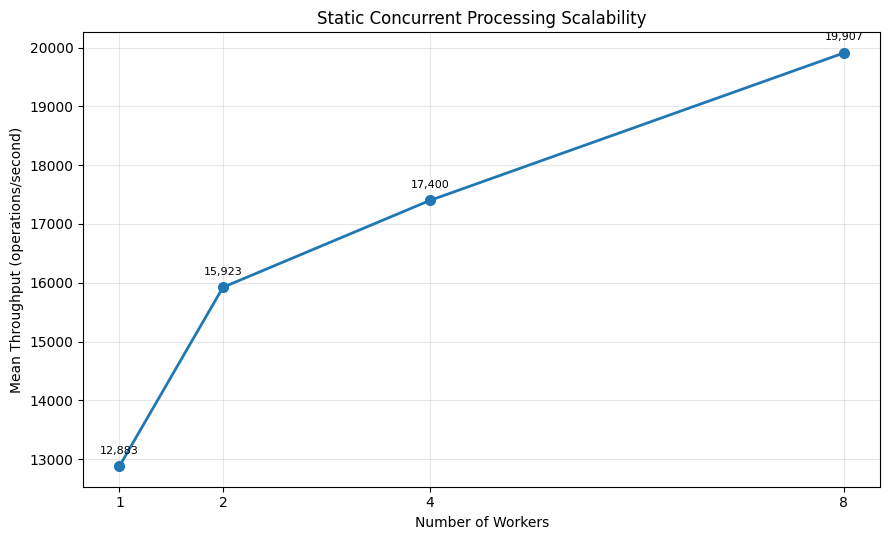

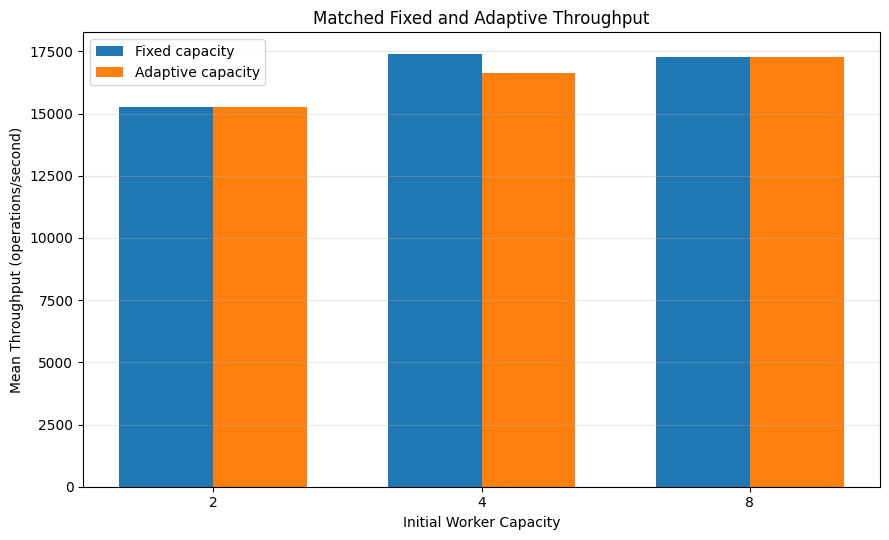

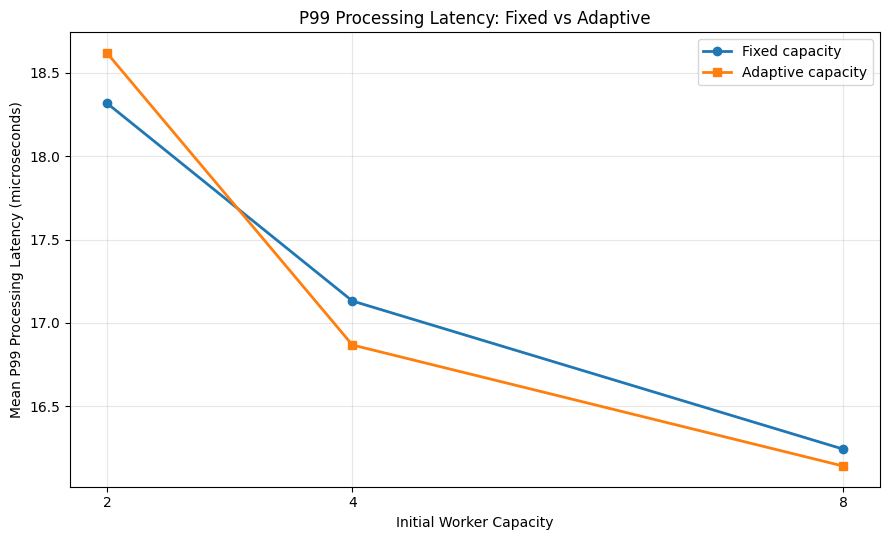

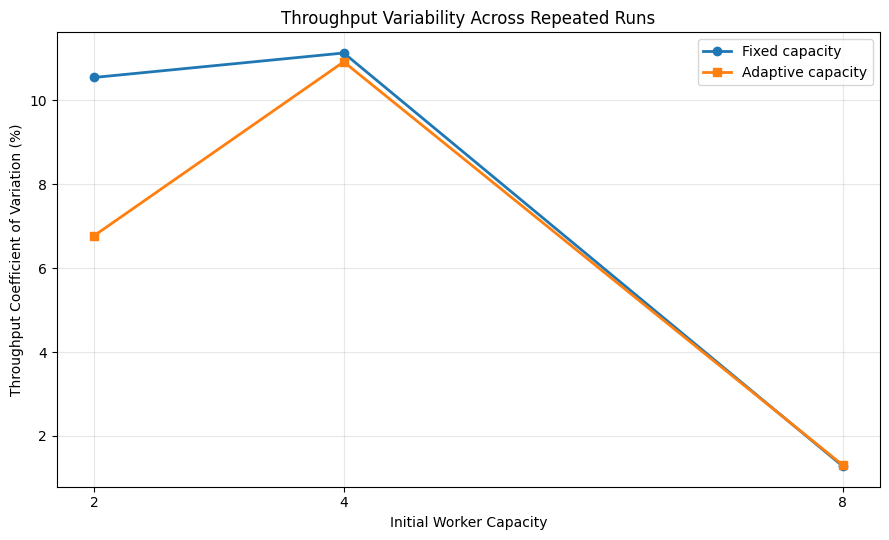

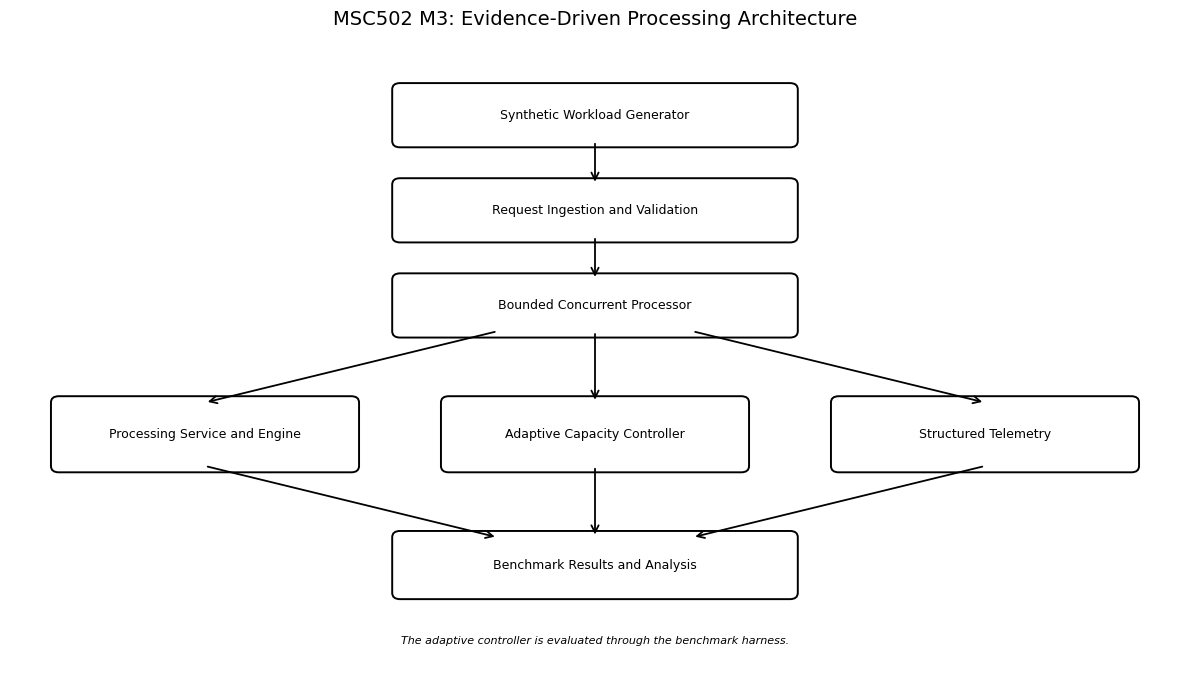

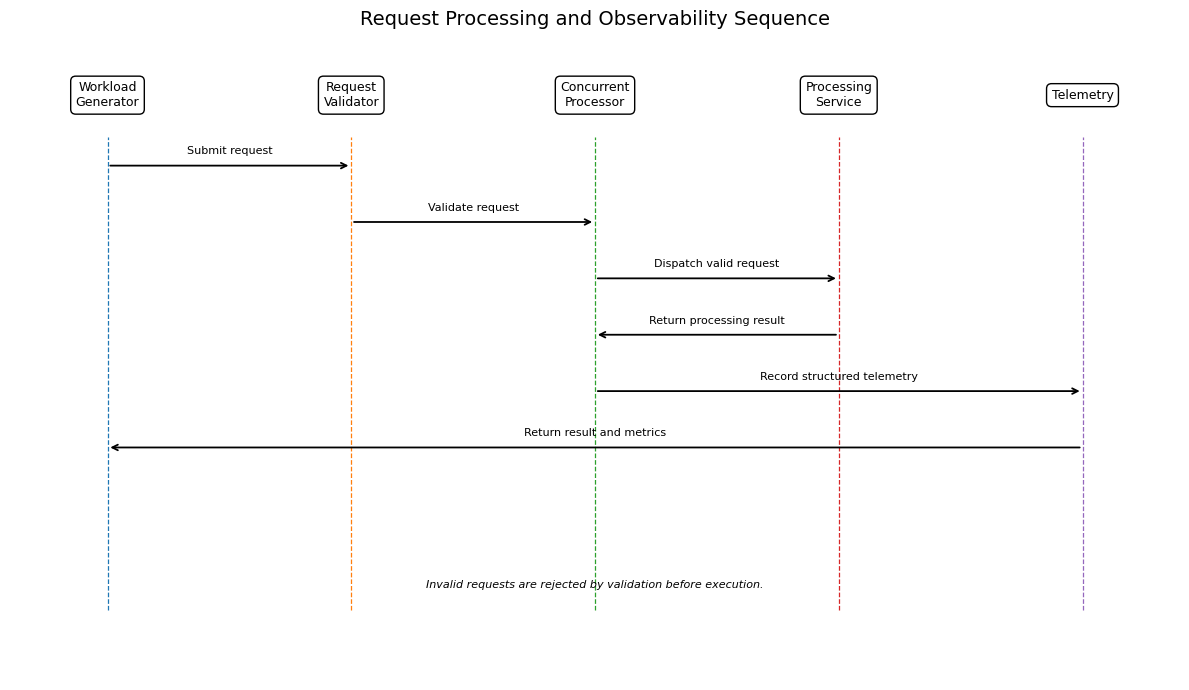


FINAL FIGURE AND TABLE VERIFICATION
PASS | Figure_1_Static_Scalability.png | 159,421 bytes
PASS | Figure_2_Fixed_Adaptive_Throughput.png | 118,762 bytes
PASS | Figure_3_P99_Latency.png | 200,996 bytes
PASS | Figure_4_Throughput_Stability.png | 182,697 bytes
PASS | Figure_5_System_Architecture.png | 214,807 bytes
PASS | Figure_6_Processing_Sequence.png | 197,256 bytes

CSV and JSON report tables:
PASS | final_static_scalability.csv
PASS | final_fixed_adaptive_comparison.csv
PASS | final_fixed_adaptive_differences.csv
PASS | final_performance_summary.json

Verified figures: 6 / 6
Static benchmark completed: 60000
Static benchmark failures: 0
Matched benchmark completed: 300000
Matched benchmark failures: 0

FINAL FIGURE GENERATION: PASS

Figure directory: /content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking/reports/figures
Table directory: /content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking/reports/tables

Figure_1_Static_Scalability.png


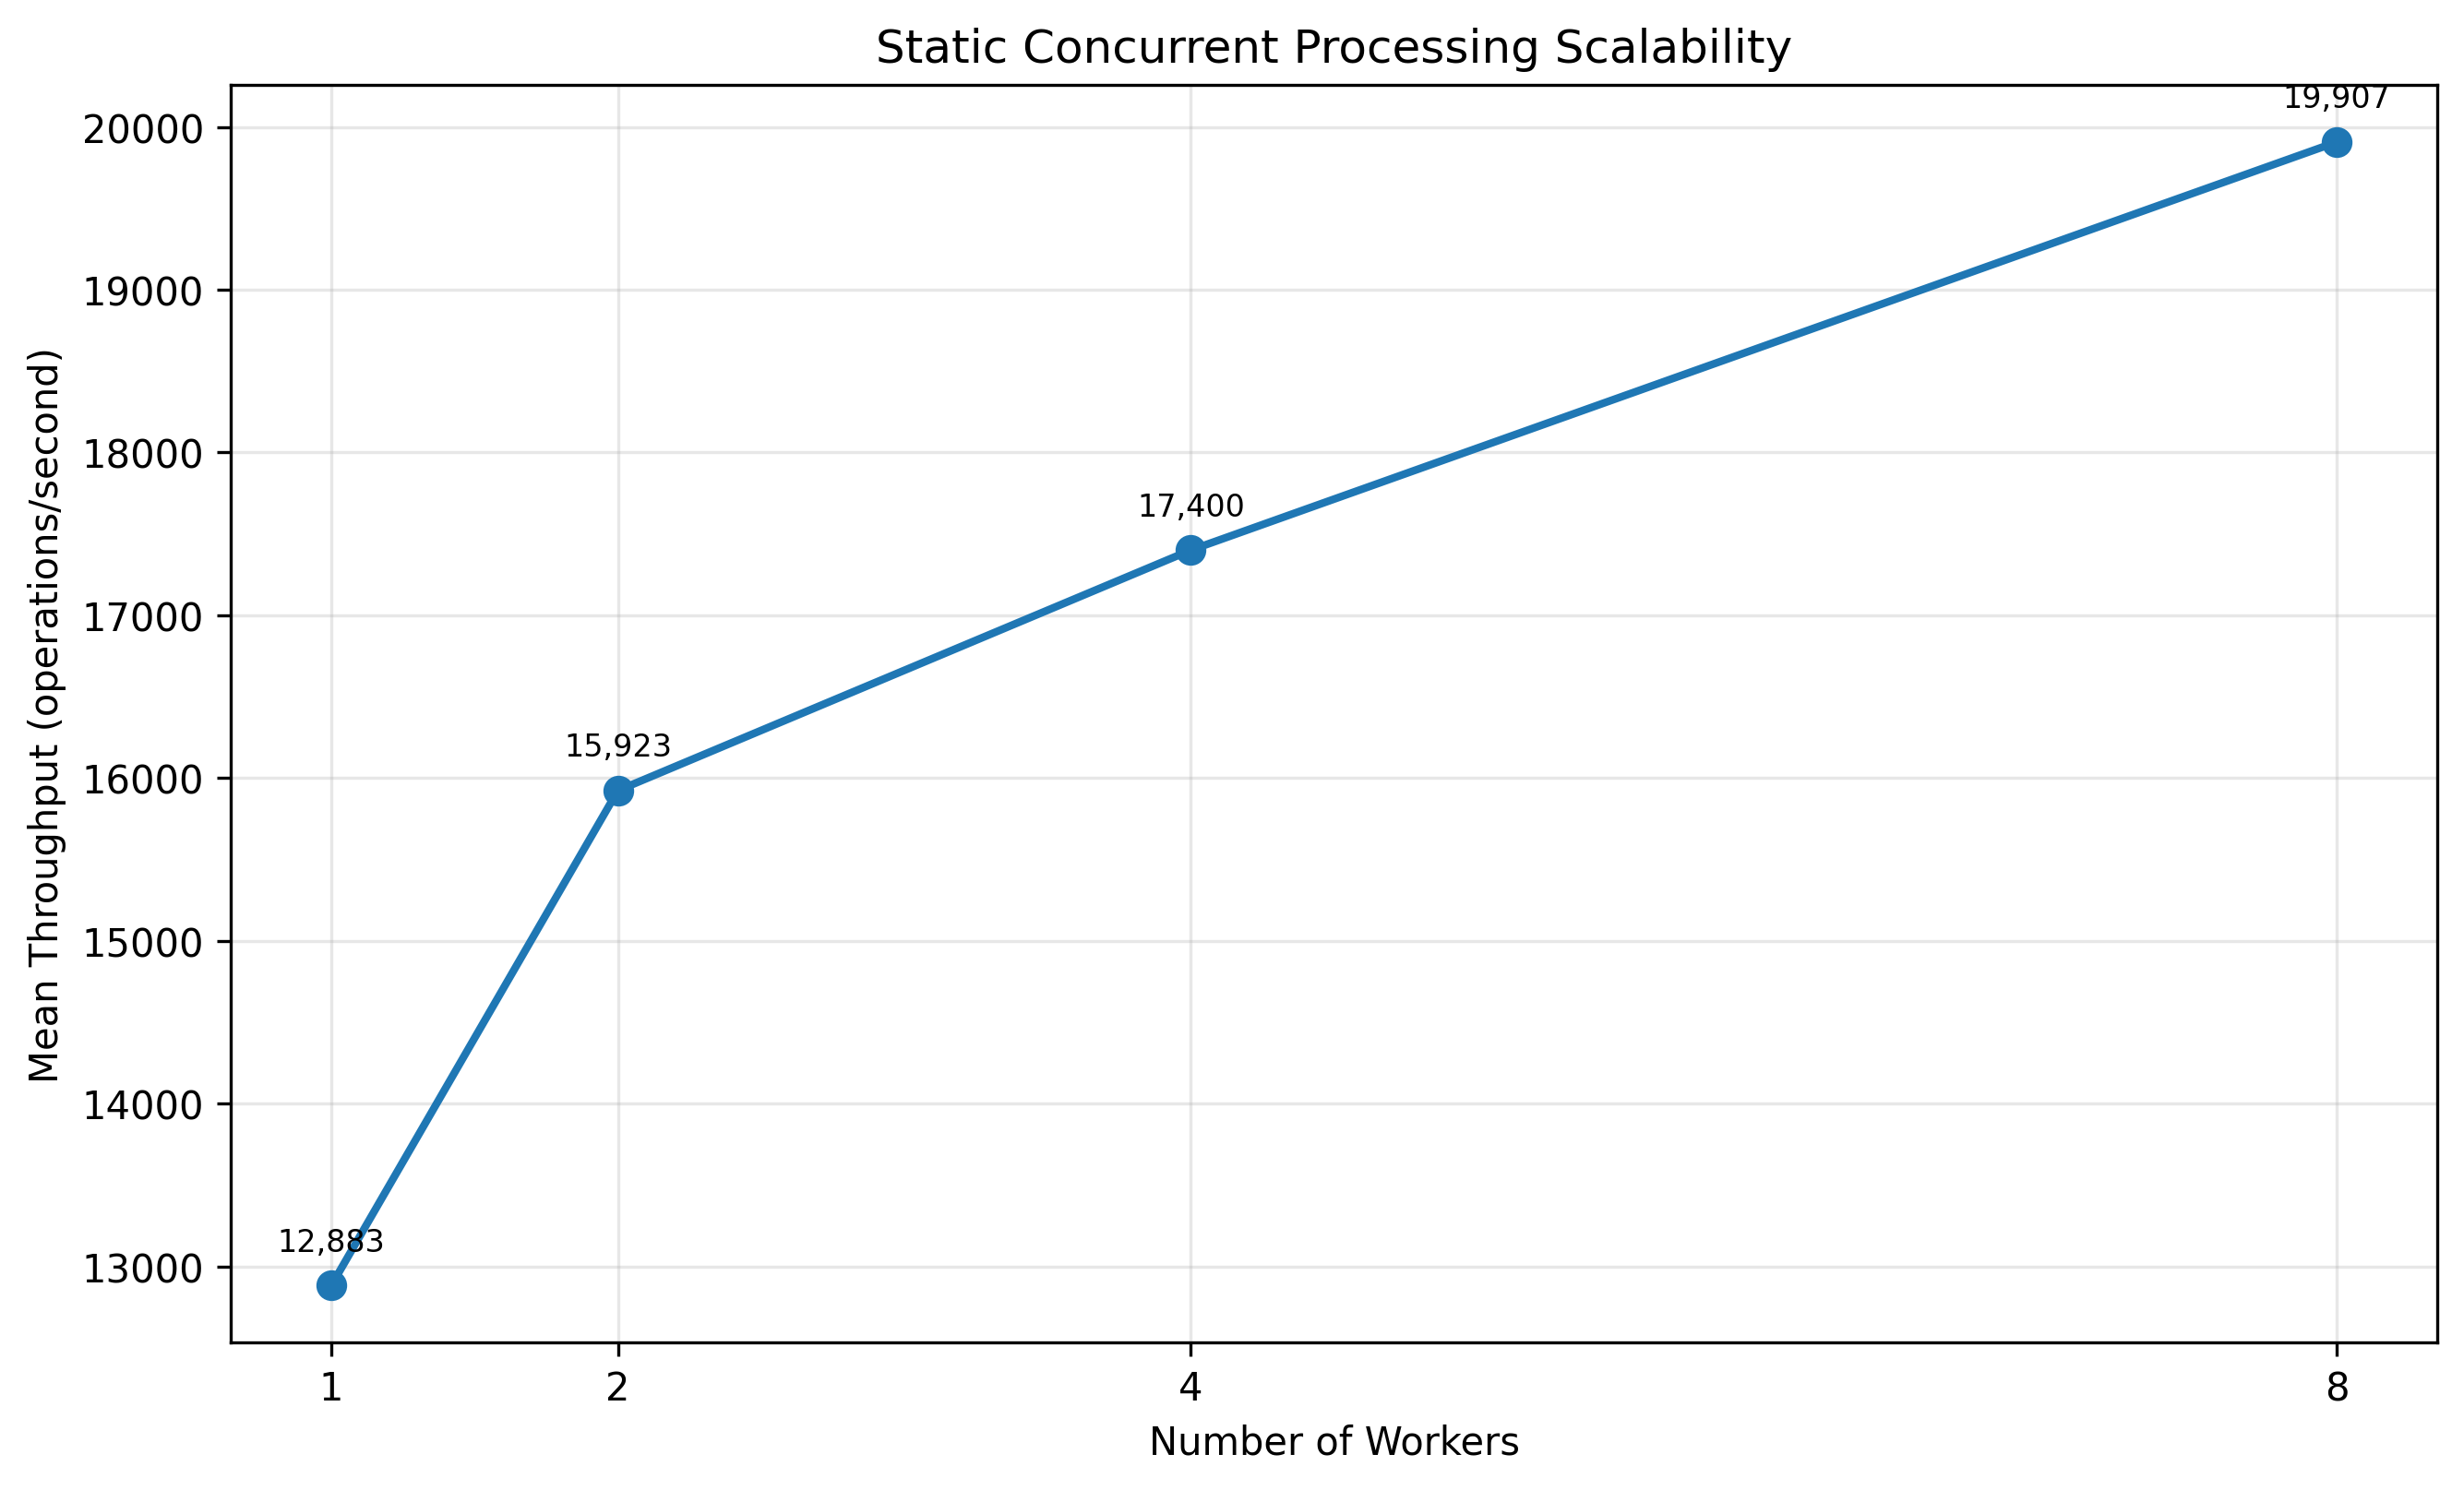


Figure_2_Fixed_Adaptive_Throughput.png


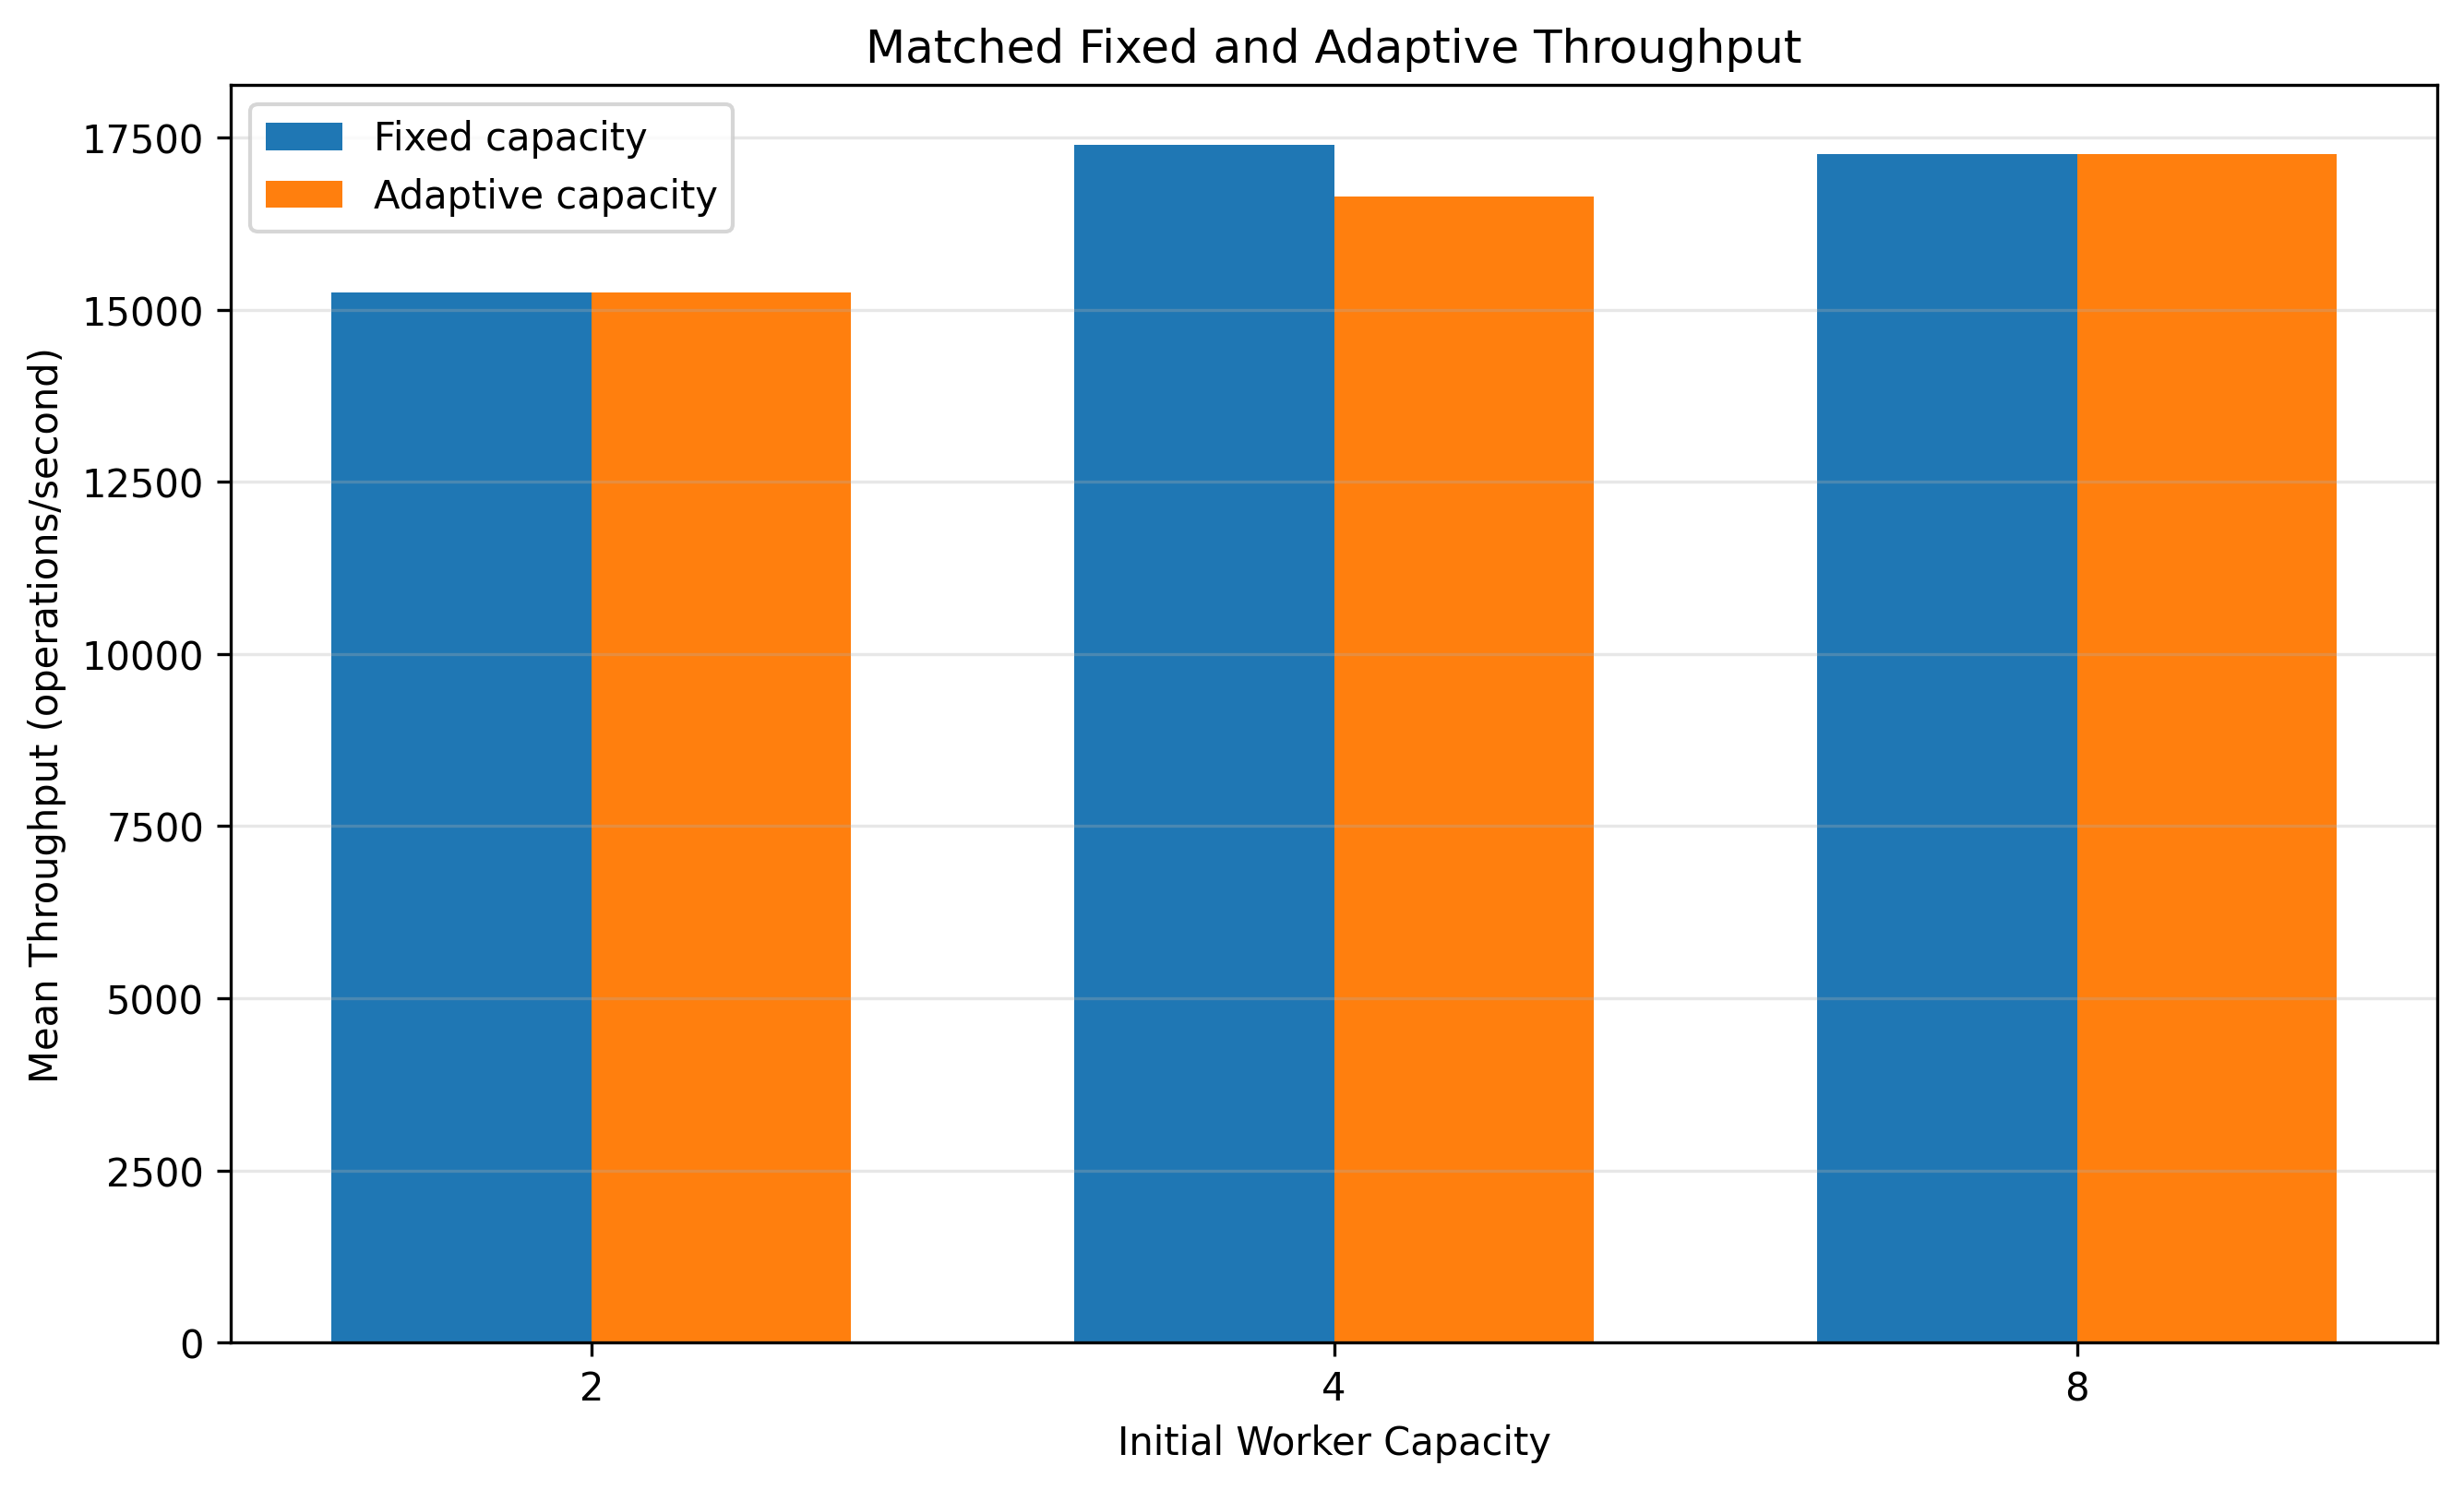


Figure_3_P99_Latency.png


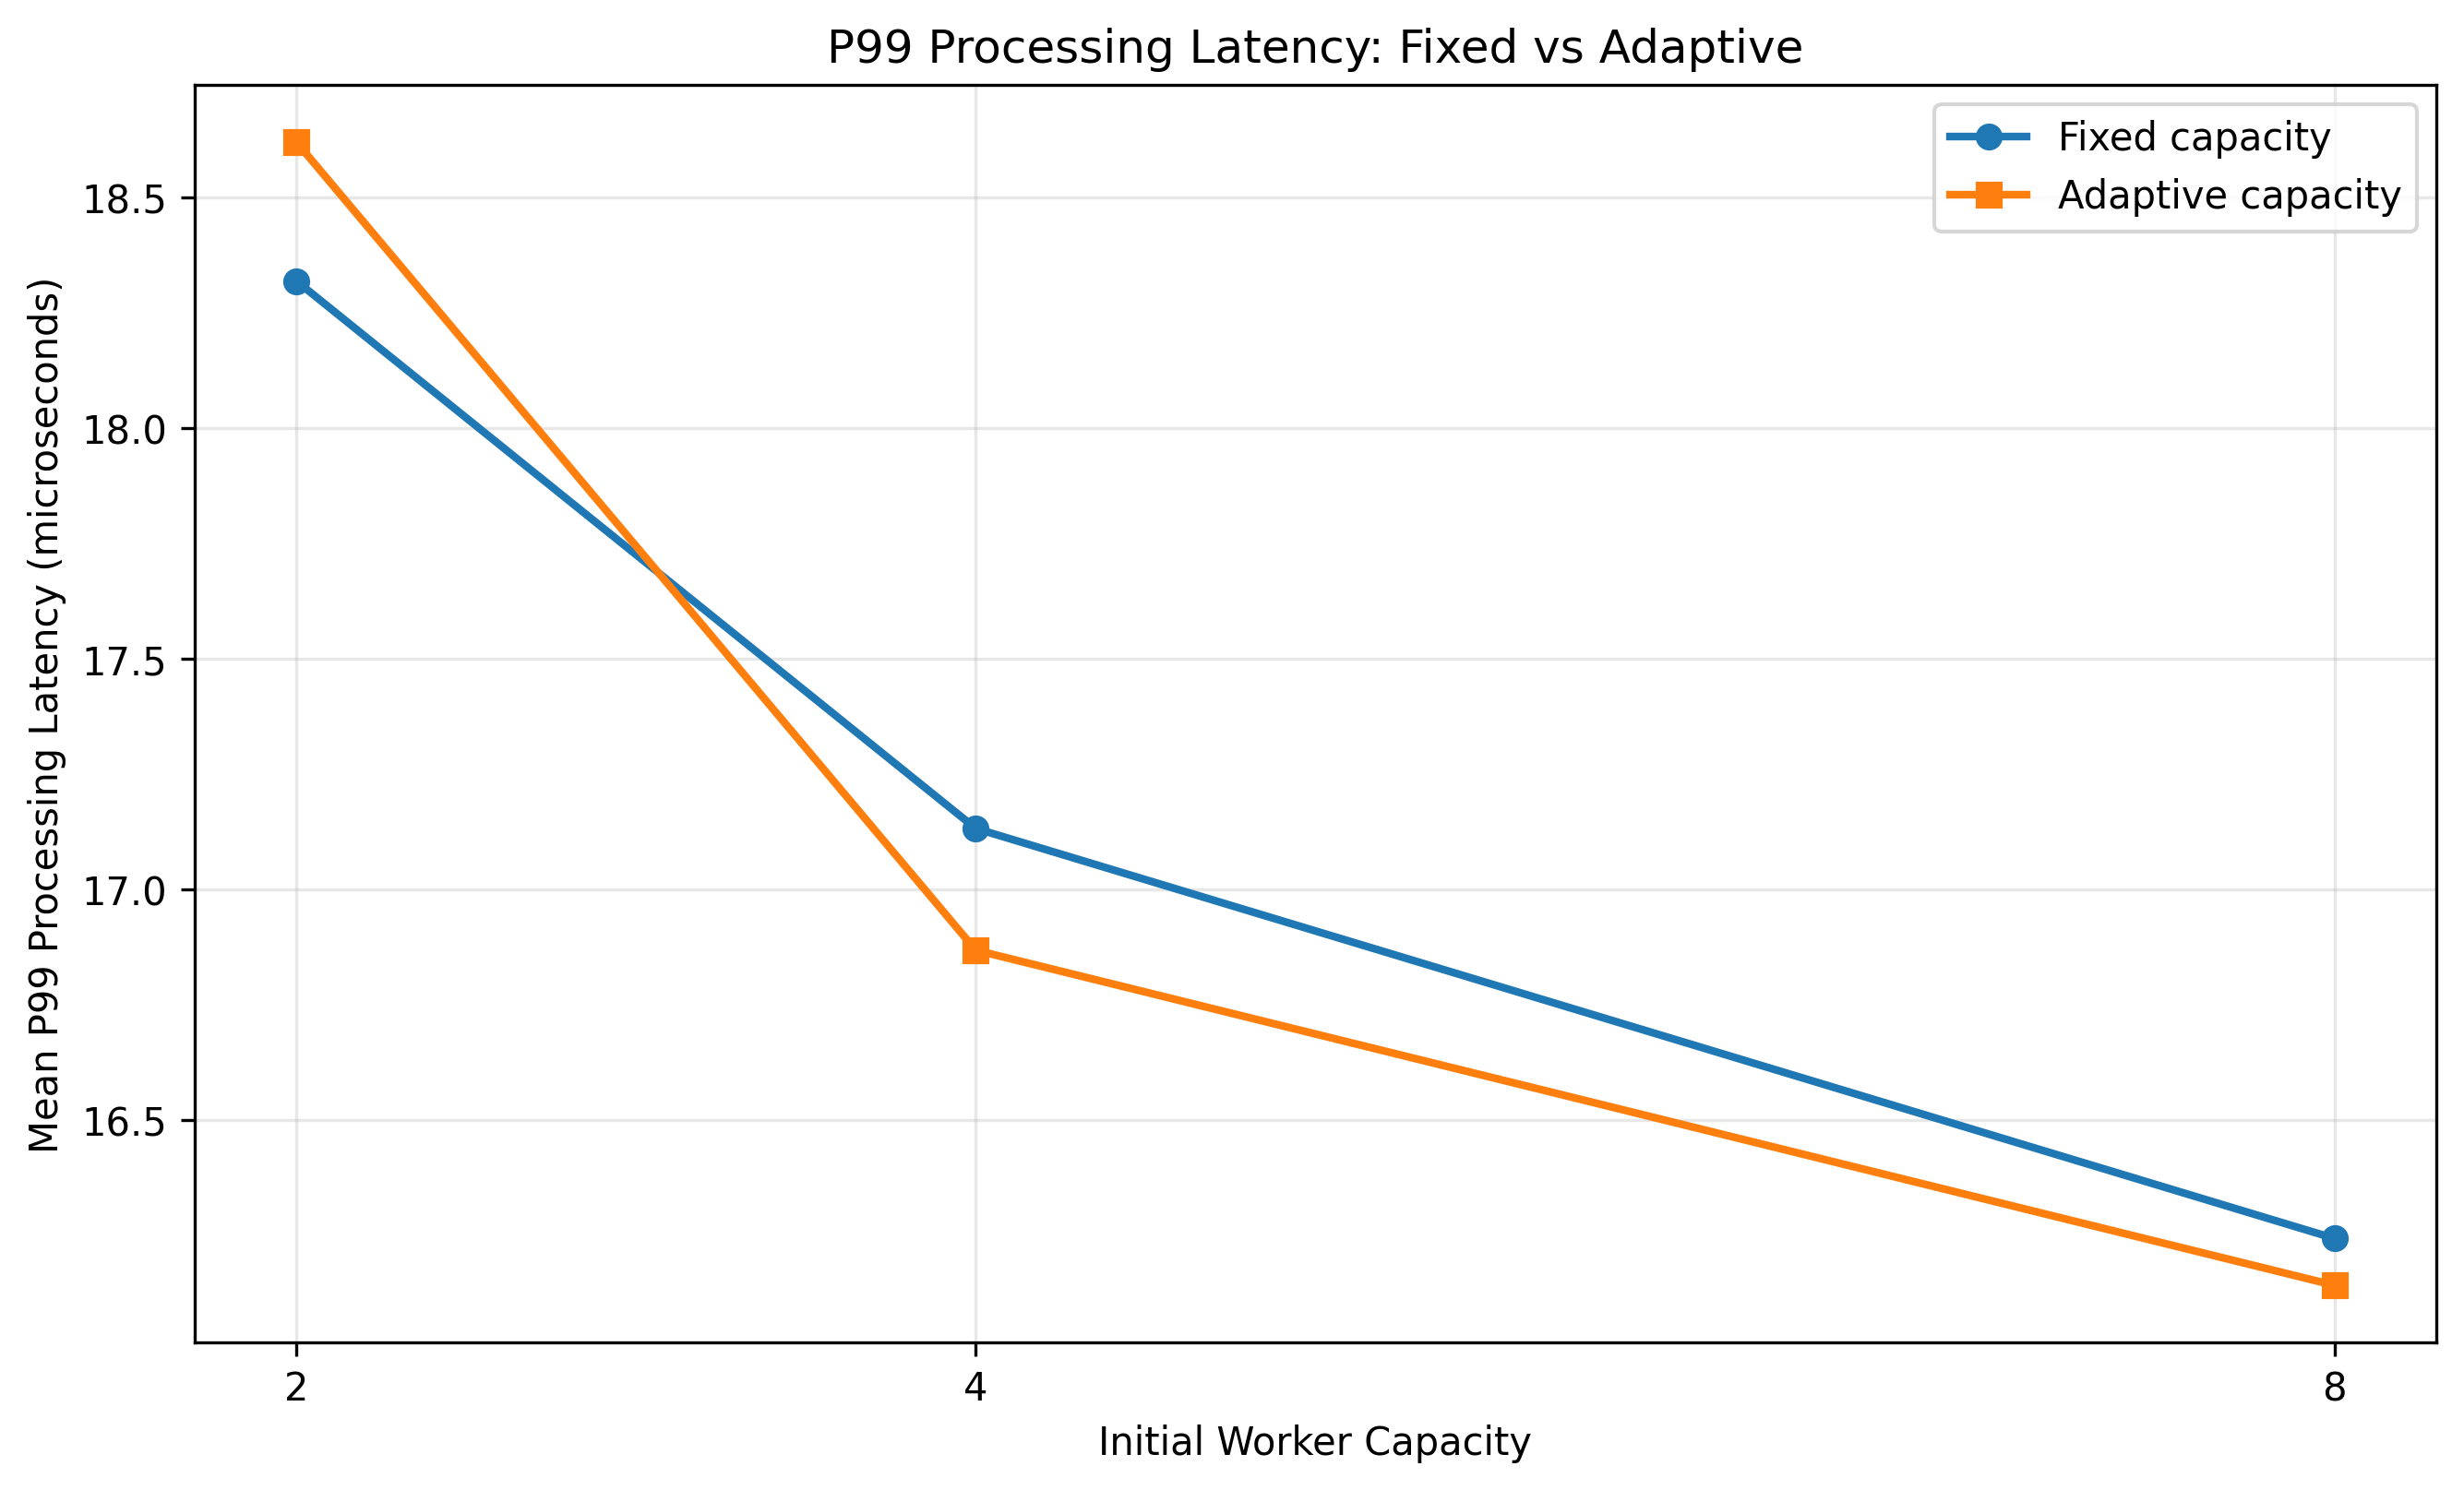


Figure_4_Throughput_Stability.png


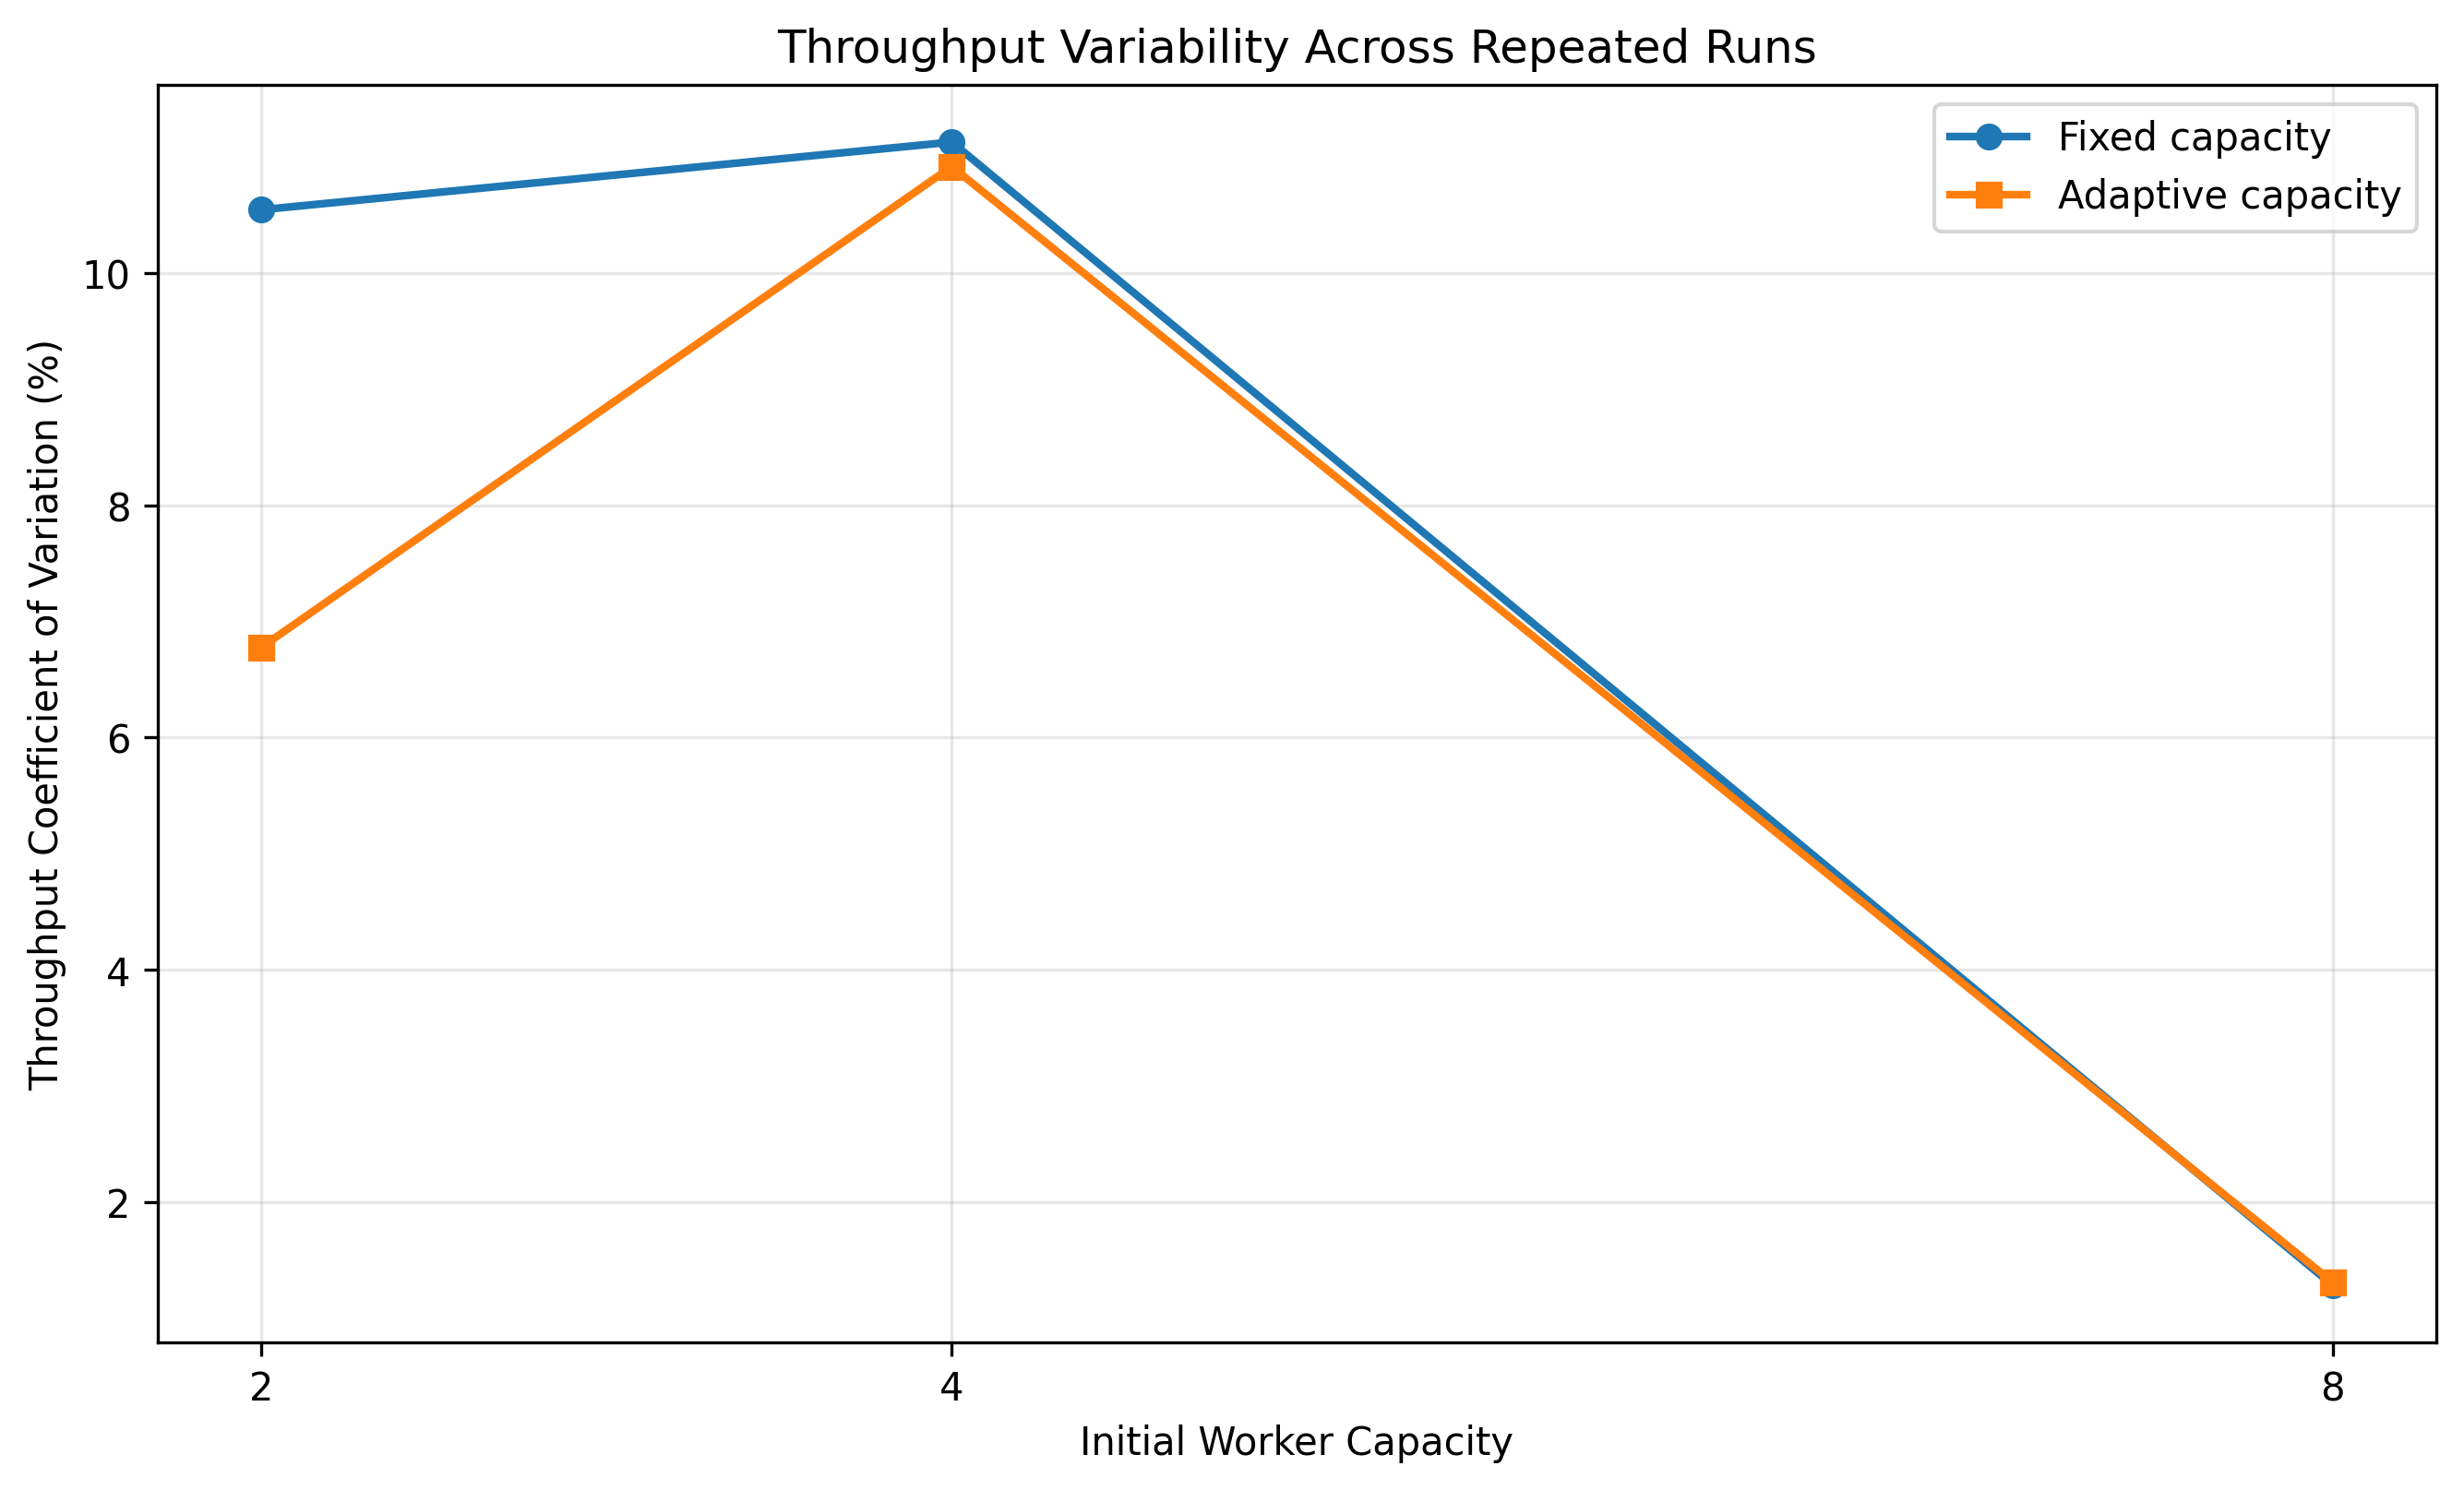


Figure_5_System_Architecture.png


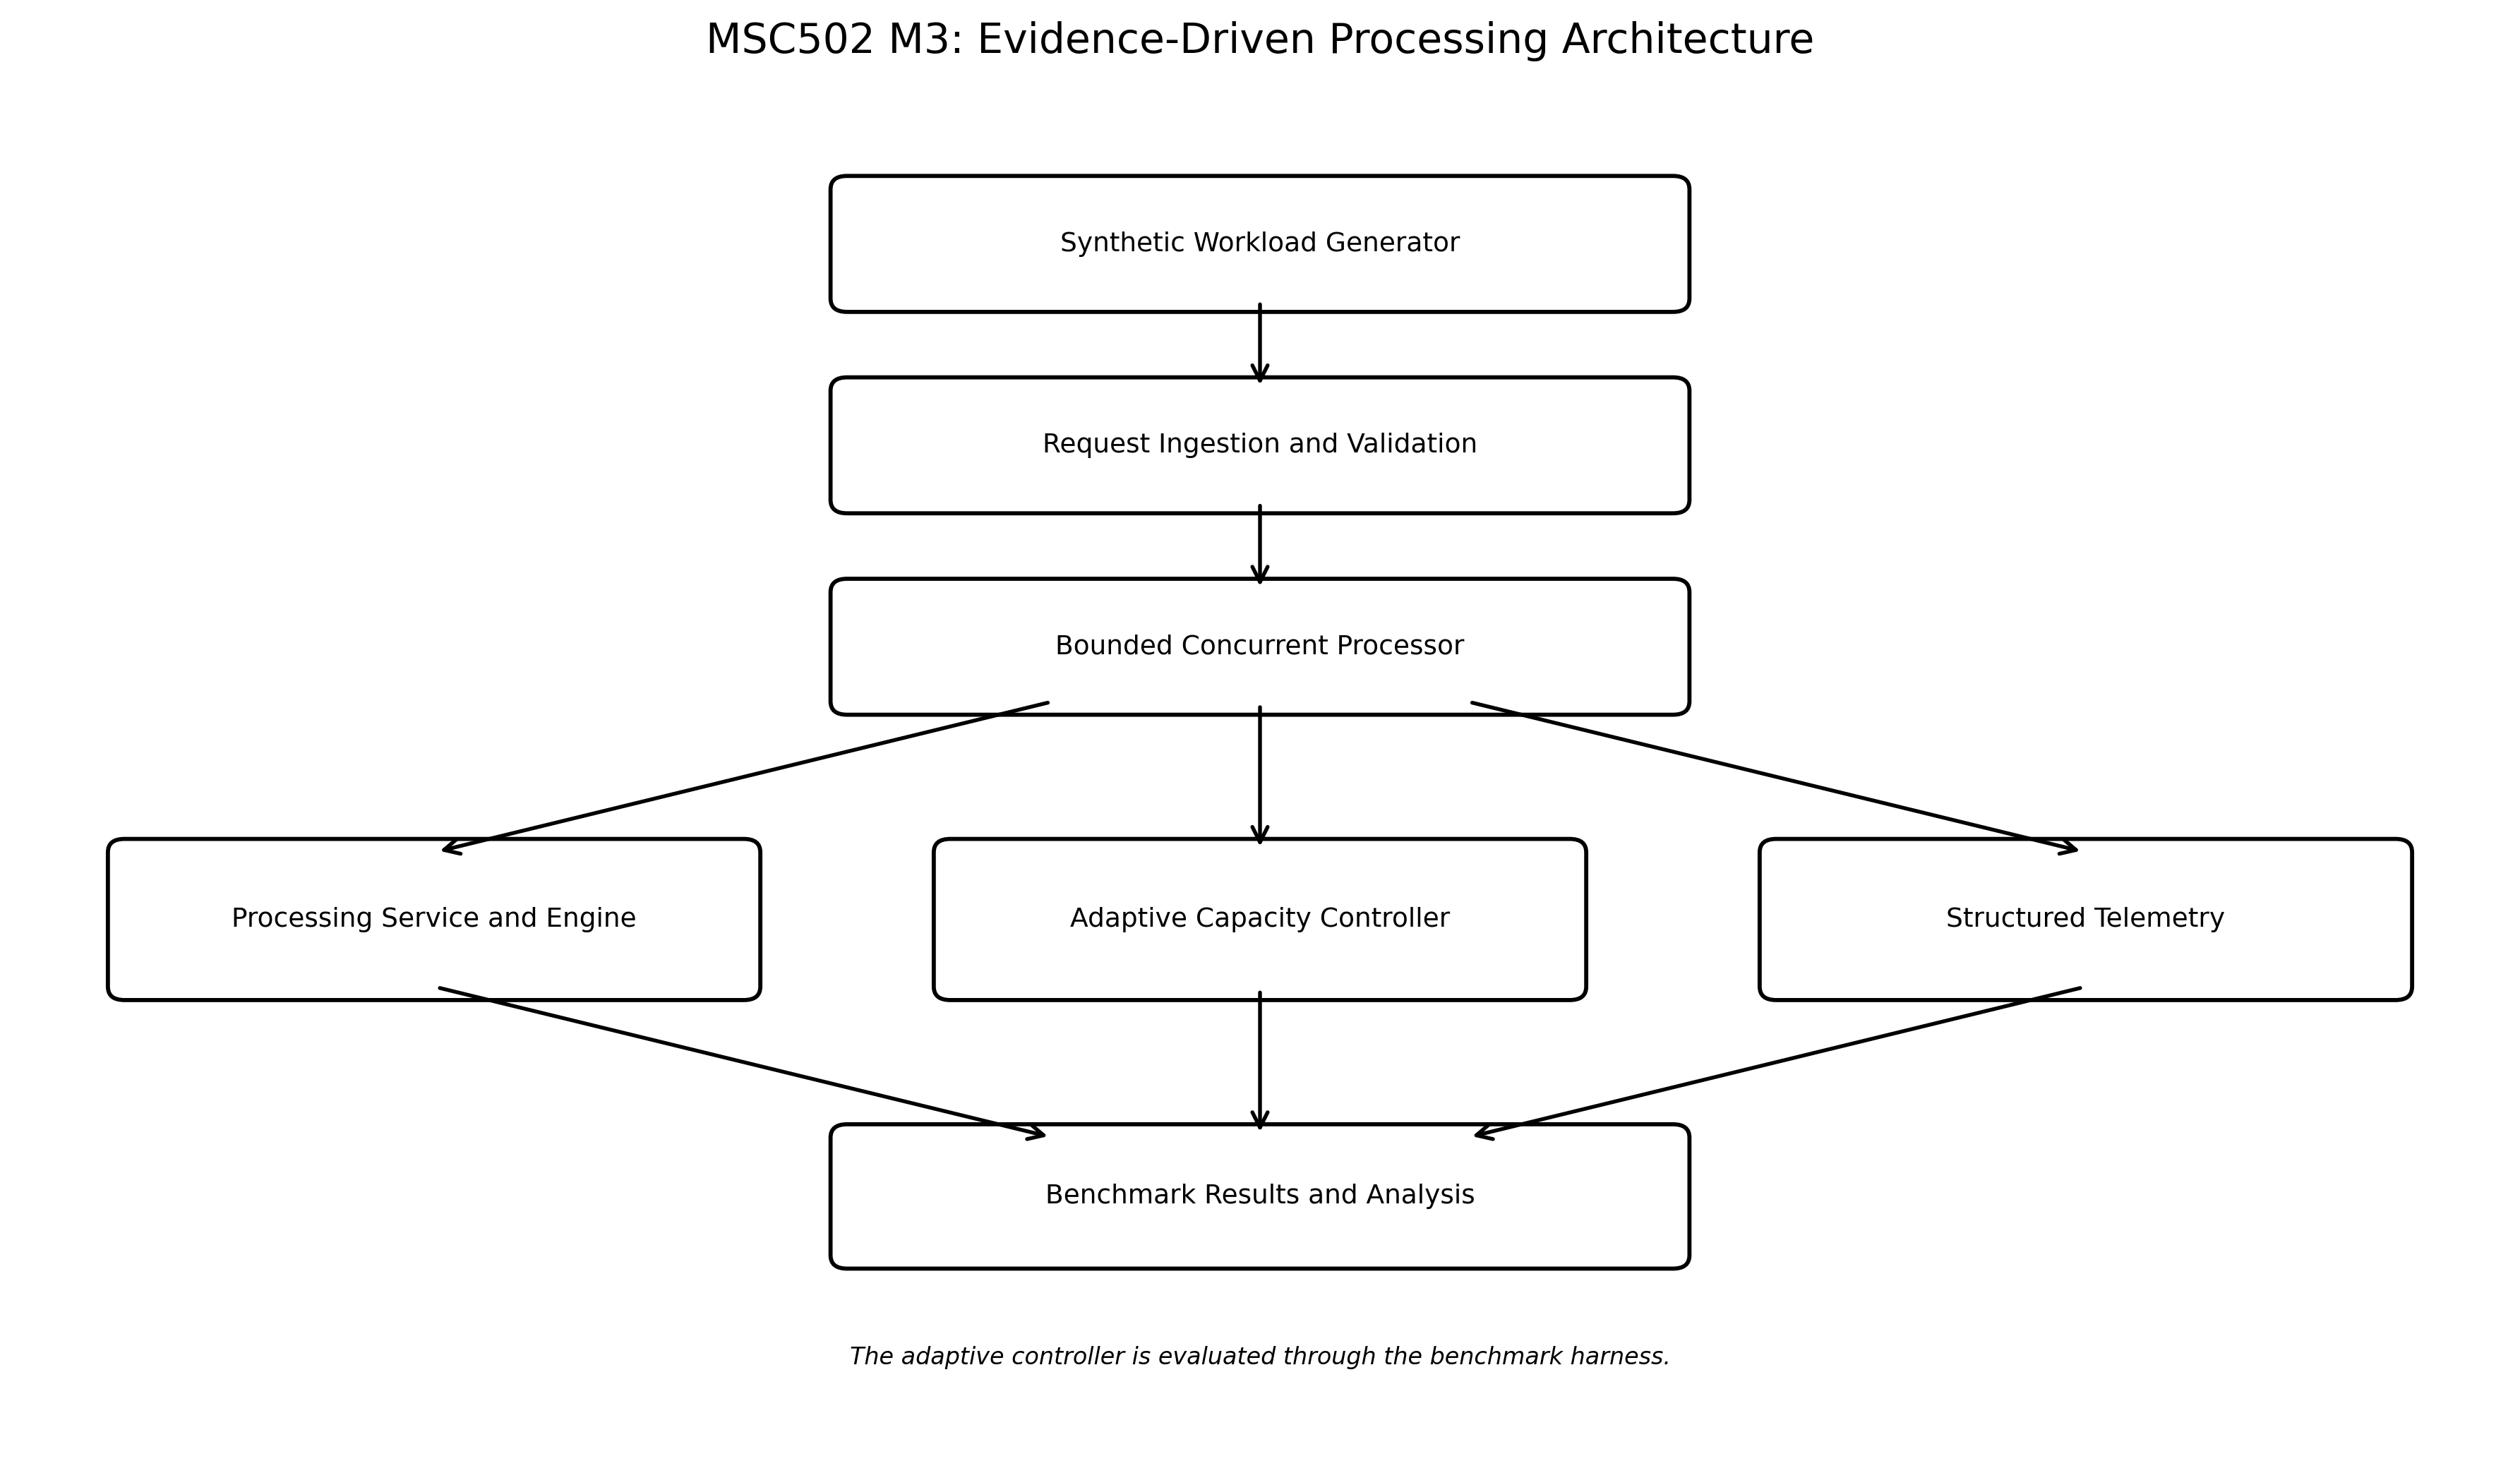


Figure_6_Processing_Sequence.png


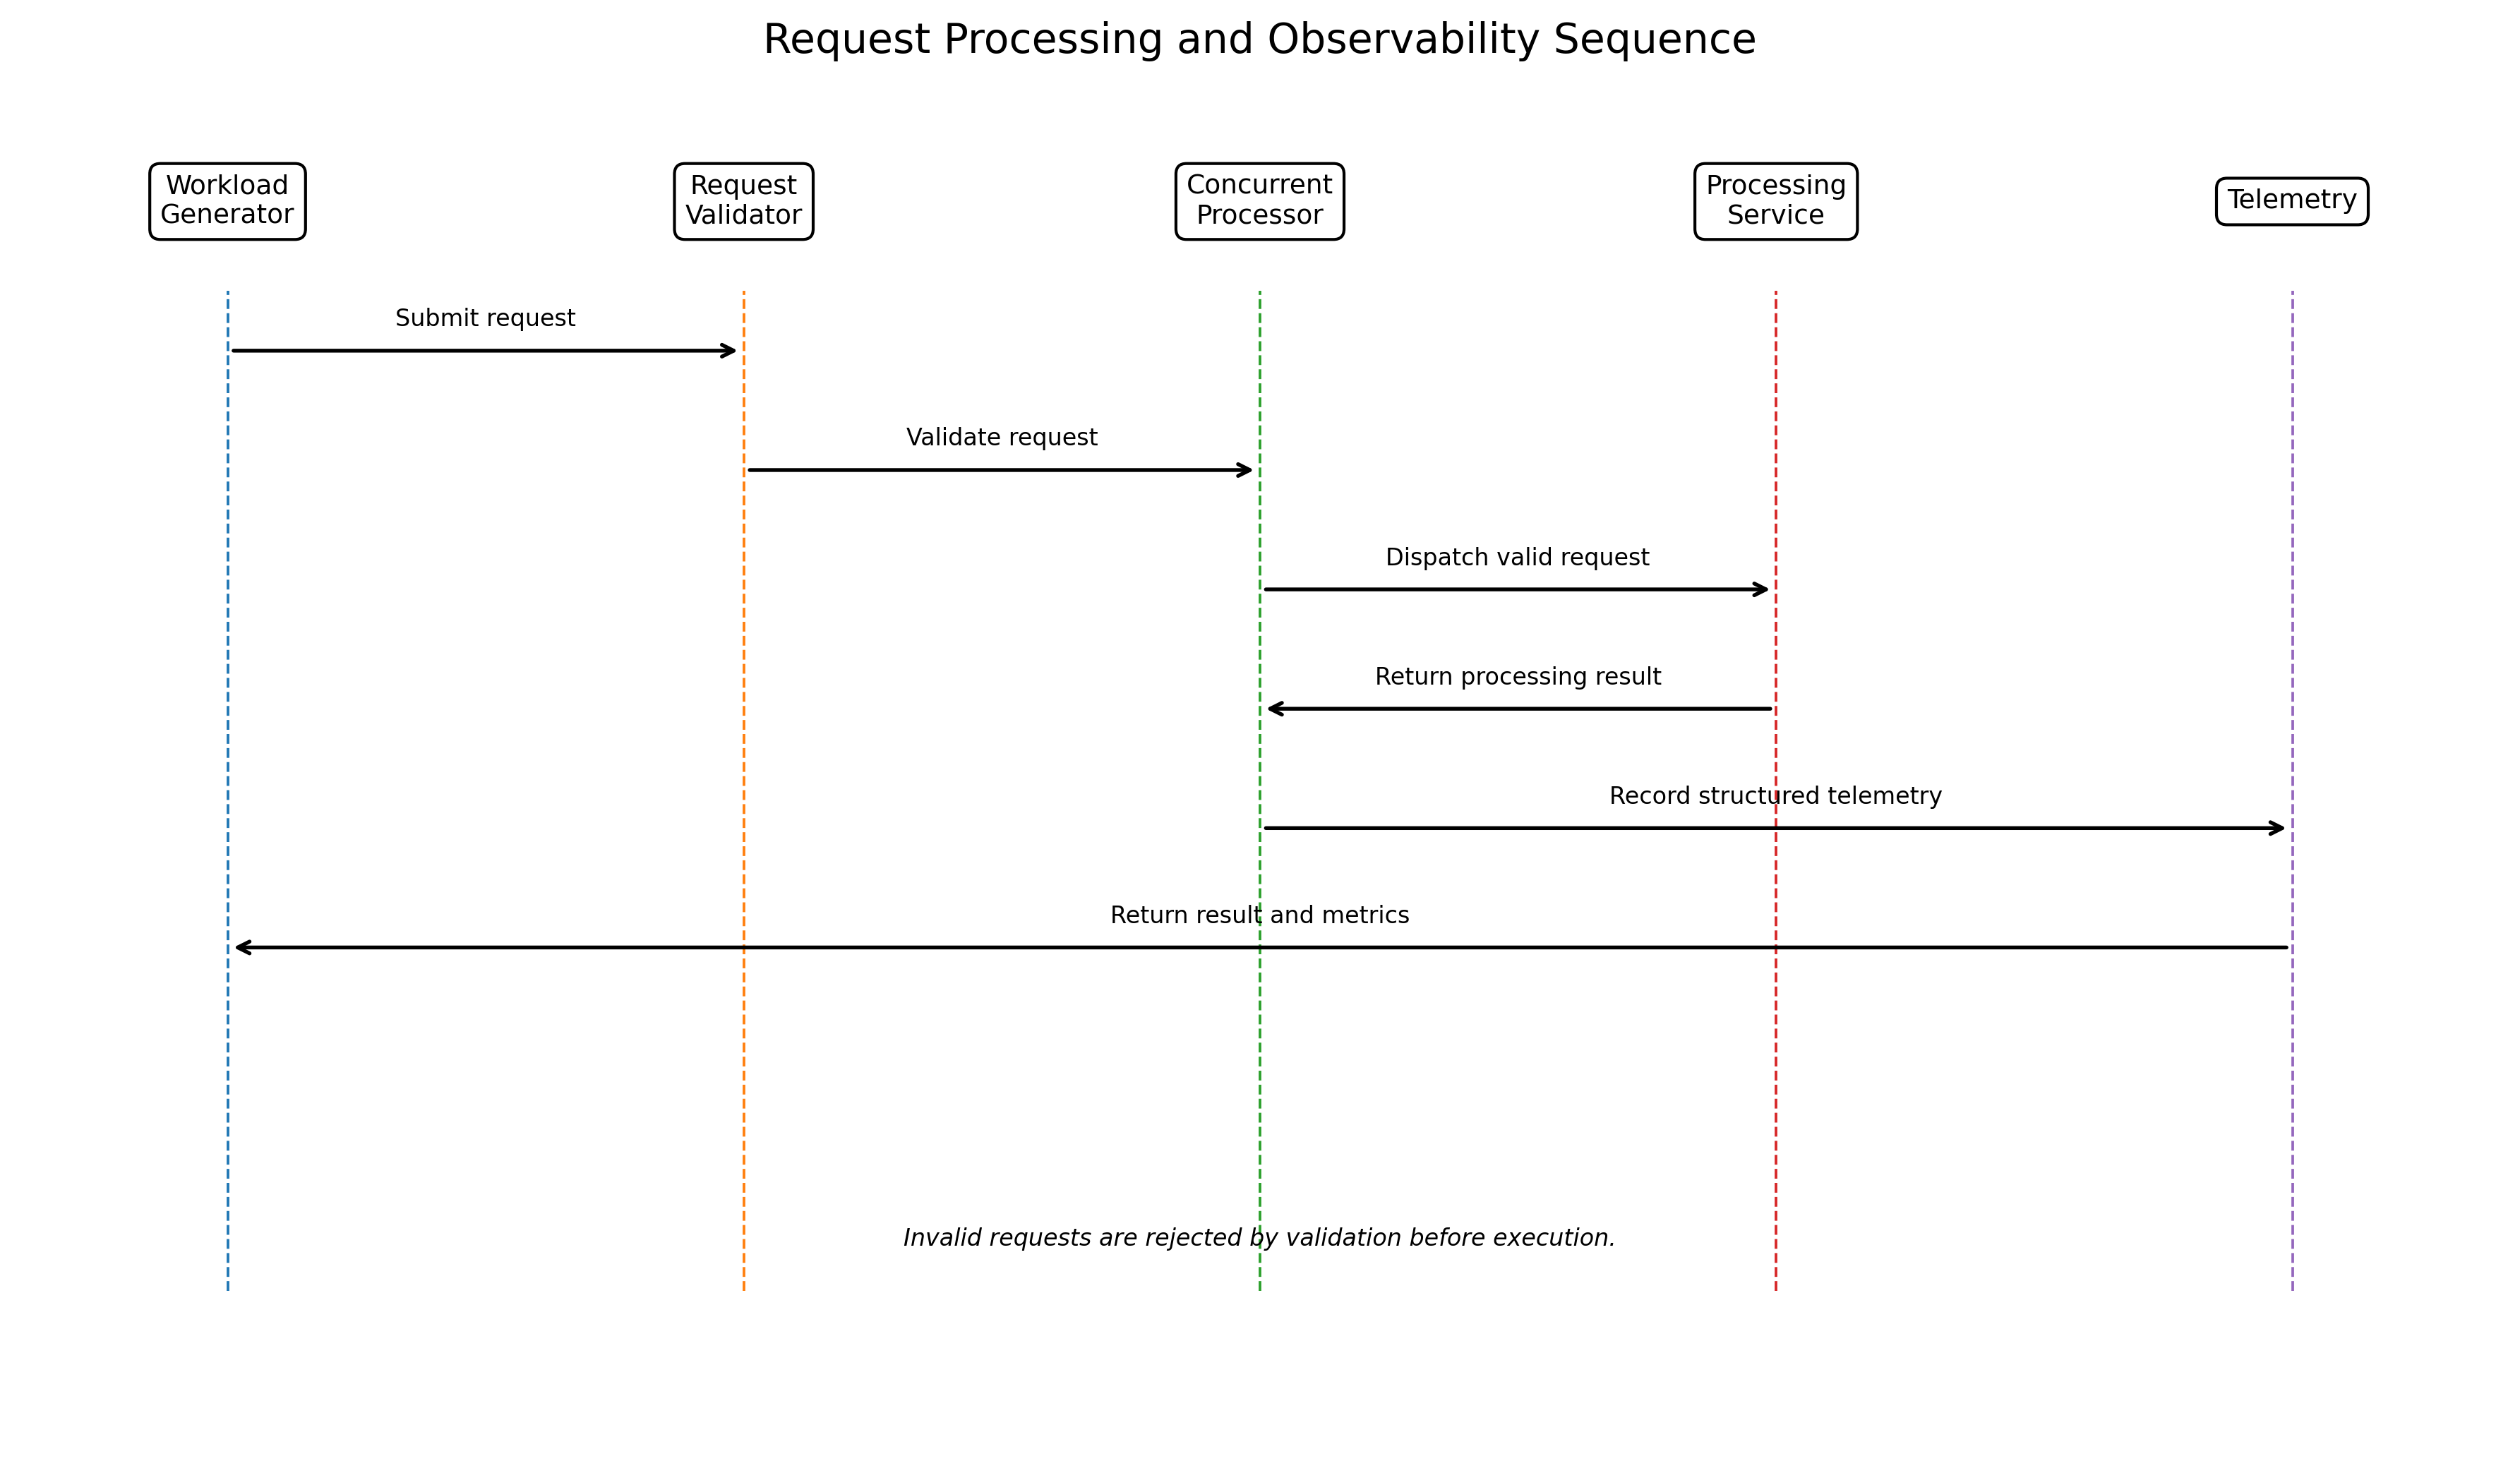

In [79]:

# ============================================================================
# MSC502 M3: FINAL VERIFIED REPORT FIGURES
# Six figures, two CSV tables and a JSON performance summary.
# Data source: existing saved benchmark results only.
# Environment: Google Colab.
# ============================================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython.display import display, Image

# ============================================================================
# 1. PATHS AND INPUT VALIDATION
# ============================================================================

ROOT = Path(
    "/content/MSC502-M3-Evidence-Driven-Resilience-Benchmarking"
)

RAW = ROOT / "results" / "raw"
FIGURES = ROOT / "reports" / "figures"
TABLES = ROOT / "reports" / "tables"

FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

STATIC_FILE = RAW / "static_baseline.json"
MATCHED_FILE = RAW / "matched_fixed_vs_adaptive_10reps.json"

for path in [STATIC_FILE, MATCHED_FILE]:
    if not path.exists():
        raise FileNotFoundError(f"Missing benchmark input: {path}")

with open(STATIC_FILE, "r", encoding="utf-8") as f:
    static_data = json.load(f)

with open(MATCHED_FILE, "r", encoding="utf-8") as f:
    matched_data = json.load(f)

# Use the actual schema established by the diagnostic output.
static_raw = static_data["raw_results"]
static_saved_summary = static_data["summary"]

matched_raw = matched_data["raw_results"]
matched_saved_summary = matched_data["summary"]

if not static_raw or not static_saved_summary:
    raise ValueError("Static benchmark data is empty.")

if not matched_raw or not matched_saved_summary:
    raise ValueError("Matched benchmark data is empty.")

print("=" * 78)
print("MSC502 M3 FINAL FIGURE GENERATION")
print("=" * 78)
print("Project:", ROOT)
print("Static benchmark runs:", len(static_raw))
print("Static summary groups:", len(static_saved_summary))
print("Matched benchmark runs:", len(matched_raw))
print("Matched summary groups:", len(matched_saved_summary))
print("Input validation: PASS")

# ============================================================================
# 2. BUILD DATAFRAMES FROM SAVED SUMMARY RECORDS
# ============================================================================

static_df = pd.DataFrame(static_saved_summary).sort_values("workers")

matched_df = pd.DataFrame(matched_saved_summary).copy()

matched_df["strategy"] = (
    matched_df["strategy"].astype(str).str.lower()
)

matched_df = matched_df.sort_values(
    ["initial_workers", "strategy"]
)

required_static = {
    "workers",
    "mean_throughput_ops_per_sec",
    "median_throughput_ops_per_sec",
    "throughput_stdev",
    "mean_successful",
    "mean_failed",
}

required_matched = {
    "initial_workers",
    "strategy",
    "mean_throughput_ops_per_sec",
    "throughput_stdev",
    "throughput_cv_percent",
    "mean_p99_processing_latency_us",
    "total_capacity_changes",
    "total_completed",
    "total_failed",
}

if not required_static.issubset(static_df.columns):
    raise ValueError(
        "Unexpected static summary schema: "
        + str(static_df.columns.tolist())
    )

if not required_matched.issubset(matched_df.columns):
    raise ValueError(
        "Unexpected matched summary schema: "
        + str(matched_df.columns.tolist())
    )

print("\nStatic summary data: PASS")
print("Matched summary data: PASS")

# ============================================================================
# 3. CALCULATE FINAL COMPARISON METRICS
# ============================================================================

fixed = (
    matched_df[matched_df["strategy"] == "fixed"]
    .set_index("initial_workers")
)

adaptive = (
    matched_df[matched_df["strategy"] == "adaptive"]
    .set_index("initial_workers")
)

common_workers = sorted(
    set(fixed.index).intersection(set(adaptive.index))
)

if not common_workers:
    raise ValueError("No matching fixed/adaptive worker configurations.")

comparison_rows = []

for workers in common_workers:
    f = fixed.loc[workers]
    a = adaptive.loc[workers]

    throughput_change = (
        (a["mean_throughput_ops_per_sec"] /
         f["mean_throughput_ops_per_sec"]) - 1
    ) * 100

    p99_change = (
        (a["mean_p99_processing_latency_us"] /
         f["mean_p99_processing_latency_us"]) - 1
    ) * 100

    comparison_rows.append({
        "workers": int(workers),
        "fixed_mean_throughput_ops_per_sec":
            float(f["mean_throughput_ops_per_sec"]),
        "adaptive_mean_throughput_ops_per_sec":
            float(a["mean_throughput_ops_per_sec"]),
        "throughput_change_percent":
            float(throughput_change),
        "fixed_mean_p99_us":
            float(f["mean_p99_processing_latency_us"]),
        "adaptive_mean_p99_us":
            float(a["mean_p99_processing_latency_us"]),
        "p99_change_percent":
            float(p99_change),
        "fixed_throughput_cv_percent":
            float(f["throughput_cv_percent"]),
        "adaptive_throughput_cv_percent":
            float(a["throughput_cv_percent"]),
        "adaptive_capacity_changes":
            int(a["total_capacity_changes"]),
        "fixed_completed":
            int(f["total_completed"]),
        "adaptive_completed":
            int(a["total_completed"]),
        "fixed_failed":
            int(f["total_failed"]),
        "adaptive_failed":
            int(a["total_failed"]),
    })

comparison_df = pd.DataFrame(comparison_rows)

print("\nSTATIC SCALABILITY SUMMARY")
display(static_df.round(3))

print("\nMATCHED FIXED VS ADAPTIVE SUMMARY")
display(matched_df.round(3))

print("\nCALCULATED PERFORMANCE DIFFERENCES")
display(comparison_df.round(4))

# ============================================================================
# 4. SAVE REPORT TABLES
# ============================================================================

static_output = static_df.copy()

static_output["speedup"] = (
    static_output["mean_throughput_ops_per_sec"] /
    static_output.loc[
        static_output["workers"] == 1,
        "mean_throughput_ops_per_sec"
    ].iloc[0]
)

static_output["parallel_efficiency_percent"] = (
    static_output["speedup"] /
    static_output["workers"] * 100
)

static_output.to_csv(
    TABLES / "final_static_scalability.csv",
    index=False
)

matched_df.to_csv(
    TABLES / "final_fixed_adaptive_comparison.csv",
    index=False
)

comparison_df.to_csv(
    TABLES / "final_fixed_adaptive_differences.csv",
    index=False
)

# ============================================================================
# 5. FIGURE 1: STATIC CONCURRENT SCALABILITY
# ============================================================================

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.plot(
    static_df["workers"],
    static_df["mean_throughput_ops_per_sec"],
    marker="o",
    linewidth=2,
    markersize=7
)

ax.set_title("Static Concurrent Processing Scalability")
ax.set_xlabel("Number of Workers")
ax.set_ylabel("Mean Throughput (operations/second)")
ax.set_xticks(static_df["workers"])
ax.grid(True, alpha=0.3)

for _, row in static_df.iterrows():
    ax.annotate(
        f'{row["mean_throughput_ops_per_sec"]:,.0f}',
        (
            row["workers"],
            row["mean_throughput_ops_per_sec"]
        ),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=8
    )

fig.tight_layout()
fig.savefig(
    FIGURES / "Figure_1_Static_Scalability.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ============================================================================
# 6. FIGURE 2: FIXED VS ADAPTIVE THROUGHPUT
# ============================================================================

x = np.arange(len(common_workers))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.bar(
    x - width / 2,
    [
        fixed.loc[w, "mean_throughput_ops_per_sec"]
        for w in common_workers
    ],
    width,
    label="Fixed capacity"
)

ax.bar(
    x + width / 2,
    [
        adaptive.loc[w, "mean_throughput_ops_per_sec"]
        for w in common_workers
    ],
    width,
    label="Adaptive capacity"
)

ax.set_title("Matched Fixed and Adaptive Throughput")
ax.set_xlabel("Initial Worker Capacity")
ax.set_ylabel("Mean Throughput (operations/second)")
ax.set_xticks(x)
ax.set_xticklabels(common_workers)
ax.grid(axis="y", alpha=0.3)
ax.legend()

fig.tight_layout()
fig.savefig(
    FIGURES / "Figure_2_Fixed_Adaptive_Throughput.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ============================================================================
# 7. FIGURE 3: P99 PROCESSING LATENCY
# ============================================================================

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.plot(
    common_workers,
    [
        fixed.loc[w, "mean_p99_processing_latency_us"]
        for w in common_workers
    ],
    marker="o",
    linewidth=2,
    label="Fixed capacity"
)

ax.plot(
    common_workers,
    [
        adaptive.loc[w, "mean_p99_processing_latency_us"]
        for w in common_workers
    ],
    marker="s",
    linewidth=2,
    label="Adaptive capacity"
)

ax.set_title("P99 Processing Latency: Fixed vs Adaptive")
ax.set_xlabel("Initial Worker Capacity")
ax.set_ylabel("Mean P99 Processing Latency (microseconds)")
ax.set_xticks(common_workers)
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()
fig.savefig(
    FIGURES / "Figure_3_P99_Latency.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ============================================================================
# 8. FIGURE 4: THROUGHPUT STABILITY
# Lower coefficient of variation indicates greater stability.
# ============================================================================

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.plot(
    common_workers,
    [
        fixed.loc[w, "throughput_cv_percent"]
        for w in common_workers
    ],
    marker="o",
    linewidth=2,
    label="Fixed capacity"
)

ax.plot(
    common_workers,
    [
        adaptive.loc[w, "throughput_cv_percent"]
        for w in common_workers
    ],
    marker="s",
    linewidth=2,
    label="Adaptive capacity"
)

ax.set_title("Throughput Variability Across Repeated Runs")
ax.set_xlabel("Initial Worker Capacity")
ax.set_ylabel("Throughput Coefficient of Variation (%)")
ax.set_xticks(common_workers)
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()
fig.savefig(
    FIGURES / "Figure_4_Throughput_Stability.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ============================================================================
# 9. FIGURE 5: SYSTEM ARCHITECTURE
# Shows the implemented processing path and benchmark control components.
# ============================================================================

fig, ax = plt.subplots(figsize=(12, 7))
ax.set_xlim(0, 12)
ax.set_ylim(0, 8)
ax.axis("off")

def add_box(x, y, w, h, label, fontsize=9):
    patch = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.08",
        linewidth=1.4,
        facecolor="white"
    )
    ax.add_patch(patch)
    ax.text(
        x + w / 2,
        y + h / 2,
        label,
        ha="center",
        va="center",
        fontsize=fontsize
    )

def add_arrow(start, end, style="->", linestyle="-"):
    ax.add_patch(
        FancyArrowPatch(
            start,
            end,
            arrowstyle=style,
            mutation_scale=13,
            linewidth=1.3,
            linestyle=linestyle
        )
    )

add_box(4.0, 6.8, 4.0, 0.65, "Synthetic Workload Generator")
add_box(4.0, 5.6, 4.0, 0.65, "Request Ingestion and Validation")
add_box(4.0, 4.4, 4.0, 0.65, "Bounded Concurrent Processor")
add_box(0.5, 2.7, 3.0, 0.8, "Processing Service and Engine")
add_box(4.5, 2.7, 3.0, 0.8, "Adaptive Capacity Controller")
add_box(8.5, 2.7, 3.0, 0.8, "Structured Telemetry")
add_box(4.0, 1.1, 4.0, 0.7, "Benchmark Results and Analysis")

add_arrow((6, 6.8), (6, 6.25))
add_arrow((6, 5.6), (6, 5.05))
add_arrow((5.0, 4.4), (2.0, 3.5))
add_arrow((6.0, 4.4), (6.0, 3.5))
add_arrow((7.0, 4.4), (10.0, 3.5))
add_arrow((2.0, 2.7), (5.0, 1.8))
add_arrow((6.0, 2.7), (6.0, 1.8))
add_arrow((10.0, 2.7), (7.0, 1.8))

ax.text(
    6,
    0.45,
    "The adaptive controller is evaluated through the benchmark harness.",
    ha="center",
    fontsize=8,
    style="italic"
)

ax.set_title(
    "MSC502 M3: Evidence-Driven Processing Architecture",
    fontsize=14,
    pad=15
)

fig.tight_layout()
fig.savefig(
    FIGURES / "Figure_5_System_Architecture.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ============================================================================
# 10. FIGURE 6: REQUEST PROCESSING SEQUENCE
# ============================================================================

fig, ax = plt.subplots(figsize=(12, 7))
ax.set_xlim(0, 12)
ax.set_ylim(0, 9)
ax.axis("off")

participants = [
    (1.0, "Workload\nGenerator"),
    (3.5, "Request\nValidator"),
    (6.0, "Concurrent\nProcessor"),
    (8.5, "Processing\nService"),
    (11.0, "Telemetry"),
]

for xpos, label in participants:
    ax.text(
        xpos,
        8.3,
        label,
        ha="center",
        va="center",
        fontsize=9,
        bbox=dict(boxstyle="round,pad=0.4", fill=False)
    )
    ax.plot(
        [xpos, xpos],
        [1.0, 7.7],
        linestyle="--",
        linewidth=0.9
    )

sequence = [
    (7.3, 1.0, 3.5, "Submit request"),
    (6.5, 3.5, 6.0, "Validate request"),
    (5.7, 6.0, 8.5, "Dispatch valid request"),
    (4.9, 8.5, 6.0, "Return processing result"),
    (4.1, 6.0, 11.0, "Record structured telemetry"),
    (3.3, 11.0, 1.0, "Return result and metrics"),
]

for y, x1, x2, label in sequence:
    ax.annotate(
        "",
        xy=(x2, y),
        xytext=(x1, y),
        arrowprops=dict(arrowstyle="->", linewidth=1.3)
    )
    ax.text(
        (x1 + x2) / 2,
        y + 0.13,
        label,
        ha="center",
        va="bottom",
        fontsize=8
    )

ax.text(
    6,
    1.3,
    "Invalid requests are rejected by validation before execution.",
    ha="center",
    fontsize=8,
    style="italic"
)

ax.set_title(
    "Request Processing and Observability Sequence",
    fontsize=14,
    pad=15
)

fig.tight_layout()
fig.savefig(
    FIGURES / "Figure_6_Processing_Sequence.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ============================================================================
# 11. SAVE CONSOLIDATED PERFORMANCE SUMMARY
# ============================================================================

performance_summary = {
    "project": "MSC502 M3",
    "static_benchmark": {
        "workload_size": static_data["workload_size"],
        "repetitions": static_data["repetitions"],
        "workers_tested": static_data["workers_tested"],
        "total_raw_runs": len(static_raw),
        "total_completed": int(
            sum(r["completed"] for r in static_raw)
        ),
        "total_failed": int(
            sum(r["failed"] for r in static_raw)
        ),
        "summary": static_saved_summary,
    },
    "matched_benchmark": {
        "workload_size": matched_data["workload_size"],
        "repetitions": matched_data["repetitions"],
        "initial_capacities": matched_data["initial_capacities"],
        "total_raw_runs": len(matched_raw),
        "total_completed": int(
            sum(r["completed"] for r in matched_raw)
        ),
        "total_failed": int(
            sum(r["failed"] for r in matched_raw)
        ),
        "summary": matched_saved_summary,
    },
    "fixed_adaptive_differences": comparison_rows,
    "figures": [
        "Figure_1_Static_Scalability.png",
        "Figure_2_Fixed_Adaptive_Throughput.png",
        "Figure_3_P99_Latency.png",
        "Figure_4_Throughput_Stability.png",
        "Figure_5_System_Architecture.png",
        "Figure_6_Processing_Sequence.png",
    ],
}

summary_path = TABLES / "final_performance_summary.json"

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(performance_summary, f, indent=2)

# ============================================================================
# 12. FINAL FILE VERIFICATION
# ============================================================================

expected_figures = performance_summary["figures"]

print("\n" + "=" * 78)
print("FINAL FIGURE AND TABLE VERIFICATION")
print("=" * 78)

verified = []

for filename in expected_figures:
    path = FIGURES / filename

    if path.exists() and path.stat().st_size > 0:
        verified.append(filename)
        print(f"PASS | {filename} | {path.stat().st_size:,} bytes")
    else:
        print(f"FAIL | {filename}")

print("\nCSV and JSON report tables:")

for filename in [
    "final_static_scalability.csv",
    "final_fixed_adaptive_comparison.csv",
    "final_fixed_adaptive_differences.csv",
    "final_performance_summary.json",
]:
    path = TABLES / filename
    print(
        ("PASS" if path.exists() and path.stat().st_size > 0 else "FAIL")
        + f" | {filename}"
    )

print("\nVerified figures:", len(verified), "/", len(expected_figures))
print("Static benchmark completed:", performance_summary["static_benchmark"]["total_completed"])
print("Static benchmark failures:", performance_summary["static_benchmark"]["total_failed"])
print("Matched benchmark completed:", performance_summary["matched_benchmark"]["total_completed"])
print("Matched benchmark failures:", performance_summary["matched_benchmark"]["total_failed"])

if len(verified) == 6:
    print("\nFINAL FIGURE GENERATION: PASS")
else:
    print("\nFINAL FIGURE GENERATION: INCOMPLETE")

print("\nFigure directory:", FIGURES)
print("Table directory:", TABLES)

# ============================================================================
# 13. DISPLAY ALL SIX GENERATED FIGURES
# ============================================================================

for filename in expected_figures:
    path = FIGURES / filename
    if path.exists():
        print("\n" + filename)
        display(Image(filename=str(path)))
